
# 01. Exploratory Data Analysis of FDIC Bank Financial Data

## 1. Introduction

### 1.1 Research Objective

This notebook explores the FDIC bank financial dataset to understand its structure, characteristics, and data quality before conducting further analysis.

The analysis focuses on:
- Understanding the dataset structure and variables.
- Examining the distribution of key financial indicators.
- Identifying missing values and potential data quality issues.
- Assessing the suitability of the dataset for bank failure early-warning modelling.

### 1.2 Data Source

The financial data are collected from the Federal Deposit Insurance Corporation (FDIC) Bank Data API.

**Dataset:** Bank Financials  
**Observation unit:** Bank-quarter  
**Reporting period:** 1984 Q1 – 2026 Q2  
**Number of observations:** 1,682,616  
**Number of variables:** 11

### 1.3 Analytical Approach

The analysis uses Python and Polars for data inspection and processing, with Pandas and Matplotlib available for supplementary analysis and visualization.



## 2. Data Loading and Initial Inspection

### 2.1 Loading the Financial Dataset

The original financial dataset was downloaded from the FDIC API and stored in multiple Parquet files.

Polars is used to load and combine these files efficiently. This approach avoids downloading the data again and preserves the original dataset.

### 2.2 Dataset Structure

The initial inspection examines:
- Total number of observations and variables.
- Column names and data types.
- A sample of financial records.
- The overall reporting period.


In [420]:
# 2.1 Load the original FDIC financial dataset

from pathlib import Path
import polars as pl

# Project directory
PROJECT_ROOT = Path(
    r"C:\Users\ADMIN\OneDrive\BFT65B_Final_Project"
)

# Raw financial data directory
FINANCIALS_DIR = (
    PROJECT_ROOT / "data" / "raw" / "financials_parts"
)

# Validate paths
if not PROJECT_ROOT.exists():
    raise FileNotFoundError(
        f"Project directory not found: {PROJECT_ROOT}"
    )

if not FINANCIALS_DIR.exists():
    raise FileNotFoundError(
        f"Financials directory not found: {FINANCIALS_DIR}"
    )

# Locate Parquet files
parquet_files = sorted(FINANCIALS_DIR.glob("*.parquet"))

if not parquet_files:
    raise FileNotFoundError(
        f"No Parquet files found in: {FINANCIALS_DIR}"
    )

# Load and combine data
financials = pl.concat(
    [pl.read_parquet(file) for file in parquet_files],
    how="vertical_relaxed"
)

# Display loading results
print("DATASET LOADED SUCCESSFULLY")
print("-" * 40)
print(f"Number of files: {len(parquet_files):,}")
print(f"Number of observations: {financials.height:,}")
print(f"Number of variables: {financials.width}")
print(f"Project directory: {PROJECT_ROOT}")
print(f"Financials directory: {FINANCIALS_DIR}")

DATASET LOADED SUCCESSFULLY
----------------------------------------
Number of files: 169
Number of observations: 1,682,616
Number of variables: 11
Project directory: C:\Users\ADMIN\OneDrive\BFT65B_Final_Project
Financials directory: C:\Users\ADMIN\OneDrive\BFT65B_Final_Project\data\raw\financials_parts


In [421]:

# Display column names and data types
print("DATASET SCHEMA")
print("--------------------------------")
print(financials.schema)

# Display the first five observations
print("\nFIRST FIVE OBSERVATIONS")
display(financials.head(5))

# Display basic dataset information
print("\nDATASET DIMENSIONS")
print(financials.shape)


DATASET SCHEMA
--------------------------------
Schema({'NCLNLS': Float64, 'LNATRES': Float64, 'ROA': Float64, 'REPDTE': String, 'ASSET': Int64, 'RBC1AAJ': Float64, 'CERT': Int64, 'NETINC': Float64, 'EQ': Float64, 'DEP': Float64, 'ID': String})

FIRST FIVE OBSERVATIONS


NCLNLS,LNATRES,ROA,REPDTE,ASSET,RBC1AAJ,CERT,NETINC,EQ,DEP,ID
f64,f64,f64,str,i64,f64,i64,f64,f64,f64,str
276.0,106.0,0.922131,"""19840331""",27693,6.513146,10002,63.0,1796.0,24983.0,"""10002_19840331"""
614.0,245.0,1.289917,"""19840331""",38174,8.788212,10003,123.0,3352.0,32919.0,"""10003_19840331"""
384.0,141.0,0.463186,"""19840331""",20918,8.717387,10004,24.0,1831.0,18595.0,"""10004_19840331"""
2256.0,833.0,0.677069,"""19840331""",178961,6.819397,10005,302.0,12112.0,162901.0,"""10005_19840331"""
2309.0,255.0,1.225544,"""19840331""",39513,9.168979,10006,118.0,3470.0,35612.0,"""10006_19840331"""



DATASET DIMENSIONS
(1682616, 11)



## 3. Descriptive Statistics and Missing Values

### 3.1 Descriptive Statistics

Descriptive statistics are used to examine the distribution and scale of the financial variables, including their mean, standard deviation, minimum, and maximum values.

### 3.2 Missing Value Assessment

Missing values are examined for each variable to identify potential data quality issues before further processing.

Missing observations are not automatically replaced with zero, as missing financial information does not necessarily represent zero financial activity.


In [422]:

# Select financial variables
financial_columns = [
    "ASSET",
    "DEP",
    "EQ",
    "NETINC",
    "ROA",
    "NCLNLS",
    "LNATRES",
    "RBC1AAJ"
]

# Generate descriptive statistics
descriptive_stats = financials.select(
    financial_columns
).describe()

display(descriptive_stats)


statistic,ASSET,DEP,EQ,NETINC,ROA,NCLNLS,LNATRES,RBC1AAJ
str,f64,f64,f64,f64,f64,f64,f64,f64
"""count""",1.682616e6,1.682615e6,1.678468e6,1.677924e6,1.682616e6,1.680117e6,1.678467e6,1.682616e6
"""null_count""",0.0,1.0,4148.0,4692.0,0.0,2499.0,4149.0,0.0
"""mean""",1.1781e6,876187.914311,115761.660064,7122.821615,0.877531,11617.632271,11391.77522,11.307413
"""std""",2.7773e7,2.0682e7,2.6924e6,211826.975002,3.876636,343383.677043,256170.012918,448.892785
"""min""",1.0,0.0,-4.565197e6,-2.4593679e7,-761.904762,-17196.0,-85980.0,-1524.069149
"""25%""",36849.0,31461.0,3341.0,113.0,0.544438,106.0,221.0,7.526842
"""50%""",86130.0,73045.0,8001.0,394.0,0.974539,468.0,603.0,9.09614
"""75%""",227729.0,189880.0,21448.0,1239.0,1.365576,1648.0,1821.0,11.216874
"""max""",4.0913e9,2.8203e9,3.4158e8,5.2502e7,860.608204,6.5914905e7,3.2071e7,466500.0


In [423]:

# Count missing values in each column
missing_report = pl.DataFrame({
    "Variable": financials.columns,
    "Missing_Count": [
        financials[column].null_count()
        for column in financials.columns
    ],
    "Missing_Percentage": [
        round(
            financials[column].null_count()
            / financials.height * 100,
            4
        )
        for column in financials.columns
    ]
})

# Sort by missing percentage
missing_report = missing_report.sort(
    "Missing_Percentage",
    descending=True
)

display(missing_report)


Variable,Missing_Count,Missing_Percentage
str,i64,f64
"""NETINC""",4692,0.2789
"""LNATRES""",4149,0.2466
"""EQ""",4148,0.2465
"""NCLNLS""",2499,0.1485
"""DEP""",1,0.0001
"""ROA""",0,0.0
"""REPDTE""",0,0.0
"""ASSET""",0,0.0
"""RBC1AAJ""",0,0.0



### 3.3 Missing Value Analysis

The missing value assessment indicates that the Financials dataset has a relatively low proportion of missing observations.

NETINC has the highest missing rate at 0.2789%, followed by LNATRES (0.2466%), EQ (0.2465%), and NCLNLS (0.1485%). DEP contains only one missing observation, while the remaining variables have no missing values.

Given the low missing rates, missing financial values are retained as null rather than automatically replaced with zero. This avoids introducing artificial financial information. Missing value treatment will be considered during feature engineering and model preprocessing, with preprocessing parameters estimated using training data only.



## 4. Outlier Detection

### 4.1 Interquartile Range (IQR) Method

The Interquartile Range (IQR) method is applied to identify potentially extreme observations in the financial variables.

The IQR is calculated as:

IQR = Q3 - Q1

Lower Bound = Q1 - 1.5 × IQR

Upper Bound = Q3 + 1.5 × IQR

Observations outside these bounds are flagged as potential outliers.

Outlier detection does not automatically imply data errors. Extreme financial values may reflect genuine differences in bank size or financial performance. Therefore, the identified observations are retained for further investigation.


In [424]:

# Select financial variables for outlier detection
financial_variables = [
    "ASSET",
    "DEP",
    "EQ",
    "NETINC",
    "ROA",
    "NCLNLS",
    "LNATRES",
    "RBC1AAJ"
]

# Calculate IQR bounds and outlier counts
outlier_results = []

for column in financial_variables:

    q1 = financials[column].quantile(0.25)
    q3 = financials[column].quantile(0.75)

    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outlier_count = financials.filter(
        (pl.col(column) < lower_bound) |
        (pl.col(column) > upper_bound)
    ).height

    valid_count = financials[column].count()

    outlier_percentage = (
        outlier_count / valid_count * 100
    )

    outlier_results.append({
        "Variable": column,
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "Lower_Bound": lower_bound,
        "Upper_Bound": upper_bound,
        "Outlier_Count": outlier_count,
        "Outlier_Percentage": round(outlier_percentage, 4)
    })

# Display results
outlier_report = pl.DataFrame(outlier_results)

display(
    outlier_report.sort(
        "Outlier_Percentage",
        descending=True
    )
)


Variable,Q1,Q3,IQR,Lower_Bound,Upper_Bound,Outlier_Count,Outlier_Percentage
str,f64,f64,f64,f64,f64,i64,f64
"""NETINC""",113.0,1239.0,1126.0,-1576.0,2928.0,247219,14.7336
"""NCLNLS""",106.0,1648.0,1542.0,-2207.0,3961.0,224825,13.3815
"""LNATRES""",221.0,1821.0,1600.0,-2179.0,4221.0,217418,12.9534
"""EQ""",3341.0,21448.0,18107.0,-23819.5,48608.5,211412,12.5955
"""ASSET""",36849.0,227729.0,190880.0,-249471.0,514049.0,209242,12.4355
"""DEP""",31461.0,189880.0,158419.0,-206167.5,427508.5,204616,12.1606
"""RBC1AAJ""",7.526842,11.216874,3.690032,1.991793,16.751923,194906,11.5835
"""ROA""",0.544438,1.365576,0.821138,-0.68727,2.597284,149011,8.8559



### 4.2 Outlier Detection Results and Interpretation

The IQR analysis identified a relatively high proportion of potential outliers across all eight financial variables, ranging from 8.86% for ROA to 14.73% for NETINC.

The results suggest substantial heterogeneity in bank financial characteristics. In particular, variables measuring bank size, including ASSET, DEP and EQ, exhibit wide distributions, potentially reflecting differences between large and small institutions.

The IQR method also produces negative lower bounds for several non-negative financial indicators. This highlights a limitation of applying a single global threshold to a heterogeneous banking dataset.

Therefore, flagged observations are not automatically classified as data errors or removed. Further investigation will focus on extreme values, economically implausible observations and potential data inconsistencies. All original observations are retained at this stage.


In [425]:
variables_to_inspect = ["ROA", "RBC1AAJ", "ASSET"]

for column in variables_to_inspect:
    print(f"\n{'=' * 60}")
    print(f"EXTREME VALUES: {column}")
    print("=" * 60)

    # Avoid selecting the same column twice
    select_columns = list(dict.fromkeys(
        ["CERT", "REPDTE", column, "ASSET", "EQ", "NETINC"]
    ))

    print("\nHighest 10 observations:")
    display(
        financials
        .sort(column, descending=True)
        .select(select_columns)
        .head(10)
    )

    print("\nLowest 10 observations:")
    display(
        financials
        .sort(column)
        .select(select_columns)
        .head(10)
    )


EXTREME VALUES: ROA

Highest 10 observations:


CERT,REPDTE,ROA,ASSET,EQ,NETINC
i64,str,f64,i64,f64,f64
26840,"""19890331""",860.608204,4549,559.0,12169.0
33831,"""20221231""",562.271666,136536,37308.0,678419.0
33831,"""20220930""",537.368336,108503,36180.0,470291.0
33831,"""20220630""",523.704727,105257,29580.0,312691.0
33831,"""20250930""",503.053357,70140,18422.0,352808.0
33831,"""20211231""",486.389989,147337,47889.0,639454.0
33831,"""20220331""",467.544706,105651,32743.0,147854.0
33831,"""20250630""",463.06981,86912,21154.0,234541.0
26840,"""19890630""",458.300916,4626,564.0,12174.0



Lowest 10 observations:


CERT,REPDTE,ROA,ASSET,EQ,NETINC
i64,str,f64,i64,f64,f64
18664,"""20100331""",-761.904762,107,-230.0,-5440.0
29358,"""20140331""",-323.526171,320,304.0,-734.0
32675,"""19900331""",-313.798909,96737,-108393.0,-86907.0
32314,"""19860331""",-311.173847,17343,-21205.0,-24249.0
34167,"""20130331""",-196.560197,200,107.0,-100.0
57304,"""20021231""",-193.202147,5731,2060.0,-9504.0
23561,"""19930331""",-191.717791,3458,3324.0,-1250.0
30773,"""19880331""",-186.451221,2308627,-1.780032e6,-1.325853e6
20442,"""19940630""",-179.950648,3203,-116.0,-2917.0



EXTREME VALUES: RBC1AAJ

Highest 10 observations:


CERT,REPDTE,RBC1AAJ,ASSET,EQ,NETINC
i64,str,f64,i64,f64,f64
27213,"""19880331""",466500.0,6414,4665.0,3.0
26561,"""19860331""",301300.0,6039,3013.0,-42.0
26974,"""19870630""",165900.0,26265,1659.0,58.0
33244,"""19901231""",26111.538462,7449,6842.0,-408.0
34629,"""20050630""",21370.212766,16870,16845.0,105.0
27200,"""19880331""",13080.555556,8743,4770.0,-286.0
57790,"""20031231""",10572.222222,2755,1911.0,0.0
57025,"""20001231""",10110.25641,7189,3943.0,-57.0
90173,"""19851231""",9962.288136,235210,23511.0,5726.0


... (2 outputs left out)


EXTREME VALUES: ASSET

Highest 10 observations:


CERT,REPDTE,ASSET,EQ,NETINC
i64,str,i64,f64,f64
628,"""20260630""",4091315000,3.4158e8,3.1335e7
628,"""20260331""",4016571000,3.35931e8,1.3974e7
628,"""20250930""",3813431000,3.31953e8,3.8227e7
628,"""20250630""",3788551000,3.22777e8,2.581e7
628,"""20251231""",3752662000,3.35936e8,4.9644e7
628,"""20250331""",3643099000,3.16613e8,1.2708e7
628,"""20240930""",3584105000,3.17746e8,4.0057e7
628,"""20240630""",3510536000,3.14186e8,2.8392e7
628,"""20240331""",3503360000,3.04994e8,1.1714e7



Lowest 10 observations:


CERT,REPDTE,ASSET,EQ,NETINC
i64,str,i64,f64,f64
27291,"""19970630""",1,0.0,5.0
19066,"""19971231""",1,0.0,10822.0
4724,"""19921231""",16,16.0,79.0
34629,"""19970930""",33,32.0,2.0
4724,"""19920930""",39,31.0,94.0
34629,"""19971231""",39,35.0,5.0
34629,"""19980331""",41,38.0,3.0
34629,"""19980630""",47,41.0,6.0
21960,"""20081231""",66,0.0,0.0


In [426]:
asset_quality = financials.select([
    pl.col("ASSET").min().alias("Minimum ASSET"),
    pl.col("ASSET").max().alias("Maximum ASSET"),
    (pl.col("ASSET") < 0).sum().alias("Negative ASSET"),
    (pl.col("ASSET") == 0).sum().alias("Zero ASSET"),
    pl.col("ASSET").is_null().sum().alias("Missing ASSET")
])

display(asset_quality)

Minimum ASSET,Maximum ASSET,Negative ASSET,Zero ASSET,Missing ASSET
i64,i64,u32,u32,u32
1,4091315000,0,0,0


**Asset Variable Validation**

The ASSET variable was examined to identify invalid or missing values. The dataset contains quarterly financial information for FDIC-insured institutions. The number of observations and variables is reported dynamically during data loading. The minimum value is 1 thousand USD, while the maximum is 4,091,315,000 thousand USD. No negative, zero, or missing values were detected.

Although the variable contains a wide range of values, this is expected to some extent in a dataset covering banks of different sizes. Therefore, extreme asset values are retained rather than automatically removed. Further transformations, such as logarithmic scaling, may be considered during feature engineering.

## 5. Correlation Analysis

This section examines the relationships between key financial variables using Pearson correlation coefficients.

The analysis helps identify potential relationships between bank size, profitability, capital adequacy and credit risk. These findings will support the selection of variables for feature engineering.

In [427]:
import polars as pl
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Select key financial variables
correlation_variables = [
    "ASSET",
    "DEP",
    "EQ",
    "NETINC",
    "ROA",
    "NCLNLS",
    "LNATRES",
    "RBC1AAJ"
]

# Calculate Pearson correlation coefficients using Polars
correlation_expressions = [
    pl.corr(var1, var2).alias(f"{var1}_{var2}")
    for var1 in correlation_variables
    for var2 in correlation_variables
]

correlation_values = financials.select(correlation_expressions)

# Convert the results into a correlation matrix
correlation_matrix = pd.DataFrame(
    [
        [
            correlation_values[f"{var1}_{var2}"][0]
            for var2 in correlation_variables
        ]
        for var1 in correlation_variables
    ],
    index=correlation_variables,
    columns=correlation_variables
)

display(correlation_matrix.round(3))

,ASSET,DEP,EQ,NETINC,ROA,NCLNLS,LNATRES,RBC1AAJ
ASSET,1.000,0.995,0.988,0.839,0.001,0.665,0.862,-0.000
DEP,0.995,1.000,0.986,0.841,0.001,0.650,0.848,-0.000
EQ,0.988,0.986,1.000,0.836,0.003,0.683,0.871,-0.000
NETINC,0.839,0.841,0.836,1.000,0.021,0.498,0.682,-0.000
ROA,0.001,0.001,0.003,0.021,1.000,-0.004,0.000,0.003
NCLNLS,0.665,0.650,0.683,0.498,-0.004,1.000,0.775,-0.000
LNATRES,0.862,0.848,0.871,0.682,0.000,0.775,1.000,-0.000
RBC1AAJ,-0.000,-0.000,-0.000,-0.000,0.003,-0.000,-0.000,1.000


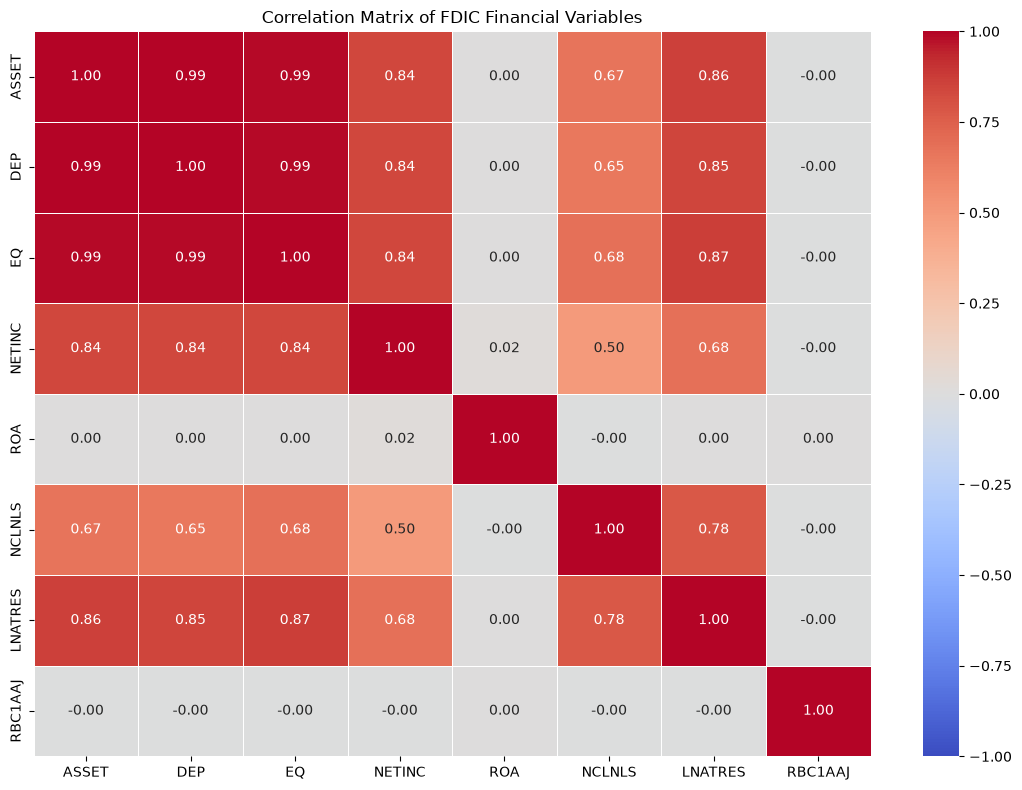

In [428]:
plt.figure(figsize=(11, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    vmin=-1,
    vmax=1,
    center=0
)

plt.title("Correlation Matrix of FDIC Financial Variables")
plt.tight_layout()

# Save the figure
FIGURE_DIR = PROJECT_ROOT / "reports" / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

plt.savefig(
    FIGURE_DIR / "correlation_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Correlation Analysis

The Pearson correlation matrix reveals several important relationships among the financial variables.

First, strong positive correlations are observed among bank size indicators. ASSET is highly correlated with DEP (0.995) and EQ (0.988), while DEP and EQ also show a strong correlation (0.986). This suggests that larger banks generally have higher deposit and equity values. However, these high correlations may create multicollinearity problems when the variables are simultaneously included in regression-based models.

Second, ROA shows very weak linear correlations with most other variables, with coefficients close to zero. This indicates that profitability ratios capture a different dimension of bank performance from absolute financial measures.

Finally, RBC1AAJ exhibits correlations close to zero with most variables. This result requires further investigation, particularly given the extreme values identified during the outlier analysis.

Overall, the correlation analysis suggests that bank size, profitability and other financial indicators capture different aspects of bank characteristics. Nevertheless, correlation alone cannot establish predictive importance or causal relationships. Further feature evaluation will be conducted during model development.

## 6. Distribution Analysis

This section examines the distributions of key financial variables using histograms and boxplots. The analysis helps identify skewness, dispersion and extreme observations, providing a basis for selecting appropriate transformations during feature engineering.

C:\Users\ADMIN\AppData\Local\Temp\ipykernel_19216\2049444792.py:6: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(values, vert=False)
C:\Users\ADMIN\AppData\Local\Temp\ipykernel_19216\2049444792.py:6: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(values, vert=False)
C:\Users\ADMIN\AppData\Local\Temp\ipykernel_19216\2049444792.py:6: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(values, vert=False)
C:\Users\ADMIN\AppData\Local\Temp\ipykernel_19216\2049444792.py:6: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.

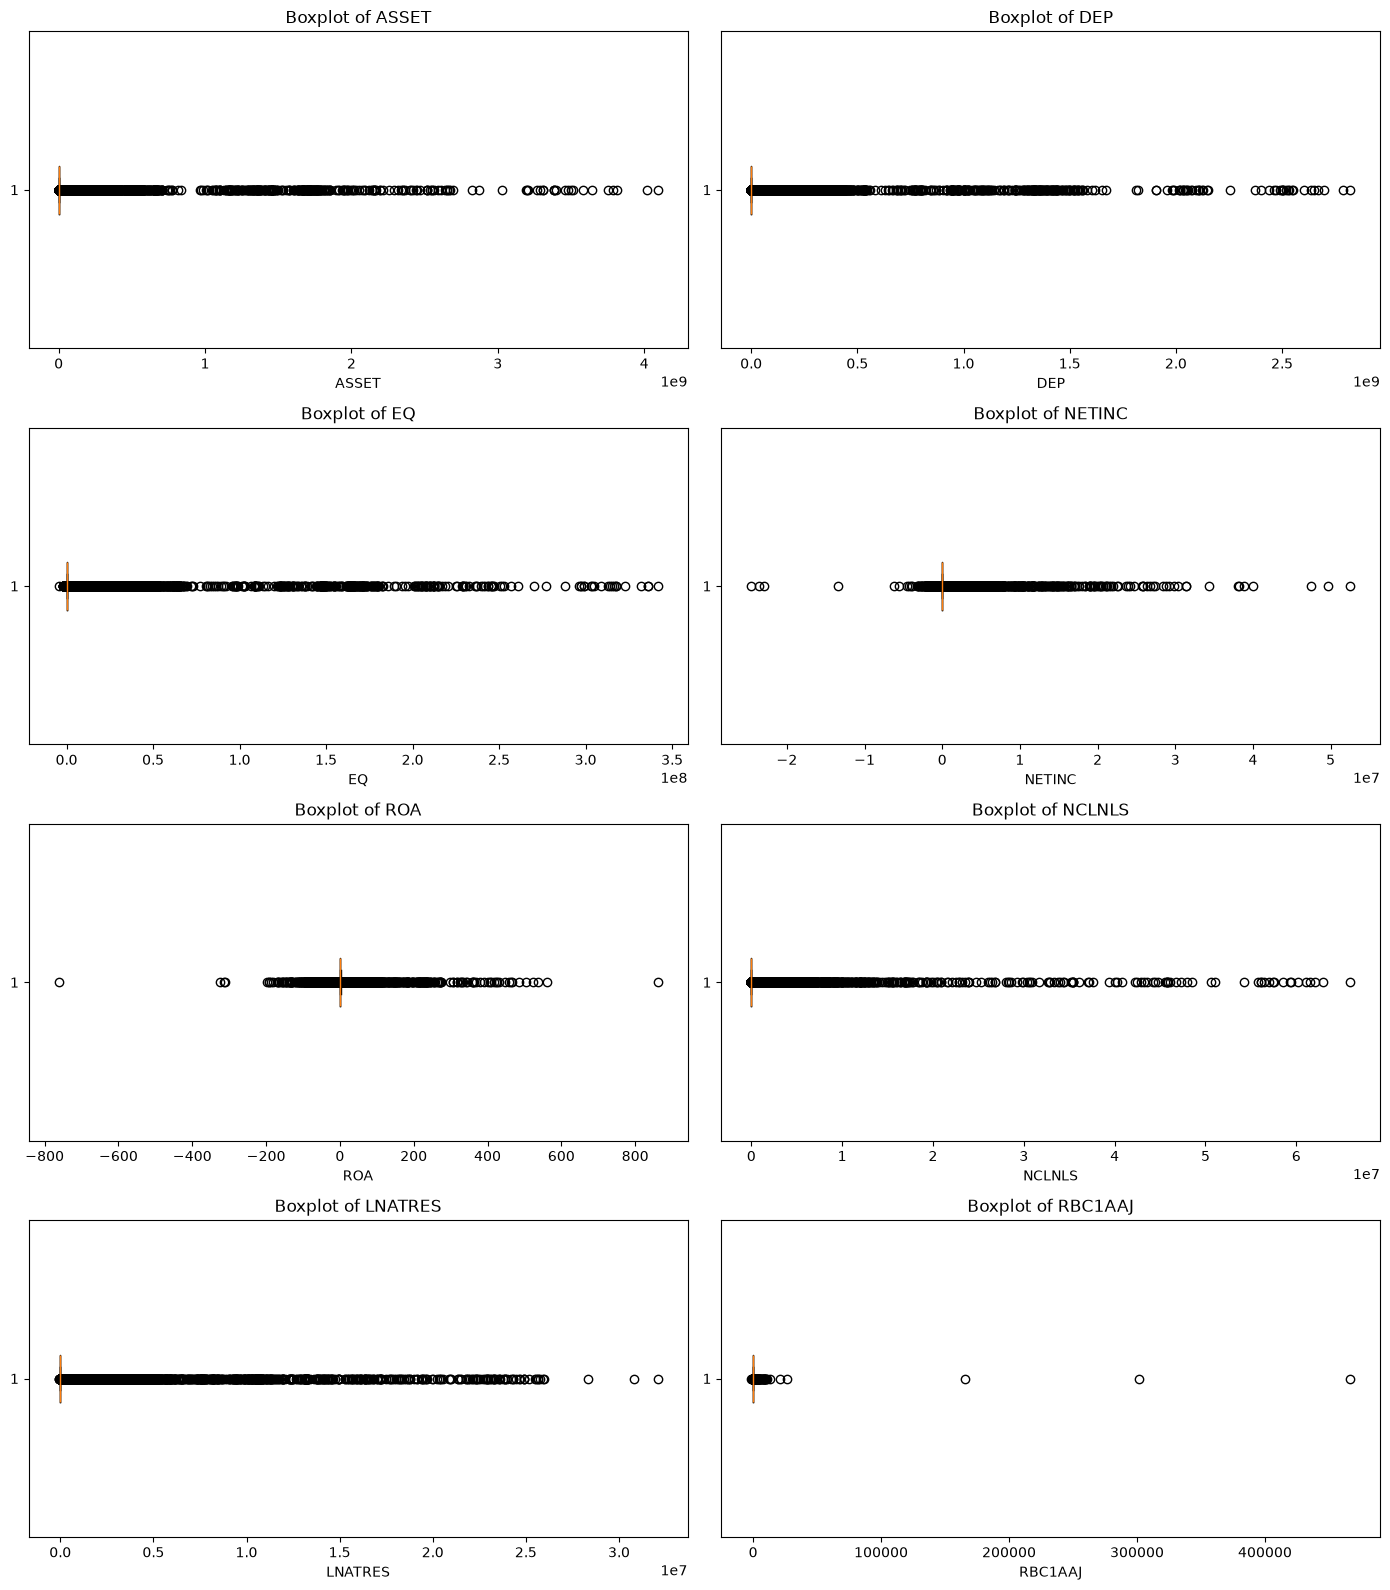

In [429]:
fig, axes = plt.subplots(4, 2, figsize=(14, 16))

for ax, column in zip(axes.flatten(), financial_variables):
    values = financials[column].drop_nulls().to_numpy()

    ax.boxplot(values, vert=False)
    ax.set_title(f"Boxplot of {column}")
    ax.set_xlabel(column)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "financial_variables_boxplots.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Boxplot Analysis

The boxplots provide further evidence of extreme observations across the financial variables. ASSET, DEP, EQ, NCLNLS and LNATRES contain numerous observations beyond the upper whiskers, reflecting substantial differences in bank size and financial characteristics.

NETINC and ROA exhibit extreme observations on both sides of their distributions, indicating considerable variation in profitability. RBC1AAJ also contains several observations located far from the central distribution, which requires additional data validation.

These observations are identified using the conventional 1.5 × IQR rule. However, an observation outside the whiskers is not necessarily an error. Given the heterogeneous sizes and financial conditions of banks, automatically removing these observations could eliminate economically meaningful information.

Therefore, the original observations are retained at this stage. Any subsequent transformation or treatment of extreme values will be evaluated during feature engineering using training data only.

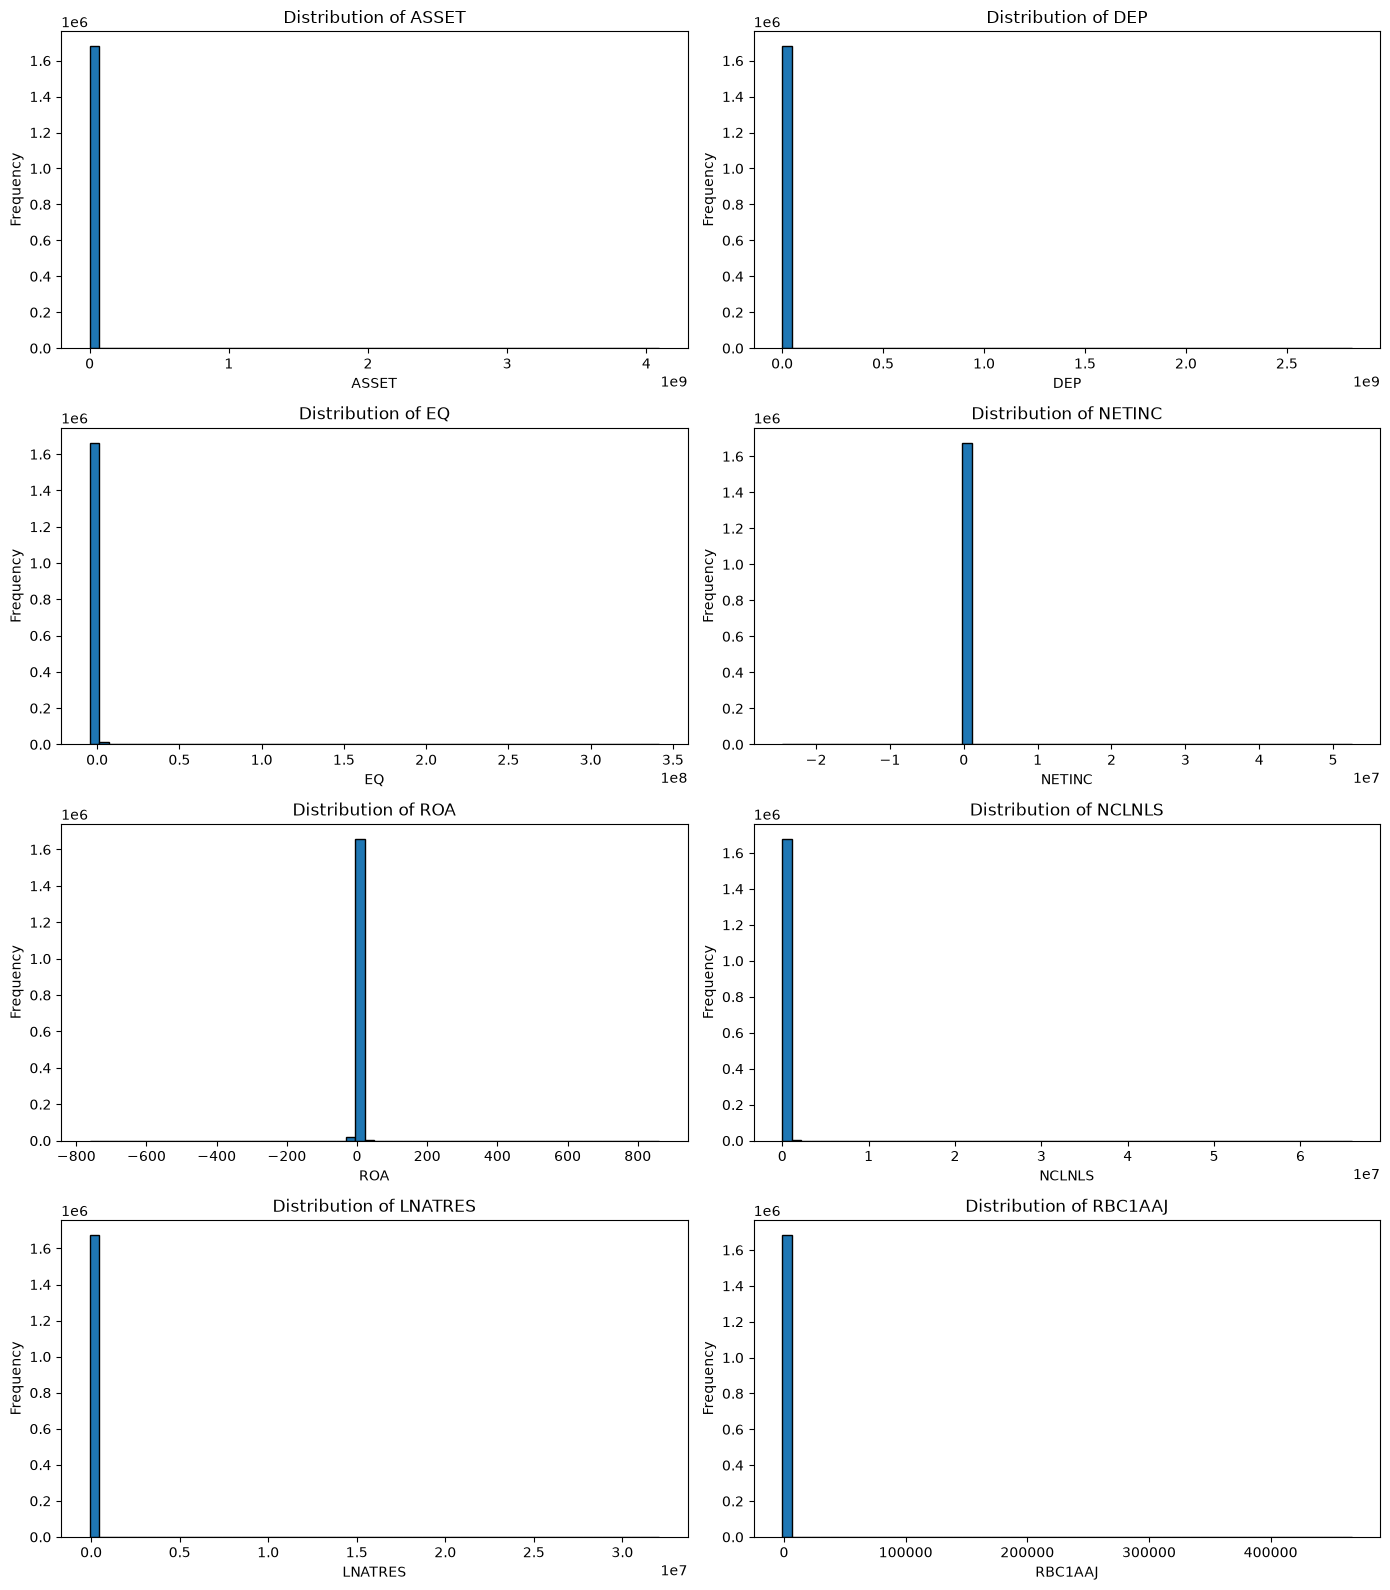

In [430]:
import matplotlib.pyplot as plt
import numpy as np

# Create a 4 x 2 grid of histograms
fig, axes = plt.subplots(4, 2, figsize=(14, 16))

for ax, column in zip(axes.flatten(), financial_variables):
    values = financials[column].drop_nulls().to_numpy()

    ax.hist(values, bins=60, edgecolor="black")
    ax.set_title(f"Distribution of {column}")
    ax.set_xlabel(column)
    ax.set_ylabel("Frequency")

# Hide unused axes if there are fewer than 8 variables
for ax in axes.flatten()[len(financial_variables):]:
    ax.set_visible(False)

plt.tight_layout()

# Save figure
FIGURE_DIR = PROJECT_ROOT / "reports" / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

plt.savefig(
    FIGURE_DIR / "financial_variables_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Histogram Analysis

Histograms are used to examine the distribution and frequency of observations across the selected financial variables.

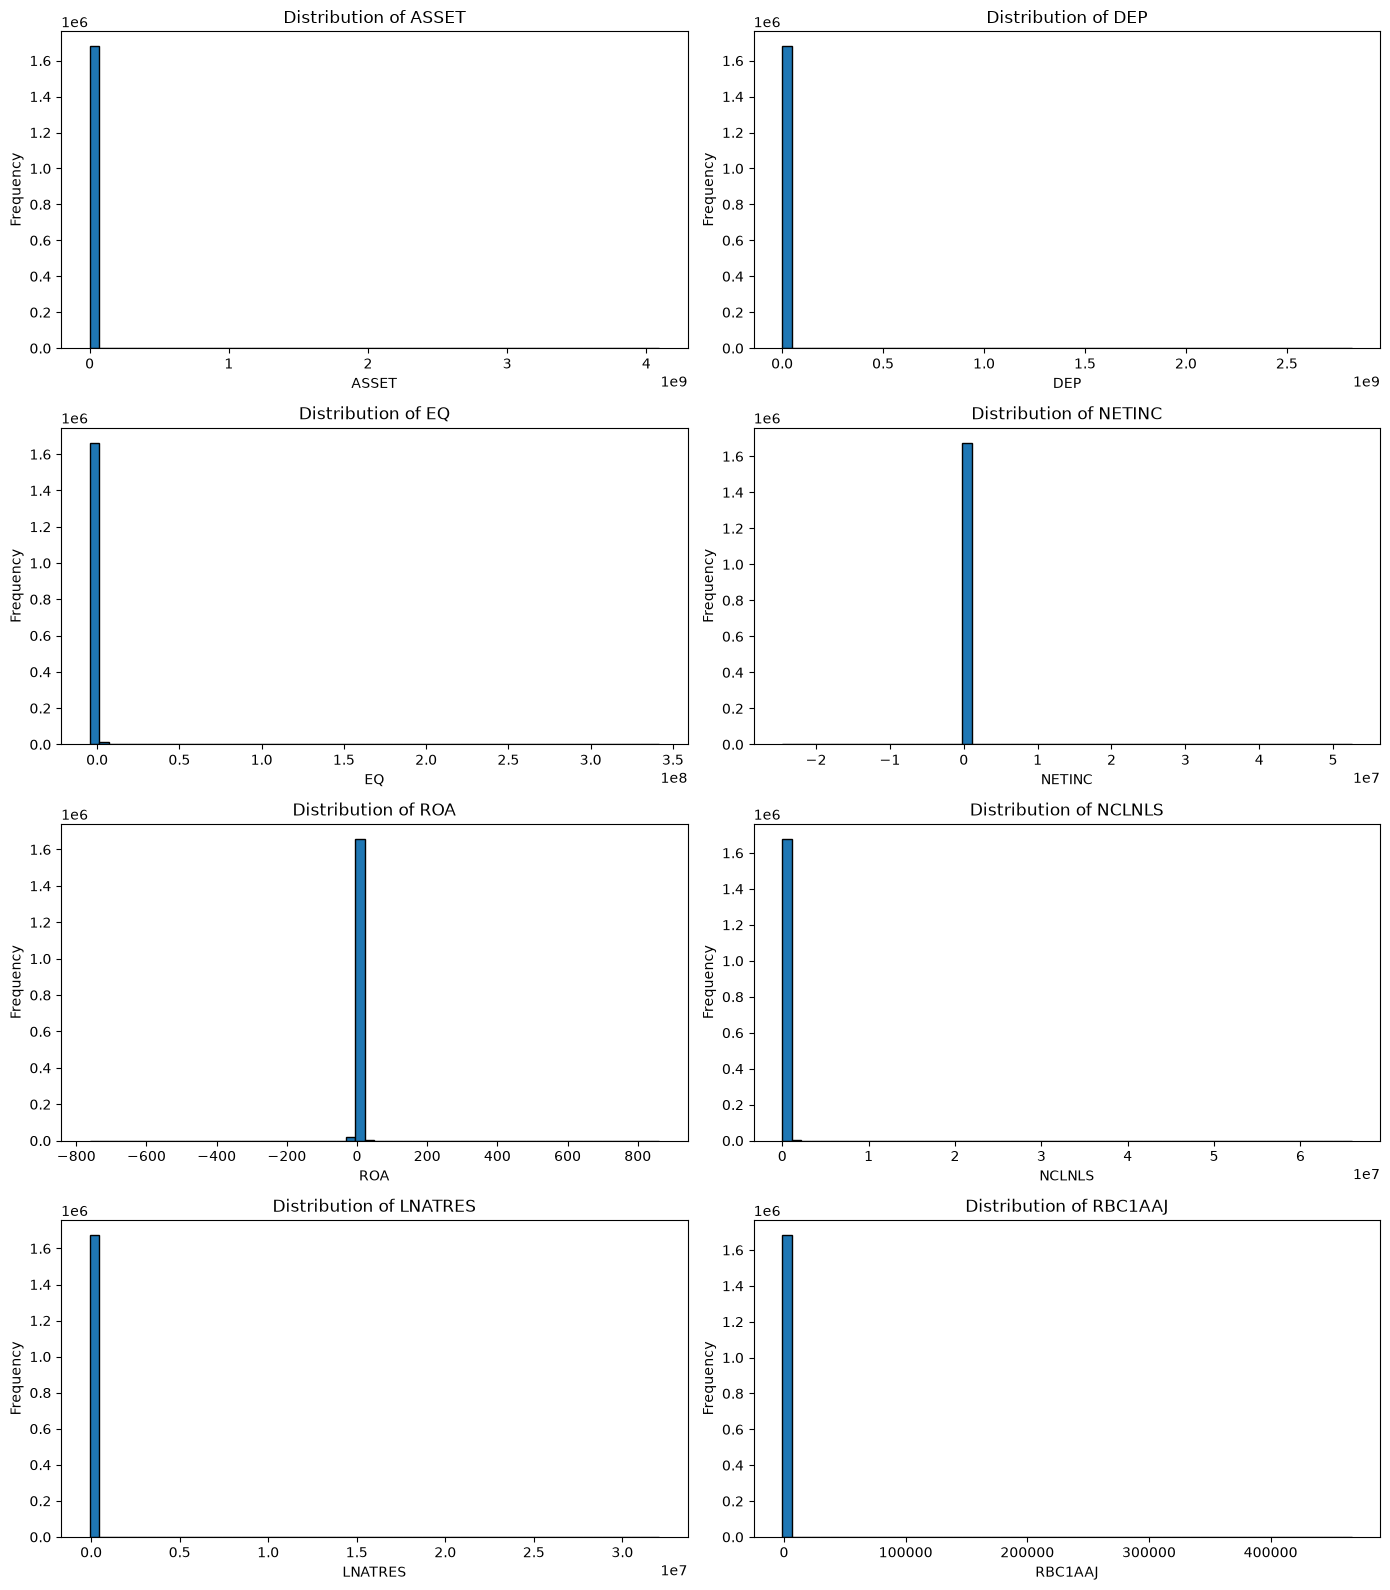

In [431]:
import matplotlib.pyplot as plt
import numpy as np

# Create a 4 x 2 grid of histograms
fig, axes = plt.subplots(4, 2, figsize=(14, 16))

for ax, column in zip(axes.flatten(), financial_variables):
    values = financials[column].drop_nulls().to_numpy()

    ax.hist(values, bins=60, edgecolor="black")
    ax.set_title(f"Distribution of {column}")
    ax.set_xlabel(column)
    ax.set_ylabel("Frequency")

# Hide unused axes if there are fewer than 8 variables
for ax in axes.flatten()[len(financial_variables):]:
    ax.set_visible(False)

plt.tight_layout()

# Save figure
FIGURE_DIR = PROJECT_ROOT / "reports" / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

plt.savefig(
    FIGURE_DIR / "financial_variables_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

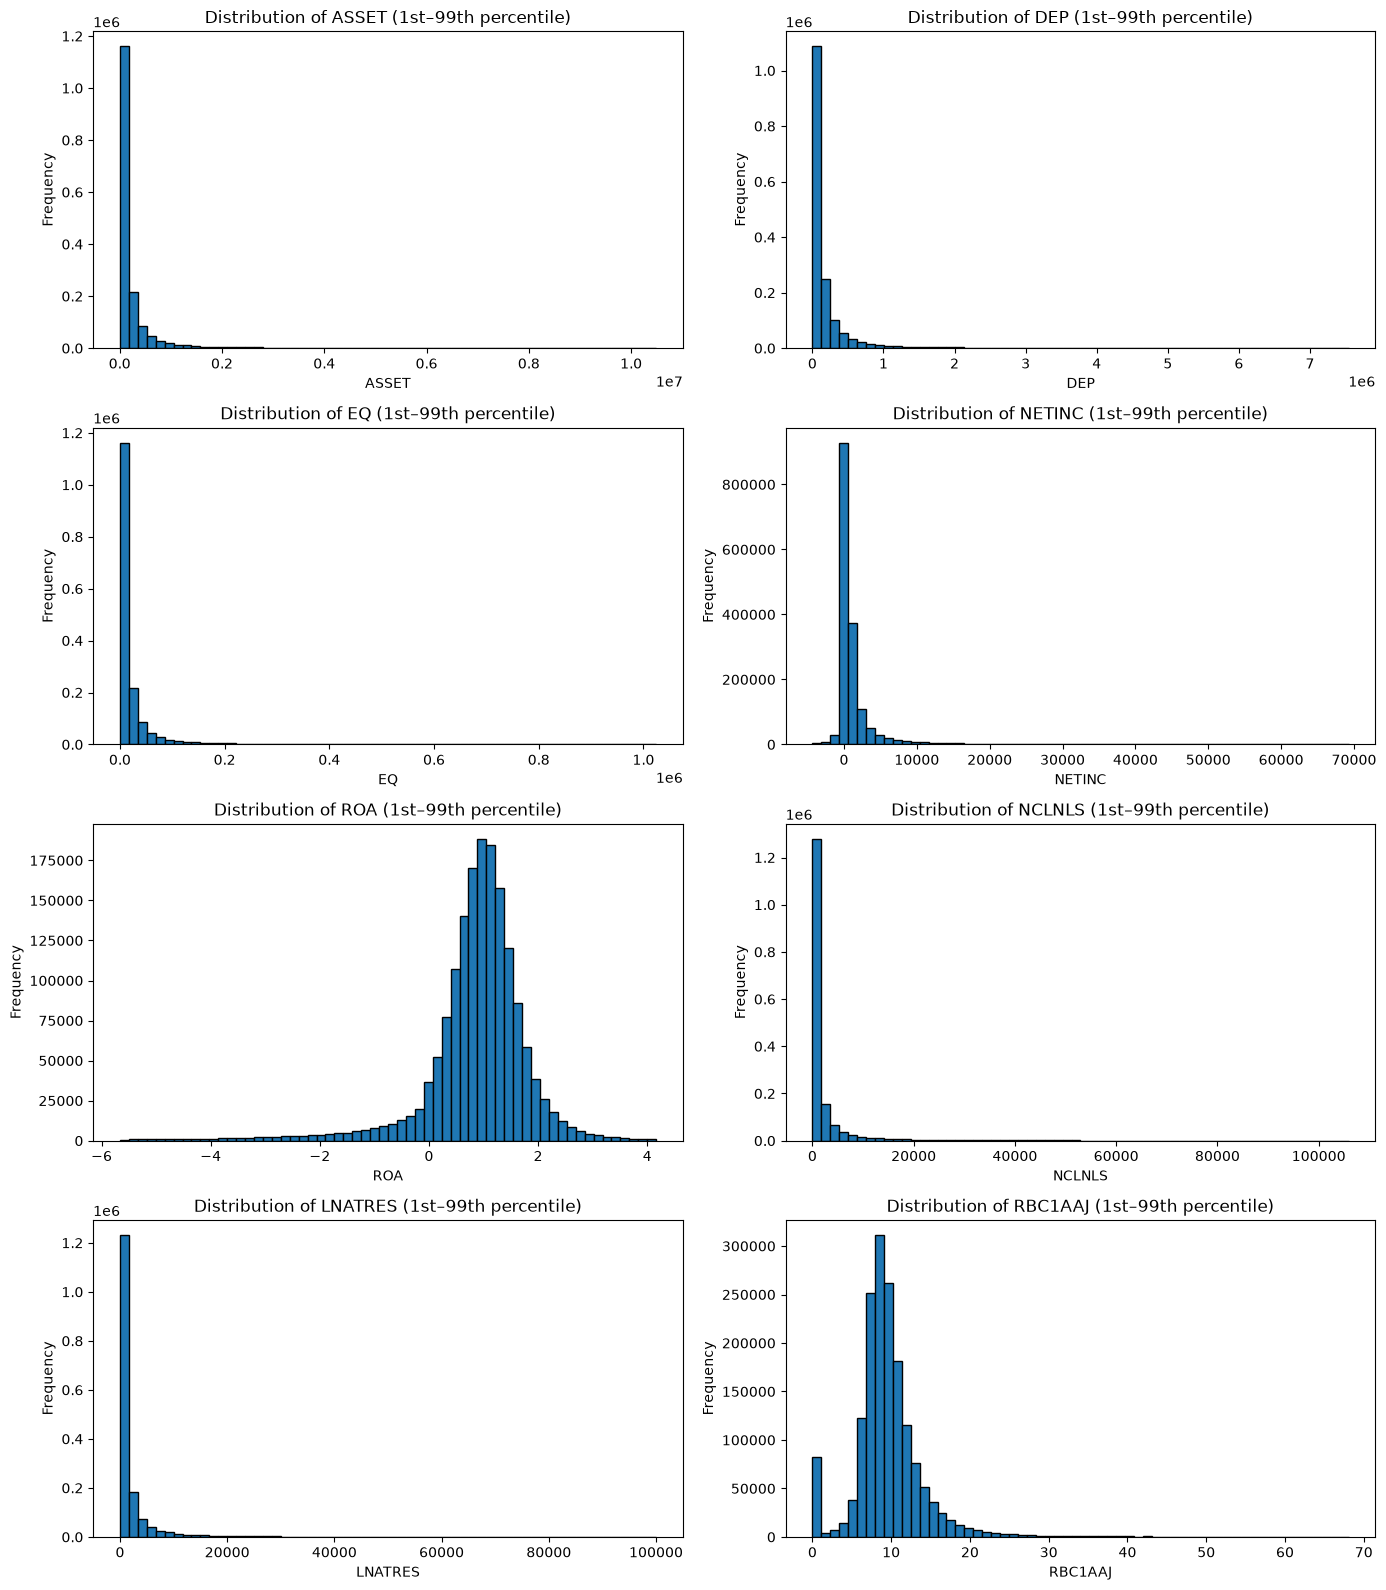

In [432]:
import matplotlib.pyplot as plt
import numpy as np

financial_variables = [
    "ASSET", "DEP", "EQ", "NETINC",
    "ROA", "NCLNLS", "LNATRES", "RBC1AAJ"
]

fig, axes = plt.subplots(4, 2, figsize=(14, 16))

for ax, column in zip(axes.flatten(), financial_variables):

    values = financials[column].drop_nulls().to_numpy()

    # Calculate 1st and 99th percentiles for visualization
    lower = np.percentile(values, 1)
    upper = np.percentile(values, 99)

    # Plot only the central 98% range
    visible_values = values[
        (values >= lower) & (values <= upper)
    ]

    ax.hist(visible_values, bins=60, edgecolor="black")
    ax.set_title(f"Distribution of {column} (1st–99th percentile)")
    ax.set_xlabel(column)
    ax.set_ylabel("Frequency")

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "financial_variables_distribution_zoomed.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Distribution Analysis

The histograms reveal substantial differences in the distributions of the financial variables.

ASSET, DEP and EQ exhibit strong positive skewness, indicating that most banks have relatively small financial values, while a limited number of large institutions account for the long right tails. NETINC and the risk-related variables NCLNLS and LNATRES also display right-skewed distributions, although their values include both positive and negative observations.

ROA shows a more concentrated, approximately bell-shaped distribution. However, extreme observations remain present in both tails. RBC1AAJ is mainly concentrated around values between approximately 7 and 12, with a noticeable right tail and some observations close to zero.

These findings suggest that a single transformation method may not be appropriate for all variables. Logarithmic transformations may be considered for suitable non-negative size variables, while variables containing negative values require alternative approaches. Extreme observations will be retained at this stage, pending further data validation and feature engineering.

## 7. Temporal Analysis

This section examines changes in bank financial characteristics over time.

Annual median values are used to reduce the influence of extreme observations and differences in bank size. The analysis focuses on total assets and net income to explore long-term trends in bank size and profitability.

In [433]:
import polars as pl
import matplotlib.pyplot as plt

# Convert reporting date from string to Date
financials_temporal = financials.with_columns(
    pl.col("REPDTE")
    .str.to_date("%Y%m%d")
    .alias("REPORT_DATE")
)

# Extract calendar year
financials_temporal = financials_temporal.with_columns(
    pl.col("REPORT_DATE").dt.year().alias("YEAR")
)

# Calculate annual median financial indicators
annual_trends = (
    financials_temporal
    .group_by("YEAR")
    .agg([
        pl.col("ASSET").median().alias("MEDIAN_ASSET"),
        pl.col("NETINC").median().alias("MEDIAN_NETINC"),
        pl.col("CERT").n_unique().alias("NUMBER_OF_BANKS")
    ])
    .sort("YEAR")
)

display(annual_trends)

YEAR,MEDIAN_ASSET,MEDIAN_NETINC,NUMBER_OF_BANKS
i32,f64,f64,u32
1984,38760.0,166.0,18330
1985,41307.0,207.0,18502
1986,43904.5,185.0,18409
1987,45988.0,170.0,18052
1988,48053.0,181.0,17469
1989,50139.0,202.0,16804
1990,52706.0,190.0,16309
1991,55011.0,213.0,15467
1992,57648.0,312.0,14588


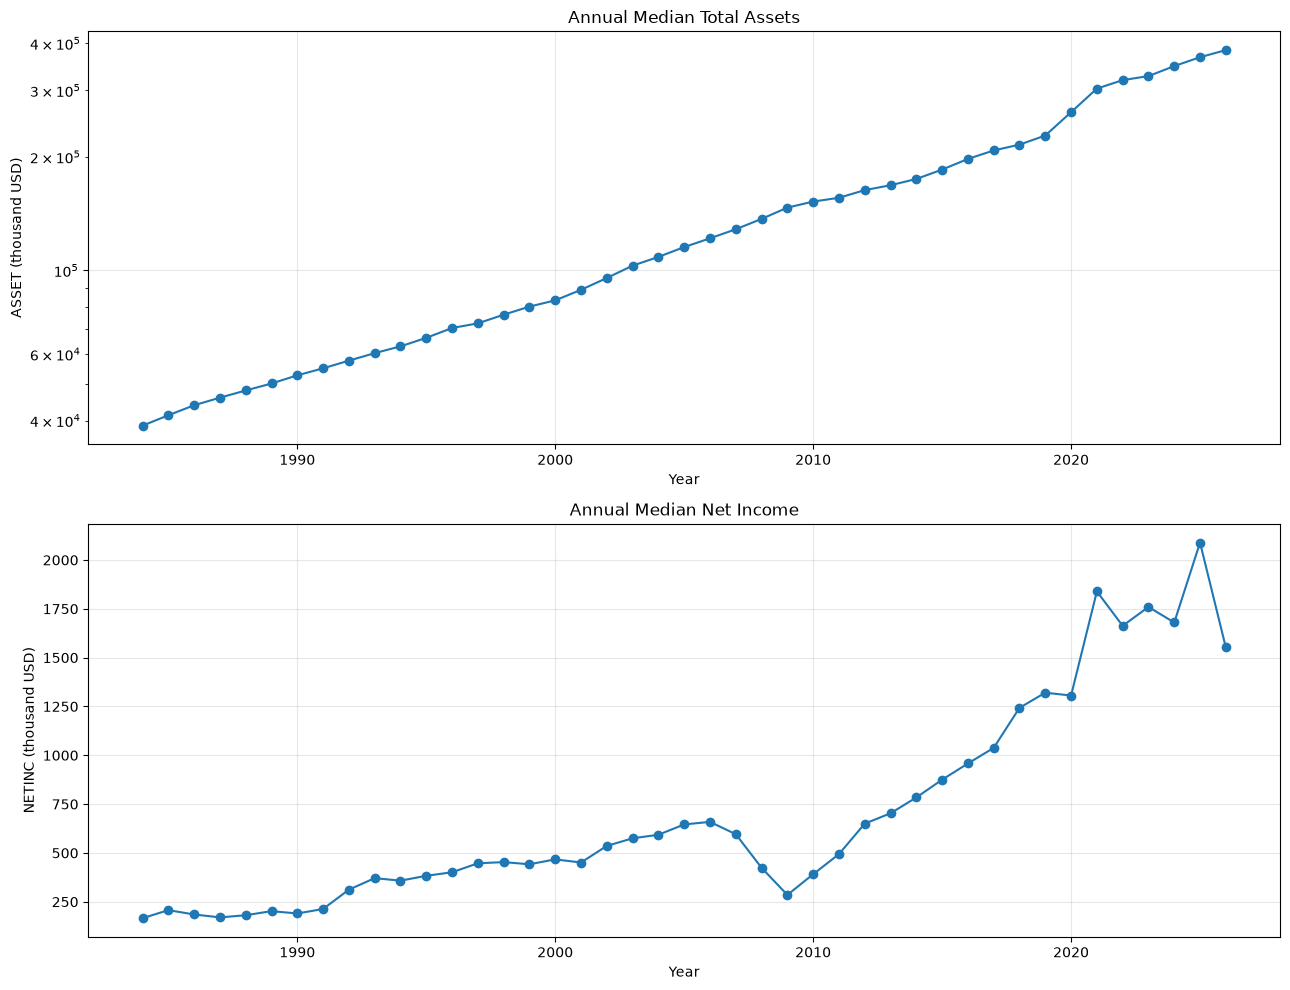

In [434]:
fig, axes = plt.subplots(2, 1, figsize=(13, 10))

# Annual median assets
axes[0].plot(
    annual_trends["YEAR"].to_list(),
    annual_trends["MEDIAN_ASSET"].to_list(),
    marker="o"
)

axes[0].set_title("Annual Median Total Assets")
axes[0].set_xlabel("Year")
axes[0].set_ylabel("ASSET (thousand USD)")
axes[0].set_yscale("log")
axes[0].grid(True, alpha=0.3)

# Annual median net income
axes[1].plot(
    annual_trends["YEAR"].to_list(),
    annual_trends["MEDIAN_NETINC"].to_list(),
    marker="o"
)

axes[1].set_title("Annual Median Net Income")
axes[1].set_xlabel("Year")
axes[1].set_ylabel("NETINC (thousand USD)")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "annual_financial_trends.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Annual Financial Trends

The annual trend analysis reveals a substantial increase in median bank assets over the observation period. Median ASSET rose from approximately USD 38.76 million in 1984 to USD 383.75 million in 2026, indicating a long-term increase in the nominal size of reporting banks.

In contrast, median NETINC exhibits greater fluctuations. It increased gradually until 2007, followed by a notable decline during 2008–2009. Profitability subsequently recovered, although further fluctuations occurred in recent years.

The number of reporting banks also declined considerably, from 18,330 in 1984 to 4,358 in 2026. This changing sample composition may influence the annual median values and should be considered when interpreting long-term trends.

The results should be interpreted cautiously because financial values are nominal and have not been adjusted for inflation. Furthermore, 2026 contains observations only through the second quarter and is therefore an incomplete year.

In [435]:
import polars as pl

FAILURES_PATH = PROJECT_ROOT / "data" / "raw" / "failures" / "failures.parquet"

failures = pl.read_parquet(FAILURES_PATH)

print("Số dòng:", failures.height)
print("Các cột:", failures.columns)
print(failures.head())

Số dòng: 4117
Các cột: ['COST', 'FAILDATE', 'CERT', 'ID']
shape: (5, 4)
┌──────────┬────────────┬─────────┬──────┐
│ COST     ┆ FAILDATE   ┆ CERT    ┆ ID   │
│ ---      ┆ ---        ┆ ---     ┆ ---  │
│ f64      ┆ str        ┆ f64     ┆ str  │
╞══════════╪════════════╪═════════╪══════╡
│ null     ┆ 5/28/1934  ┆ null    ┆ 1    │
│ null     ┆ 1/3/1935   ┆ null    ┆ 10   │
│ null     ┆ 12/21/1936 ┆ null    ┆ 100  │
│ 1653.25  ┆ 5/31/1985  ┆ 13797.0 ┆ 1000 │
│ 1656.232 ┆ 5/31/1985  ┆ 18388.0 ┆ 1001 │
└──────────┴────────────┴─────────┴──────┘


In [436]:
# Tạo số vụ ngân hàng thất bại theo năm
annual_failures = (
    failures
    .with_columns(
        pl.col("FAILDATE")
        .str.strptime(pl.Date, format="%m/%d/%Y", strict=False)
        .dt.year()
        .alias("FAILURE_YEAR")
    )
    .filter(pl.col("FAILURE_YEAR").is_not_null())
    .group_by("FAILURE_YEAR")
    .agg(pl.len().alias("NUMBER_OF_FAILURE_EVENTS"))
    .sort("FAILURE_YEAR")
)

print(annual_failures.head())
print("Số năm:", annual_failures.height)

shape: (5, 2)
┌──────────────┬──────────────────────────┐
│ FAILURE_YEAR ┆ NUMBER_OF_FAILURE_EVENTS │
│ ---          ┆ ---                      │
│ i32          ┆ u32                      │
╞══════════════╪══════════════════════════╡
│ 1934         ┆ 9                        │
│ 1935         ┆ 25                       │
│ 1936         ┆ 69                       │
│ 1937         ┆ 75                       │
│ 1938         ┆ 74                       │
└──────────────┴──────────────────────────┘
Số năm: 88


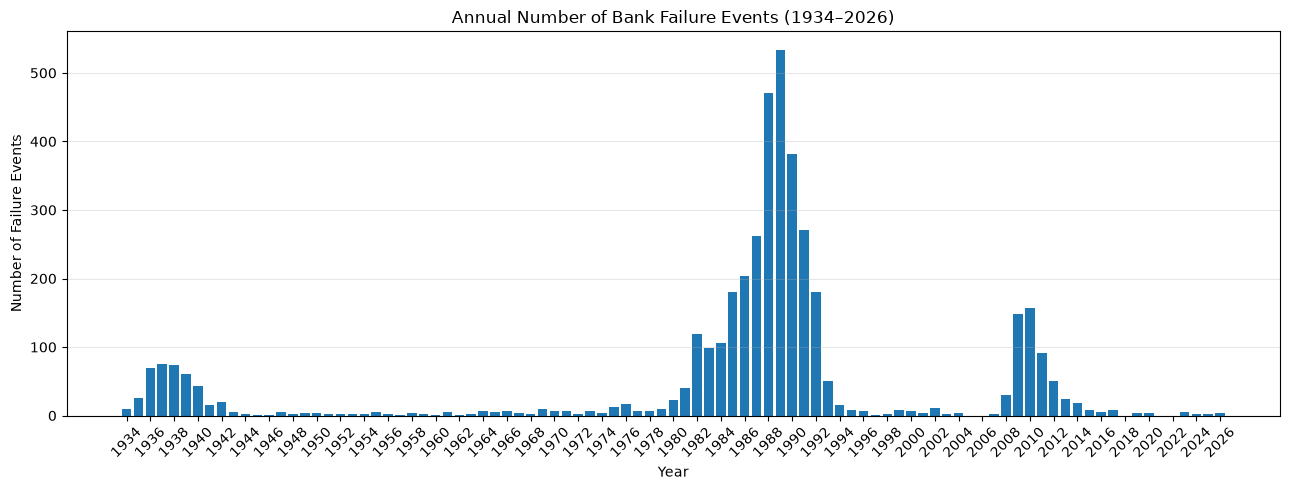

In [437]:
# Visualise annual bank failure events
START_YEAR = int(annual_failures["FAILURE_YEAR"].min())
END_YEAR = int(annual_failures["FAILURE_YEAR"].max())
plt.figure(figsize=(13, 5))

plt.bar(
    annual_failures["FAILURE_YEAR"].to_list(),
    annual_failures["NUMBER_OF_FAILURE_EVENTS"].to_list()
)

plt.title(
    f"Annual Number of Bank Failure Events ({START_YEAR}–{END_YEAR})"
)
plt.xlabel("Year")
plt.ylabel("Number of Failure Events")
plt.xticks(
    range(START_YEAR, END_YEAR + 1, 2),
    rotation=45
)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

### Changes in the Number of Reporting Banks

The number of reporting banks declined substantially over the observation period, falling from 18,330 in 1984 to 4,358 in 2026, representing a decrease of approximately 76.2%.

The decline was particularly pronounced between 1984 and 2000. The number of reporting institutions continued to decrease throughout the following decades, although at a relatively more gradual pace.

This trend may reflect industry consolidation, mergers and bank closures. However, the annual counts represent institutions with available financial observations rather than a complete historical record of bank exits. Therefore, the decline should not be interpreted as a direct measure of bank failures.

The changing sample composition is an important consideration when interpreting annual median financial indicators, as the characteristics of reporting institutions may have changed over time.

## 8. Bank Failure Analysis

This section examines historical bank failure events using the FDIC Failure database.

The analysis focuses on the annual distribution of bank failures and their relationship with historical financial reporting data.

Only records classified as FAILURE are treated as bank failure events. ASSISTANCE records are excluded from the failure label to avoid confusing assisted transactions with actual bank failures.

In [438]:
import polars as pl

FAILURE_FILE = (
    PROJECT_ROOT
    / "data"
    / "raw"
    / "failures"
    / "failures_enriched.parquet"
)

failures = pl.read_parquet(FAILURE_FILE)

print("Failure dataset shape:", failures.shape)
print("\nDataset schema:")
print(failures.schema)

print("\nResolution type distribution:")
display(
    failures
    .group_by("RESTYPE")
    .agg(pl.len().alias("NUMBER_OF_RECORDS"))
    .sort("NUMBER_OF_RECORDS", descending=True)
)

Failure dataset shape: (4117, 9)

Dataset schema:
Schema({'COST': Float64, 'FIN': String, 'FAILDATE': String, 'CERT': Float64, 'CITYST': String, 'RESTYPE': String, 'RESTYPE1': String, 'NAME': String, 'ID': String})

Resolution type distribution:


RESTYPE,NUMBER_OF_RECORDS
str,u32
"""FAILURE""",3524
"""ASSISTANCE""",593


In [439]:
# Prepare and audit actual bank failure events

import polars as pl

# Load the enriched FDIC failure dataset
FAILURE_FILE = (
    PROJECT_ROOT
    / "data"
    / "raw"
    / "failures"
    / "failures_enriched.parquet"
)

assert FAILURE_FILE.exists(), (
    f"Failure dataset not found: {FAILURE_FILE}"
)

failures = pl.read_parquet(FAILURE_FILE)

# Keep actual failure events and parse failure dates
failure_events = (
    failures
    .filter(pl.col("RESTYPE") == "FAILURE")
    .with_columns(
        pl.col("FAILDATE")
        .cast(pl.String)
        .str.to_date("%m/%d/%Y", strict=False)
        .alias("FAILURE_DATE")
    )
    .with_columns(
        pl.col("FAILURE_DATE")
        .dt.year()
        .alias("FAILURE_YEAR")
    )
)

# Audit failure event date coverage
valid_failure_dates = (
    failure_events
    .filter(pl.col("FAILURE_DATE").is_not_null())
)

print("=== FAILURE EVENT DATA AUDIT ===")
print("Total failure events:", f"{failure_events.height:,}")
print("Events with valid dates:", f"{valid_failure_dates.height:,}")
print(
    "Events with missing or invalid dates:",
    f"{failure_events.height - valid_failure_dates.height:,}"
)

print("\nEarliest failure date:", valid_failure_dates["FAILURE_DATE"].min())
print("Latest failure date:", valid_failure_dates["FAILURE_DATE"].max())

print("\n=== FAILURE EVENTS BY YEAR ===")

display(
    valid_failure_dates
    .group_by("FAILURE_YEAR")
    .agg(
        pl.len().alias("NUMBER_OF_FAILURE_EVENTS")
    )
    .sort("FAILURE_YEAR")
)

=== FAILURE EVENT DATA AUDIT ===
Total failure events: 3,524
Events with valid dates: 3,524
Events with missing or invalid dates: 0

Earliest failure date: 1934-04-19
Latest failure date: 2026-07-17

=== FAILURE EVENTS BY YEAR ===


FAILURE_YEAR,NUMBER_OF_FAILURE_EVENTS
i32,u32
1934,9
1935,25
1936,69
1937,75
1938,74
1939,60
1940,43
1941,15
1942,20


### 8.1. Annual Distribution of Bank Failures

This subsection examines the annual distribution of FDIC-recorded bank failure events.

The analysis focuses on the period from 1984 to 2026, which overlaps with the available financial reporting dataset. Annual failure counts are used to identify periods of increased bank distress.

In [440]:
# Count annual failure events and unique institutions

START_YEAR = max(
    1984,
    int(valid_failure_dates["FAILURE_YEAR"].min())
)

END_YEAR = int(
    valid_failure_dates["FAILURE_YEAR"].max()
)

annual_failures = (
    valid_failure_dates
    .filter(
        pl.col("FAILURE_YEAR").is_between(
            START_YEAR,
            END_YEAR
        )
    )
    .group_by("FAILURE_YEAR")
    .agg(
        pl.len().alias("NUMBER_OF_FAILURE_EVENTS"),
        pl.col("CERT")
        .drop_nulls()
        .n_unique()
        .alias("NUMBER_OF_UNIQUE_BANKS")
    )
    .sort("FAILURE_YEAR")
)

print("=== ANNUAL BANK FAILURE DISTRIBUTION ===")
print(f"Analysis period: {START_YEAR}–{END_YEAR}")

display(annual_failures)

print("\nYears with the highest number of failure events:")

display(
    annual_failures
    .sort("NUMBER_OF_FAILURE_EVENTS", descending=True)
    .head(10)
)

=== ANNUAL BANK FAILURE DISTRIBUTION ===
Analysis period: 1984–2026


FAILURE_YEAR,NUMBER_OF_FAILURE_EVENTS,NUMBER_OF_UNIQUE_BANKS
i32,u32,u32
1984,83,83
1985,139,139
1986,162,162
1987,217,217
1988,232,232
1989,530,530
1990,381,381
1991,268,268
1992,179,179



Years with the highest number of failure events:


FAILURE_YEAR,NUMBER_OF_FAILURE_EVENTS,NUMBER_OF_UNIQUE_BANKS
i32,u32,u32
1989,530,530
1990,381,381
1991,268,268
1988,232,232
1987,217,217
1992,179,179
1986,162,162
2010,157,157
2009,140,140


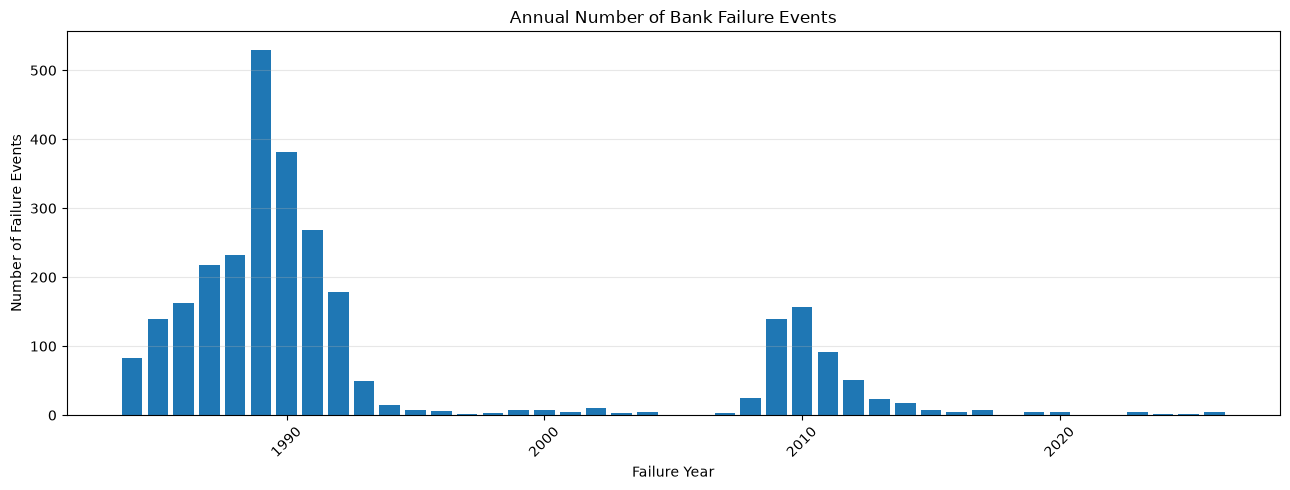

In [441]:
# Plot annual bank failure events in chronological order
annual_failures_plot = annual_failures.sort("FAILURE_YEAR")

plt.figure(figsize=(13, 5))

plt.bar(
    annual_failures_plot["FAILURE_YEAR"].to_list(),
    annual_failures_plot["NUMBER_OF_FAILURE_EVENTS"].to_list()
)

plt.title("Annual Number of Bank Failure Events")
plt.xlabel("Failure Year")
plt.ylabel("Number of Failure Events")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### 8.1. Annual Distribution of Bank Failures

The annual distribution shows that bank failure events were concentrated in specific historical periods rather than being evenly distributed over time.

The annual counts identify periods of elevated bank failure activity. The distinction between the number of failure events and the number of unique institutions is important because multiple records may not necessarily represent different banks.

These patterns indicate that bank failures have a strong temporal dimension. Therefore, chronological data splitting and time-aware validation are important when developing an early warning model.

The analysis covers the period overlapping with the available financial reporting dataset. The final observation year may be incomplete and should not be directly compared with full calendar years.

In [442]:
# Create a complete annual timeline

all_years = pl.DataFrame({
    "FAILURE_YEAR": pl.Series(
        range(START_YEAR, END_YEAR + 1),
        dtype=pl.Int32
    )
})

annual_failures_complete = (
    all_years
    .join(
        annual_failures,
        on="FAILURE_YEAR",
        how="left"
    )
    .with_columns(
        pl.col("NUMBER_OF_FAILURE_EVENTS").fill_null(0),
        pl.col("NUMBER_OF_UNIQUE_BANKS").fill_null(0)
    )
    .sort("FAILURE_YEAR")
)

display(annual_failures_complete)

FAILURE_YEAR,NUMBER_OF_FAILURE_EVENTS,NUMBER_OF_UNIQUE_BANKS
i32,u32,u32
1984,83,83
1985,139,139
1986,162,162
1987,217,217
1988,232,232
1989,530,530
1990,381,381
1991,268,268
1992,179,179


### 8.2. Linking Failure Events to Financial Records

This subsection examines whether recorded bank failure events can be linked to historical financial statements using the FDIC Certificate Number (CERT).

Matching failure events to financial records is essential for constructing a bank-quarter panel and developing a reliable early warning label.

Events without a valid CERT or without historical financial observations cannot be directly included in the modeling sample.

In [443]:
# Link failure events to financial records using CERT

# Keep failure events with valid CERT and valid failure dates
failure_with_cert = (
    failure_events
    .filter(
        pl.col("CERT").is_not_null()
        & pl.col("FAILURE_DATE").is_not_null()
    )
    .with_columns(
        pl.col("CERT").cast(pl.Int64, strict=False)
    )
    .filter(pl.col("CERT").is_not_null())
)

# Standardise CERT data type in the Financials dataset
financial_certs = (
    financials
    .select(
        pl.col("CERT").cast(pl.Int64, strict=False)
    )
    .filter(pl.col("CERT").is_not_null())
    .unique()
)

failure_certs = (
    failure_with_cert
    .select("CERT")
    .unique()
)

# Identify matched and unmatched institutions
matched_certs = failure_certs.join(
    financial_certs,
    on="CERT",
    how="inner"
)

unmatched_certs = failure_certs.join(
    financial_certs,
    on="CERT",
    how="anti"
)

# Summarise linkage results
total_failure_events = failure_events.height
events_with_valid_cert = failure_with_cert.height
events_without_cert = (
    failure_events
    .filter(pl.col("CERT").is_null())
    .height
)

print("=== FAILURE–FINANCIALS LINKAGE AUDIT ===")
print(f"Total failure events: {total_failure_events:,}")
print(f"Events with valid CERT: {events_with_valid_cert:,}")
print(f"Events without CERT: {events_without_cert:,}")
print(f"Unique failure institutions: {failure_certs.height:,}")
print(f"Institutions matched with Financials: {matched_certs.height:,}")
print(f"Institutions not found in Financials: {unmatched_certs.height:,}")

if failure_certs.height > 0:
    match_rate = matched_certs.height / failure_certs.height * 100
    print(f"Institution-level matching rate: {match_rate:.2f}%")

=== FAILURE–FINANCIALS LINKAGE AUDIT ===
Total failure events: 3,524
Events with valid CERT: 3,039
Events without CERT: 485
Unique failure institutions: 3,036
Institutions matched with Financials: 2,841
Institutions not found in Financials: 195
Institution-level matching rate: 93.58%


### 8.2. Linking Failure Events to Financial Records

Failure events are linked to historical financial statements using the FDIC Certificate Number (CERT).

The linkage audit distinguishes between the number of failure events and the number of unique institutions. This distinction is necessary because event counts and institution counts are not equivalent.

Institutions with valid CERT identifiers are classified into matched and unmatched groups based on whether their identifiers appear in the Financials dataset.

Events without valid CERT identifiers cannot be linked directly using this identifier. Similarly, institutions without historical financial records cannot contribute financial observations to the bank-quarter panel.

The original failure records are retained for audit purposes, while only institutions with suitable financial histories can be used in the financial-panel construction process.

### 8.3. Financial Reporting History Before Bank Failure

This subsection examines the timing of the last available financial report before each bank's first recorded failure.

The reporting gap is measured in days between the last financial reporting date and the failure date. This helps assess whether historical financial information is sufficiently recent for early warning analysis.

In [444]:
# Prepare financial reporting dates
financial_dates = (
    financials
    .with_columns(
        pl.col("REPDTE")
        .str.to_date("%Y%m%d", strict=False)
        .alias("REPORT_DATE")
    )
    .select(["CERT", "REPORT_DATE"])
)

# Use the earliest recorded failure date for each CERT
first_failures = (
    failure_with_cert
    .group_by("CERT")
    .agg(
        pl.col("FAILURE_DATE").min().alias("FIRST_FAILURE_DATE")
    )
)

# Match financial reports with first failure dates
reporting_history = (
    financial_dates
    .join(first_failures, on="CERT", how="inner")
    .filter(
        pl.col("REPORT_DATE") < pl.col("FIRST_FAILURE_DATE")
    )
    .group_by("CERT")
    .agg(
        pl.col("REPORT_DATE").max().alias("LAST_REPORT_DATE"),
        pl.col("FIRST_FAILURE_DATE").first()
    )
    .with_columns(
        (
            pl.col("FIRST_FAILURE_DATE") -
            pl.col("LAST_REPORT_DATE")
        ).dt.total_days().alias("DAYS_BEFORE_FAILURE")
    )
)

print("Banks with prior financial reports:", reporting_history.height)

print("\nReporting gap statistics:")
display(
    reporting_history
    .select("DAYS_BEFORE_FAILURE")
    .to_pandas()
    .describe()
)

Banks with prior financial reports: 2839

Reporting gap statistics:


,DAYS_BEFORE_FAILURE
count,2839.000000
mean,57.501937
std,31.721112
min,1.000000
25%,31.000000
50%,58.000000
75%,77.000000
max,228.000000


### 8.3. Financial Reporting History Before Bank Failure

This analysis measures the time between each institution's last available financial report and its first recorded failure date.

Only financial reports dated before the first recorded failure are considered. For each institution, the most recent eligible report is selected to calculate the reporting gap in days.

The reporting gap provides an indication of how recently financial information was available before a failure event. However, it should not be interpreted as evidence that the financial statements can predict failure four quarters in advance.

The analysis is descriptive. Predictive performance must be assessed separately using the defined prediction horizon and a strictly chronological validation framework.

### First Recorded Failure Date by Institution

The first recorded failure date is defined as the earliest FDIC failure date associated with each institution's CERT identifier.

This institution-level date is used by the canonical dataset-building pipeline to construct the forward-looking failure target.

The transformation is implemented in `src/build_dataset.py` through the `load_first_failures()` function. Notebook 01 does not independently rebuild this intermediate dataset.

In [445]:
from pathlib import Path
import polars as pl

# Đường dẫn gốc của project
PROJECT_ROOT = Path(r"C:\Users\ADMIN\OneDrive\BFT65B_Final_Project")

# File panel được tạo bởi src/build_dataset.py
PANEL_PATH = PROJECT_ROOT / "data" / "processed" / "v3" / "bank_quarter_panel_v3.parquet"

if not PANEL_PATH.exists():
    raise FileNotFoundError(
        f"Không tìm thấy file panel:\n{PANEL_PATH}\n"
        "Hãy chạy bước build dataset trước."
    )

# Nạp dữ liệu vào model_panel
model_panel = pl.read_parquet(PANEL_PATH)

print("Đã nạp model_panel:", model_panel.shape)
print("Các cột:", model_panel.columns)

# Kiểm tra các cột cần dùng
required_cols = {"CERT", "FAILURE_LABEL", "FIRST_FAILURE_DATE"}
missing_cols = required_cols - set(model_panel.columns)

if missing_cols:
    raise ValueError(f"Panel thiếu các cột: {missing_cols}")

# Check positive labels at bank level
positive_banks = (
    model_panel
    .filter(pl.col("FAILURE_LABEL") == 1)
    .group_by("CERT")
    .agg(
        pl.len().alias("POSITIVE_QUARTERS"),
        pl.col("FIRST_FAILURE_DATE").min().alias("FIRST_FAILURE_DATE")
    )
    .sort("POSITIVE_QUARTERS", descending=True)
)

print("Số ngân hàng có positive label:", positive_banks.height)
display(positive_banks.head(10))

Đã nạp model_panel: (1663876, 18)
Các cột: ['NCLNLS', 'LNATRES', 'ROA', 'REPDTE', 'ASSET', 'RBC1AAJ', 'CERT', 'NETINC', 'EQ', 'DEP', 'ID', 'REPORT_DATE', 'REPORT_Q_INDEX', 'FIRST_FAILURE_DATE', 'FAILURE_Q_INDEX', 'FAILURE_LABEL', 'IS_MERGER_CENSORED', 'FINAL_LABEL']
Số ngân hàng có positive label: 2837


CERT,POSITIVE_QUARTERS,FIRST_FAILURE_DATE
i64,u32,date
31893,4,1987-03-20
32030,4,1989-11-16
28347,4,1991-04-05
30452,4,1989-08-17
29892,4,1993-01-29
4731,4,2009-12-11
23631,4,1993-03-04
32554,4,1989-03-16
27808,4,2010-09-17


In [446]:
# Identify banks with fewer than 4 positive quarters

incomplete_positive_banks = (
    positive_banks
    .filter(pl.col("POSITIVE_QUARTERS") < 4)
    .sort("POSITIVE_QUARTERS")
)

print(
    "Banks with fewer than 4 positive quarters:",
    incomplete_positive_banks.height
)

print("\nDistribution:")
display(
    incomplete_positive_banks
    .group_by("POSITIVE_QUARTERS")
    .len()
    .sort("POSITIVE_QUARTERS")
)

print("\nExamples:")
display(incomplete_positive_banks.head(15))

Banks with fewer than 4 positive quarters: 397

Distribution:


POSITIVE_QUARTERS,len
u32,u32
1,29
2,33
3,335



Examples:


CERT,POSITIVE_QUARTERS,FIRST_FAILURE_DATE
i64,u32,date
9009,1,1984-06-15
10480,1,1984-08-10
24098,1,1984-05-24
4424,1,1984-06-21
17036,1,1984-05-11
23362,1,1984-06-08
9175,1,1984-06-27
32630,1,1989-03-16
9312,1,1984-04-19


In [447]:
# Investigate why some banks have fewer than 4 positive quarters

import polars as pl

# Convert REPDTE (YYYYMMDD) into a proper Date column
financials_with_date = financials.with_columns(
    pl.col("REPDTE")
    .cast(pl.String)
    .str.to_date("%Y%m%d", strict=False)
    .alias("REPORT_DATE")
)

# Summarize each bank's reporting-date coverage
reporting_coverage = (
    financials_with_date
    .group_by("CERT")
    .agg(
        pl.col("REPORT_DATE").min().alias("FIRST_REPORT_DATE"),
        pl.col("REPORT_DATE").max().alias("LAST_REPORT_DATE")
    )
)

incomplete_audit = (
    incomplete_positive_banks
    .join(
        reporting_coverage,
        on="CERT",
        how="left"
    )
    .with_columns(
        (
            pl.col("FIRST_FAILURE_DATE").dt.year() * 4
            + ((pl.col("FIRST_FAILURE_DATE").dt.month() - 1) // 3)
        ).alias("FAILURE_Q_INDEX"),
        (
            pl.col("FIRST_REPORT_DATE").dt.year() * 4
            + ((pl.col("FIRST_REPORT_DATE").dt.month() - 1) // 3)
        ).alias("FIRST_REPORT_Q_INDEX")
    )
    .with_columns(
        (pl.col("FAILURE_Q_INDEX") - 1).alias("LAST_POSITIVE_Q_INDEX")
    )
    .with_columns(
        pl.min_horizontal(
            pl.col("FIRST_REPORT_Q_INDEX"),
            pl.col("FAILURE_Q_INDEX") - 4
        ).alias("CHECK_START")
    )
    .with_columns(
        (
            pl.col("LAST_POSITIVE_Q_INDEX")
            - pl.col("CHECK_START")
            + 1
        ).alias("EXPECTED_QUARTERS")
    )
)

print("Audit records:", incomplete_audit.height)

print("\nDistribution by first report date:")
display(
    incomplete_audit
    .group_by(
        pl.col("FIRST_REPORT_DATE").dt.year().alias("FIRST_REPORT_YEAR")
    )
    .len()
    .sort("FIRST_REPORT_YEAR")
)

print("\nExamples:")
display(incomplete_audit.head(20))

Audit records: 397

Distribution by first report date:


FIRST_REPORT_YEAR,len
i32,u32
1984,347
1985,18
1986,10
1987,6
1988,11
1990,1
1999,1
2004,1
2005,2



Examples:


CERT,POSITIVE_QUARTERS,FIRST_FAILURE_DATE,FIRST_REPORT_DATE,LAST_REPORT_DATE,FAILURE_Q_INDEX,FIRST_REPORT_Q_INDEX,LAST_POSITIVE_Q_INDEX,CHECK_START,EXPECTED_QUARTERS
i64,u32,date,date,date,i32,i32,i32,i32,i32
9009,1,1984-06-15,1984-03-31,1984-03-31,7937,7936,7936,7933,4
10480,1,1984-08-10,1984-03-31,1984-03-31,7938,7936,7937,7934,4
24098,1,1984-05-24,1984-03-31,1984-03-31,7937,7936,7936,7933,4
4424,1,1984-06-21,1984-03-31,1984-03-31,7937,7936,7936,7933,4
17036,1,1984-05-11,1984-03-31,1984-03-31,7937,7936,7936,7933,4
23362,1,1984-06-08,1984-03-31,1984-03-31,7937,7936,7936,7933,4
9175,1,1984-06-27,1984-03-31,1984-03-31,7937,7936,7936,7933,4
32630,1,1989-03-16,1988-12-31,1990-03-31,7956,7955,7955,7952,4
9312,1,1984-04-19,1984-03-31,1984-03-31,7937,7936,7936,7933,4


In [448]:
# Count actual financial reports in the four quarters before failure
# using the same observation cutoff as label construction.

import polars as pl
from datetime import date

OBSERVATION_CUTOFF = date(2025, 6, 30)

# 1. Prepare financial reports: parse REPDTE and standardize CERT
financials_for_audit = (
    financials
    .with_columns(
        pl.col("CERT").cast(pl.Int64, strict=False),
        pl.col("REPDTE")
        .cast(pl.String)
        .str.to_date("%Y%m%d", strict=False)
        .alias("REPORT_DATE")
    )
    .with_columns(
        (
            pl.col("REPORT_DATE").dt.year() * 4
            + ((pl.col("REPORT_DATE").dt.month() - 1) // 3)
        ).alias("REPORT_Q_INDEX")
    )
)

# 2. Build each bank's first actual failure quarter
first_failure_by_cert = (
    failures
    .with_columns(
        pl.col("CERT").cast(pl.Int64, strict=False),
        pl.col("FAILDATE")
        .cast(pl.String)
        .str.to_date("%m/%d/%Y", strict=False)
        .alias("FAILURE_DATE")
    )
    .filter(
        (pl.col("RESTYPE") == "FAILURE")
        & pl.col("FAILURE_DATE").is_not_null()
        & pl.col("CERT").is_not_null()
    )
    .group_by("CERT")
    .agg(
        pl.col("FAILURE_DATE").min().alias("FIRST_FAILURE_DATE")
    )
    .with_columns(
        (
            pl.col("FIRST_FAILURE_DATE").dt.year() * 4
            + ((pl.col("FIRST_FAILURE_DATE").dt.month() - 1) // 3)
        ).alias("FAILURE_Q_INDEX")
    )
)

# 3. Count distinct report quarters in the four quarters before failure
audit_reports = (
    financials_for_audit
    .filter(
        pl.col("REPORT_DATE").is_not_null()
        & (pl.col("REPORT_DATE") <= OBSERVATION_CUTOFF)
        & pl.col("CERT").is_not_null()
    )
    .join(
        first_failure_by_cert.select("CERT", "FAILURE_Q_INDEX"),
        on="CERT",
        how="inner"
    )
    .filter(
        (pl.col("REPORT_Q_INDEX") >= pl.col("FAILURE_Q_INDEX") - 4)
        & (pl.col("REPORT_Q_INDEX") < pl.col("FAILURE_Q_INDEX"))
    )
    .group_by("CERT")
    .agg(
        pl.col("REPORT_Q_INDEX")
        .n_unique()
        .alias("ACTUAL_POSITIVE_QUARTERS")
    )
)

# 4. Compare actual report counts with incomplete-positive-bank records
incomplete_audit = (
    incomplete_positive_banks
    .with_columns(pl.col("CERT").cast(pl.Int64, strict=False))
    .join(audit_reports, on="CERT", how="left")
    .with_columns(
        pl.col("ACTUAL_POSITIVE_QUARTERS").fill_null(0)
    )
    .with_columns(
        (4 - pl.col("ACTUAL_POSITIVE_QUARTERS"))
        .alias("MISSING_QUARTERS")
    )
)

print("Audit result:")
display(
    incomplete_audit
    .group_by("ACTUAL_POSITIVE_QUARTERS")
    .len()
    .sort("ACTUAL_POSITIVE_QUARTERS")
)

print("\nExamples:")
display(
    incomplete_audit
    .select(
        "CERT",
        "FIRST_FAILURE_DATE",
        "POSITIVE_QUARTERS",
        "ACTUAL_POSITIVE_QUARTERS",
        "MISSING_QUARTERS"
    )
    .head(20)
)

Audit result:


ACTUAL_POSITIVE_QUARTERS,len
u32,u32
1,29
2,33
3,335



Examples:


CERT,FIRST_FAILURE_DATE,POSITIVE_QUARTERS,ACTUAL_POSITIVE_QUARTERS,MISSING_QUARTERS
i64,date,u32,u32,u32
9009,1984-06-15,1,1,3
10480,1984-08-10,1,1,3
24098,1984-05-24,1,1,3
4424,1984-06-21,1,1,3
17036,1984-05-11,1,1,3
23362,1984-06-08,1,1,3
9175,1984-06-27,1,1,3
32630,1989-03-16,1,1,3
9312,1984-04-19,1,1,3


In [449]:

# Audit positive labels against actual financial reports
# for ALL banks with positive labels.

label_audit = (
    positive_banks
    .select(
        "CERT",
        "POSITIVE_QUARTERS",
        "FIRST_FAILURE_DATE"
    )
    .join(
        audit_reports,
        on="CERT",
        how="left"
    )
    .with_columns(
        pl.col("ACTUAL_POSITIVE_QUARTERS").fill_null(0)
    )
    .with_columns(
        (
            pl.col("POSITIVE_QUARTERS")
            != pl.col("ACTUAL_POSITIVE_QUARTERS")
        ).alias("IS_MISMATCH")
    )
)

print("Number of positive banks:", positive_banks.height)

print(
    "Number of banks with mismatched positive quarters:",
    label_audit.filter(pl.col("IS_MISMATCH")).height
)

print("\nMismatch details:")
display(
    label_audit
    .filter(pl.col("IS_MISMATCH"))
    .sort("CERT")
)


Number of positive banks: 2837
Number of banks with mismatched positive quarters: 0

Mismatch details:


CERT,POSITIVE_QUARTERS,FIRST_FAILURE_DATE,ACTUAL_POSITIVE_QUARTERS,IS_MISMATCH
i64,u32,date,u32,bool


In [450]:
# Correct comparison: only compare the 397 audited banks

label_audit_correct = (
    incomplete_audit
    .select(
        "CERT",
        "POSITIVE_QUARTERS",
        "ACTUAL_POSITIVE_QUARTERS"
    )
    .join(
        positive_banks.select(
            "CERT",
            "POSITIVE_QUARTERS"
        ).rename({
            "POSITIVE_QUARTERS": "LABEL_POSITIVE_QUARTERS"
        }),
        on="CERT",
        how="left"
    )
)

print("Number of audited banks:", label_audit_correct.height)

print("\nComparison:")
display(
    label_audit_correct.select(
        "CERT",
        "POSITIVE_QUARTERS",
        "ACTUAL_POSITIVE_QUARTERS",
        "LABEL_POSITIVE_QUARTERS"
    ).head(20)
)

print("\nNumber of mismatches:")
print(
    label_audit_correct.filter(
        pl.col("POSITIVE_QUARTERS")
        != pl.col("LABEL_POSITIVE_QUARTERS")
    ).height
)

Number of audited banks: 397

Comparison:


CERT,POSITIVE_QUARTERS,ACTUAL_POSITIVE_QUARTERS,LABEL_POSITIVE_QUARTERS
i64,u32,u32,u32
9009,1,1,1
10480,1,1,1
24098,1,1,1
4424,1,1,1
17036,1,1,1
23362,1,1,1
9175,1,1,1
32630,1,1,1
9312,1,1,1



Number of mismatches:
0


In [451]:
# Check the institution history dataset

import polars as pl

history_path = (
    PROJECT_ROOT
    / "data"
    / "interim"
    / "institution_history.parquet"
)

print("File exists:", history_path.exists())

if history_path.exists():
    institution_history = pl.read_parquet(history_path)

    print("Dataset shape:", institution_history.shape)
    print("\nSchema:")
    print(institution_history.schema)

    print("\nFirst 5 rows:")
    display(institution_history.head(5))
else:
    print("Institution history file was not found at the path above.")

File exists: True
Dataset shape: (185606, 11)

Schema:
Schema({'ACQ_UNINUM': Int64, 'CHANGECODE_DESC': String, 'CHANGECODE': Int64, 'EFFDATE': String, 'OUT_UNINUM': Int64, 'ORG_ROLE_CDE': String, 'CERT': Int64, 'PROCDATE': String, 'ID': String, 'ACQDATE': String, 'INSTNAME': String})

First 5 rows:


ACQ_UNINUM,CHANGECODE_DESC,CHANGECODE,EFFDATE,OUT_UNINUM,ORG_ROLE_CDE,CERT,PROCDATE,ID,ACQDATE,INSTNAME
i64,str,i64,str,i64,str,i64,str,str,str,str
1424,"""Merger -Without Assistance""",223,"""1971-12-08T00:00:00""",13767,"""FI""",20039,"""1973-01-12T00:00:00""","""0_223_13767_1424_13767""",null,null
1660,"""Merger -Without Assistance""",223,"""1971-01-04T00:00:00""",13995,"""FI""",20328,"""1973-01-16T00:00:00""","""0_223_13995_1660_13995""",null,null
2794,"""Merger -Without Assistance""",223,"""1970-06-02T00:00:00""",2796,"""FI""",4262,"""1972-12-05T00:00:00""","""0_223_2796_2794_2796""",null,null
9622,"""Merger -Without Assistance""",223,"""1973-04-01T00:00:00""",361,"""FI""",500,"""1973-04-30T00:00:00""","""0_223_361_9622_361""",null,null
11187,"""Merger -Without Assistance""",223,"""1972-05-06T00:00:00""",7079,"""FI""",11065,"""1973-02-05T00:00:00""","""0_223_7079_11187_7079""",null,null


In [452]:
# Examine historical institution change codes

print("Change code distribution:")

display(
    institution_history
    .group_by(["CHANGECODE", "CHANGECODE_DESC"])
    .len()
    .sort("len", descending=True)
)

# Parse effective dates

institution_history = institution_history.with_columns(
    pl.col("EFFDATE")
    .str.to_datetime(strict=False)
    .dt.date()
    .alias("EFFECTIVE_DATE")
)

print("\nEffective date range:")

display(
    institution_history.select(
        pl.col("EFFECTIVE_DATE").min().alias("Earliest date"),
        pl.col("EFFECTIVE_DATE").max().alias("Latest date")
    )
)

print("\nMissing effective dates:",
      institution_history["EFFECTIVE_DATE"].null_count())

Change code distribution:


CHANGECODE,CHANGECODE_DESC,len
i64,str,u32
510,"""Change in Legal Name (FO or BR…",30499
520,"""Change in Physical Location (F…",27072
110,"""New Institution""",25915
810,"""Participated in Absorbtion/Con…",22688
1,"""History Record Initiation""",19242
223,"""Merger -Without Assistance""",18386
470,"""Change in Primary Regulatory A…",4589
420,"""Change in Chartering Agency""",4433
610,"""Trust Powers Granted""",3964



Effective date range:


Earliest date,Latest date
date,date
1782-01-01,2026-11-01



Missing effective dates: 0


In [453]:
# Inspect potentially relevant failure, merger and closure events

relevant_codes = [211, 213, 215, 216, 223, 224, 230, 235]

relevant_history = (
    institution_history
    .filter(pl.col("CHANGECODE").is_in(relevant_codes))
    .select(
        "CERT",
        "CHANGECODE",
        "CHANGECODE_DESC",
        "EFFECTIVE_DATE",
        "PROCDATE",
        "ACQDATE",
        "ACQ_UNINUM",
        "OUT_UNINUM"
    )
    .sort(["CERT", "EFFECTIVE_DATE"])
)

print("Number of relevant historical records:",
      relevant_history.height)

print("\nDistribution by event code:")

display(
    relevant_history
    .group_by(["CHANGECODE", "CHANGECODE_DESC"])
    .len()
    .sort("CHANGECODE")
)

print("\nEffective date range by event code:")

display(
    relevant_history
    .group_by("CHANGECODE")
    .agg(
        pl.col("EFFECTIVE_DATE").min().alias("FIRST_DATE"),
        pl.col("EFFECTIVE_DATE").max().alias("LAST_DATE"),
        pl.col("CERT").n_unique().alias("UNIQUE_BANKS")
    )
    .sort("CHANGECODE")
)

print("\nFirst 20 records:")
display(relevant_history.head(20))

Number of relevant historical records: 21861

Distribution by event code:


CHANGECODE,CHANGECODE_DESC,len
i64,str,u32
211,"""Failure - Whole Institution""",2550
213,"""Merger - Assisted""",332
215,"""Failure Multiple Acquirer""",3
216,"""Bridge Bank Resolution""",26
223,"""Merger -Without Assistance""",18386
224,"""Affiliated Institution Merger …",199
230,"""Closing - Failure Payoff""",255
235,"""Rtc Supervised Payoffs, Liquid…",110



Effective date range by event code:


CHANGECODE,FIRST_DATE,LAST_DATE,UNIQUE_BANKS
i64,date,date,u32
211,1970-08-31,2026-09-25,1
213,1975-02-28,1990-05-25,332
215,1999-11-19,2008-09-19,3
216,1990-04-20,2023-03-26,26
223,1969-12-15,2026-10-07,18386
224,2020-03-31,2026-10-10,1
230,1903-09-21,2013-09-13,255
235,1989-08-18,1995-06-30,110



First 20 records:


CERT,CHANGECODE,CHANGECODE_DESC,EFFECTIVE_DATE,PROCDATE,ACQDATE,ACQ_UNINUM,OUT_UNINUM
i64,i64,str,date,str,str,i64,i64
null,211,"""Failure - Whole Institution""",1970-08-31,"""1972-12-04T00:00:00""",null,13932,7772
null,211,"""Failure - Whole Institution""",1970-09-11,"""1972-12-21T00:00:00""",null,459,13585
null,211,"""Failure - Whole Institution""",1970-10-19,"""1972-11-29T00:00:00""",null,13956,1252
null,211,"""Failure - Whole Institution""",1971-02-16,"""1973-01-16T00:00:00""",null,14030,12231
null,211,"""Failure - Whole Institution""",1973-04-02,"""1973-05-08T00:00:00""",null,14522,14184
null,211,"""Failure - Whole Institution""",1973-10-05,"""1973-11-02T00:00:00""",null,14714,6718
null,211,"""Failure - Whole Institution""",1973-10-19,"""1973-11-02T00:00:00""",null,2239,2236
null,211,"""Failure - Whole Institution""",1974-09-28,"""1974-10-07T00:00:00""",null,15087,11855
null,211,"""Failure - Whole Institution""",1974-10-08,"""1974-10-11T00:00:00""",null,13669,4709


In [454]:

# Audit candidate merger event codes

candidate_merger_audit = (
    relevant_history
    .filter(pl.col("CHANGECODE").is_in([213, 223, 224]))
    .group_by(["CHANGECODE", "CHANGECODE_DESC"])
    .agg(
        pl.len().alias("TOTAL_RECORDS"),
        pl.col("CERT").is_not_null().sum().alias("VALID_CERT_RECORDS"),
        pl.col("CERT").n_unique().alias("UNIQUE_BANKS"),
        pl.col("CERT").is_null().sum().alias("NULL_CERT_RECORDS"),
        pl.col("EFFECTIVE_DATE").min().alias("FIRST_DATE"),
        pl.col("EFFECTIVE_DATE").max().alias("LAST_DATE")
    )
    .sort("CHANGECODE")
)

display(candidate_merger_audit)

print("\nSample events:")
display(
    relevant_history
    .filter(pl.col("CHANGECODE").is_in([213, 223, 224]))
    .filter(pl.col("CERT").is_not_null())
    .select(
        "CERT",
        "CHANGECODE",
        "CHANGECODE_DESC",
        "EFFECTIVE_DATE",
        "ACQDATE",
        "ACQ_UNINUM",
        "OUT_UNINUM"
    )
    .head(30)
)


CHANGECODE,CHANGECODE_DESC,TOTAL_RECORDS,VALID_CERT_RECORDS,UNIQUE_BANKS,NULL_CERT_RECORDS,FIRST_DATE,LAST_DATE
i64,str,u32,u32,u32,u32,date,date
213,"""Merger - Assisted""",332,332,332,0,1975-02-28,1990-05-25
223,"""Merger -Without Assistance""",18386,18386,18386,0,1969-12-15,2026-10-07
224,"""Affiliated Institution Merger …",199,0,1,199,2020-03-31,2026-10-10



Sample events:


CERT,CHANGECODE,CHANGECODE_DESC,EFFECTIVE_DATE,ACQDATE,ACQ_UNINUM,OUT_UNINUM
i64,i64,str,date,str,i64,i64
4,223,"""Merger -Without Assistance""",1982-02-01,null,10954,1
6,223,"""Merger -Without Assistance""",1978-12-31,null,1646,2
8,223,"""Merger -Without Assistance""",2000-10-02,null,null,null
9,223,"""Merger -Without Assistance""",2008-01-03,null,2790,4
10,223,"""Merger -Without Assistance""",1981-07-01,null,2799,5
15,223,"""Merger -Without Assistance""",1971-12-30,null,12256,7
18,223,"""Merger -Without Assistance""",1991-10-24,null,12,8
20,223,"""Merger -Without Assistance""",1992-10-01,null,6211,9
21,223,"""Merger -Without Assistance""",1986-06-27,null,1684,10


In [455]:

# Check overlap between assisted and non-assisted merger events

merger_213 = (
    relevant_history
    .filter(
        (pl.col("CHANGECODE") == 213)
        & pl.col("CERT").is_not_null()
    )
    .select("CERT", "EFFECTIVE_DATE")
)

merger_223 = (
    relevant_history
    .filter(
        (pl.col("CHANGECODE") == 223)
        & pl.col("CERT").is_not_null()
    )
    .select("CERT", "EFFECTIVE_DATE")
)

overlap_cert = (
    merger_213
    .select("CERT")
    .unique()
    .join(
        merger_223.select("CERT").unique(),
        on="CERT",
        how="inner"
    )
)

print("Banks with both code 213 and 223:", overlap_cert.height)

print("\nOverlapping CERT examples:")
display(
    overlap_cert
    .join(merger_213, on="CERT", how="left")
    .join(merger_223, on="CERT", how="left", suffix="_223")
    .sort("CERT")
    .head(20)
)


Banks with both code 213 and 223: 0

Overlapping CERT examples:


CERT,EFFECTIVE_DATE,EFFECTIVE_DATE_223
i64,date,date


In [456]:
# Audit CERT completeness for relevant historical events

cert_quality = (
    relevant_history
    .group_by("CHANGECODE")
    .agg(
        pl.len().alias("TOTAL_RECORDS"),
        pl.col("CERT").null_count().alias("MISSING_CERT"),
        pl.col("CERT").n_unique().alias("CERT_UNIQUE_COUNT"),
        pl.col("ACQ_UNINUM").null_count().alias("MISSING_ACQ_UNINUM"),
        pl.col("OUT_UNINUM").null_count().alias("MISSING_OUT_UNINUM")
    )
    .sort("CHANGECODE")
)

display(cert_quality)

print("\nRecords with non-null CERT:")
display(
    relevant_history
    .filter(pl.col("CERT").is_not_null())
    .select(
        "CERT",
        "CHANGECODE",
        "CHANGECODE_DESC",
        "EFFECTIVE_DATE",
        "ACQ_UNINUM",
        "OUT_UNINUM"
    )
    .head(20)
)

print("\nRecords with missing CERT:")
display(
    relevant_history
    .filter(pl.col("CERT").is_null())
    .select(
        "CHANGECODE",
        "CHANGECODE_DESC",
        "EFFECTIVE_DATE",
        "ACQ_UNINUM",
        "OUT_UNINUM"
    )
    .head(10)
)

CHANGECODE,TOTAL_RECORDS,MISSING_CERT,CERT_UNIQUE_COUNT,MISSING_ACQ_UNINUM,MISSING_OUT_UNINUM
i64,u32,u32,u32,u32,u32
211,2550,2550,1,164,164
213,332,0,332,0,0
215,3,0,3,0,0
216,26,0,26,1,1
223,18386,0,18386,2674,2674
224,199,199,1,0,0
230,255,0,255,255,255
235,110,0,110,110,110



Records with non-null CERT:


CERT,CHANGECODE,CHANGECODE_DESC,EFFECTIVE_DATE,ACQ_UNINUM,OUT_UNINUM
i64,i64,str,date,i64,i64
4,223,"""Merger -Without Assistance""",1982-02-01,10954,1
6,223,"""Merger -Without Assistance""",1978-12-31,1646,2
8,223,"""Merger -Without Assistance""",2000-10-02,null,null
9,223,"""Merger -Without Assistance""",2008-01-03,2790,4
10,223,"""Merger -Without Assistance""",1981-07-01,2799,5
15,223,"""Merger -Without Assistance""",1971-12-30,12256,7
18,223,"""Merger -Without Assistance""",1991-10-24,12,8
20,223,"""Merger -Without Assistance""",1992-10-01,6211,9
21,223,"""Merger -Without Assistance""",1986-06-27,1684,10



Records with missing CERT:


CHANGECODE,CHANGECODE_DESC,EFFECTIVE_DATE,ACQ_UNINUM,OUT_UNINUM
i64,str,date,i64,i64
211,"""Failure - Whole Institution""",1970-08-31,13932,7772
211,"""Failure - Whole Institution""",1970-09-11,459,13585
211,"""Failure - Whole Institution""",1970-10-19,13956,1252
211,"""Failure - Whole Institution""",1971-02-16,14030,12231
211,"""Failure - Whole Institution""",1973-04-02,14522,14184
211,"""Failure - Whole Institution""",1973-10-05,14714,6718
211,"""Failure - Whole Institution""",1973-10-19,2239,2236
211,"""Failure - Whole Institution""",1974-09-28,15087,11855
211,"""Failure - Whole Institution""",1974-10-08,13669,4709


In [457]:
# Compare historical events with the first recorded FDIC failure

history_failure_check = (
    relevant_history
    .filter(pl.col("CERT").is_not_null())
    .join(
        first_failure_by_cert.select(
            "CERT",
            "FIRST_FAILURE_DATE"
        ),
        on="CERT",
        how="inner"
    )
    .with_columns(
        pl.when(
            pl.col("EFFECTIVE_DATE") < pl.col("FIRST_FAILURE_DATE")
        )
        .then(pl.lit("BEFORE_FAILURE"))
        .when(
            pl.col("EFFECTIVE_DATE") == pl.col("FIRST_FAILURE_DATE")
        )
        .then(pl.lit("SAME_DATE"))
        .otherwise(pl.lit("AFTER_FAILURE"))
        .alias("EVENT_TIMING")
    )
)

print("Matched historical events:", history_failure_check.height)

print("\nEvent timing by change code:")

display(
    history_failure_check
    .group_by(["CHANGECODE", "EVENT_TIMING"])
    .len()
    .sort(["CHANGECODE", "EVENT_TIMING"])
)

print("\nNumber of unique banks by event timing:")

display(
    history_failure_check
    .group_by("EVENT_TIMING")
    .agg(
        pl.col("CERT").n_unique().alias("UNIQUE_BANKS"),
        pl.len().alias("TOTAL_EVENTS")
    )
)

Matched historical events: 337

Event timing by change code:


CHANGECODE,EVENT_TIMING,len
i64,str,u32
213,"""AFTER_FAILURE""",28
213,"""BEFORE_FAILURE""",2
213,"""SAME_DATE""",52
215,"""BEFORE_FAILURE""",1
215,"""SAME_DATE""",2
223,"""AFTER_FAILURE""",2
223,"""BEFORE_FAILURE""",1
230,"""AFTER_FAILURE""",15
230,"""BEFORE_FAILURE""",7



Number of unique banks by event timing:


EVENT_TIMING,UNIQUE_BANKS,TOTAL_EVENTS
str,u32,u32
"""SAME_DATE""",256,256
"""AFTER_FAILURE""",70,70
"""BEFORE_FAILURE""",11,11


In [458]:
timing_by_code = (
    history_failure_check
    .group_by(["CHANGECODE", "EVENT_TIMING"])
    .agg(
        pl.len().alias("TOTAL_EVENTS"),
        pl.col("CERT").n_unique().alias("UNIQUE_BANKS")
    )
    .sort(["CHANGECODE", "EVENT_TIMING"])
)

print(timing_by_code)

shape: (11, 4)
┌────────────┬────────────────┬──────────────┬──────────────┐
│ CHANGECODE ┆ EVENT_TIMING   ┆ TOTAL_EVENTS ┆ UNIQUE_BANKS │
│ ---        ┆ ---            ┆ ---          ┆ ---          │
│ i64        ┆ str            ┆ u32          ┆ u32          │
╞════════════╪════════════════╪══════════════╪══════════════╡
│ 213        ┆ AFTER_FAILURE  ┆ 28           ┆ 28           │
│ 213        ┆ BEFORE_FAILURE ┆ 2            ┆ 2            │
│ 213        ┆ SAME_DATE      ┆ 52           ┆ 52           │
│ 215        ┆ BEFORE_FAILURE ┆ 1            ┆ 1            │
│ 215        ┆ SAME_DATE      ┆ 2            ┆ 2            │
│ 223        ┆ AFTER_FAILURE  ┆ 2            ┆ 2            │
│ 223        ┆ BEFORE_FAILURE ┆ 1            ┆ 1            │
│ 230        ┆ AFTER_FAILURE  ┆ 15           ┆ 15           │
│ 230        ┆ BEFORE_FAILURE ┆ 7            ┆ 7            │
│ 230        ┆ SAME_DATE      ┆ 202          ┆ 202          │
│ 235        ┆ AFTER_FAILURE  ┆ 25           ┆ 25      

In [459]:
display(
    history_failure_check
    .filter(pl.col("EVENT_TIMING") == "BEFORE_FAILURE")
    .select(
        "CERT",
        "CHANGECODE",
        "CHANGECODE_DESC",
        "EFFECTIVE_DATE",
        "FIRST_FAILURE_DATE",
        "ACQ_UNINUM",
        "OUT_UNINUM"
    )
    .sort("EFFECTIVE_DATE")
)

CERT,CHANGECODE,CHANGECODE_DESC,EFFECTIVE_DATE,FIRST_FAILURE_DATE,ACQ_UNINUM,OUT_UNINUM
i64,i64,str,date,date,i64,i64
11543,223,"""Merger -Without Assistance""",1972-12-30,1974-09-20,6345,7375
31323,230,"""Closing - Failure Payoff""",1985-06-06,1985-06-07,null,null
31674,230,"""Closing - Failure Payoff""",1985-06-06,1985-06-07,null,null
32032,213,"""Merger - Assisted""",1985-10-11,1985-10-18,45248,44866
32314,230,"""Closing - Failure Payoff""",1986-05-30,1986-05-31,null,null
31959,230,"""Closing - Failure Payoff""",1986-08-06,1986-08-08,null,null
25193,230,"""Closing - Failure Payoff""",1987-02-11,1987-02-12,null,null
31527,213,"""Merger - Assisted""",1987-08-31,1987-09-19,45390,44361
31155,230,"""Closing - Failure Payoff""",1987-11-12,1987-11-13,null,null


In [460]:

# Identify merger events that occur before any recorded failure
# Keep events with no recorded failure or with merger before failure.
# Exclude same-day and post-failure merger events from censoring candidates.

merger_events_with_failure = (
    relevant_history
    .filter(
        pl.col("CHANGECODE").is_in([213, 223])
        & pl.col("CERT").is_not_null()
    )
    .join(
        first_failure_by_cert.select(
            "CERT",
            "FIRST_FAILURE_DATE"
        ),
        on="CERT",
        how="left"
    )
)

nonfailure_mergers = (
    merger_events_with_failure
    .filter(
        pl.col("FIRST_FAILURE_DATE").is_null()
        | (
            pl.col("EFFECTIVE_DATE")
            < pl.col("FIRST_FAILURE_DATE")
        )
    )
)

print("Merger events eligible for censoring:", nonfailure_mergers.height)
print("Unique banks:", nonfailure_mergers["CERT"].n_unique())

print("\nDistribution by event code:")
display(
    nonfailure_mergers
    .group_by(["CHANGECODE", "CHANGECODE_DESC"])
    .agg(
        pl.len().alias("EVENTS"),
        pl.col("CERT").n_unique().alias("UNIQUE_BANKS")
    )
    .sort("CHANGECODE")
)

print("\nEvent date range:")
display(
    nonfailure_mergers
    .group_by("CHANGECODE")
    .agg(
        pl.col("EFFECTIVE_DATE").min().alias("MIN_DATE"),
        pl.col("EFFECTIVE_DATE").max().alias("MAX_DATE")
    )
    .sort("CHANGECODE")
)

print("\nMerger events before recorded failure:")
display(
    nonfailure_mergers
    .filter(pl.col("FIRST_FAILURE_DATE").is_not_null())
    .select(
        "CERT",
        "CHANGECODE",
        "EFFECTIVE_DATE",
        "FIRST_FAILURE_DATE"
    )
    .sort("CERT")
)


Merger events eligible for censoring: 18636
Unique banks: 18636

Distribution by event code:


CHANGECODE,CHANGECODE_DESC,EVENTS,UNIQUE_BANKS
i64,str,u32,u32
213,"""Merger - Assisted""",252,252
223,"""Merger -Without Assistance""",18384,18384



Event date range:


CHANGECODE,MIN_DATE,MAX_DATE
i64,date,date
213,1975-02-28,1989-04-30
223,1969-12-15,2026-10-07



Merger events before recorded failure:


CERT,CHANGECODE,EFFECTIVE_DATE,FIRST_FAILURE_DATE
i64,i64,date,date
11543,223,1972-12-30,1974-09-20
31527,213,1987-08-31,1987-09-19
32032,213,1985-10-11,1985-10-18


In [461]:

# Audit merger events for banks that also have a recorded failure

merger_failure_audit = (
    relevant_history
    .filter(
        pl.col("CHANGECODE").is_in([213, 223])
        & pl.col("CERT").is_not_null()
    )
    .join(
        first_failure_by_cert.select(
            "CERT",
            "FIRST_FAILURE_DATE"
        ),
        on="CERT",
        how="inner"
    )
    .with_columns(
        pl.when(pl.col("EFFECTIVE_DATE") < pl.col("FIRST_FAILURE_DATE"))
        .then(pl.lit("MERGER_BEFORE_FAILURE"))
        .when(pl.col("EFFECTIVE_DATE") == pl.col("FIRST_FAILURE_DATE"))
        .then(pl.lit("SAME_DATE"))
        .otherwise(pl.lit("MERGER_AFTER_FAILURE"))
        .alias("EVENT_ORDER")
    )
)

print("Merger events for banks with recorded failures:",
      merger_failure_audit.height)

print("\nEvent order:")
display(
    merger_failure_audit
    .group_by(["CHANGECODE", "EVENT_ORDER"])
    .agg(
        pl.len().alias("EVENTS"),
        pl.col("CERT").n_unique().alias("UNIQUE_BANKS")
    )
    .sort(["CHANGECODE", "EVENT_ORDER"])
)

print("\nSample merger-before-failure events:")
display(
    merger_failure_audit
    .filter(pl.col("EVENT_ORDER") == "MERGER_BEFORE_FAILURE")
    .select(
        "CERT",
        "CHANGECODE",
        "CHANGECODE_DESC",
        "EFFECTIVE_DATE",
        "FIRST_FAILURE_DATE"
    )
    .sort("EFFECTIVE_DATE")
    .head(20)
)


Merger events for banks with recorded failures: 85

Event order:


CHANGECODE,EVENT_ORDER,EVENTS,UNIQUE_BANKS
i64,str,u32,u32
213,"""MERGER_AFTER_FAILURE""",28,28
213,"""MERGER_BEFORE_FAILURE""",2,2
213,"""SAME_DATE""",52,52
223,"""MERGER_AFTER_FAILURE""",2,2
223,"""MERGER_BEFORE_FAILURE""",1,1



Sample merger-before-failure events:


CERT,CHANGECODE,CHANGECODE_DESC,EFFECTIVE_DATE,FIRST_FAILURE_DATE
i64,i64,str,date,date
11543,223,"""Merger -Without Assistance""",1972-12-30,1974-09-20
32032,213,"""Merger - Assisted""",1985-10-11,1985-10-18
31527,213,"""Merger - Assisted""",1987-08-31,1987-09-19


In [462]:
# Inspect the 3 banks with merger events before recorded failure

merger_before_failure_detail = (
    merger_failure_audit
    .filter(
        pl.col("EVENT_ORDER") == "MERGER_BEFORE_FAILURE"
    )
    .select(
        "CERT",
        "CHANGECODE",
        "CHANGECODE_DESC",
        "EFFECTIVE_DATE",
        "FIRST_FAILURE_DATE",
        "EVENT_ORDER"
    )
    .sort("CERT")
)

print("Merger-before-failure records:")
display(merger_before_failure_detail)

# Inspect all relevant institution-history events for these banks

certs_before_failure = (
    merger_before_failure_detail
    .select("CERT")
    .unique()
)

related_history_events = (
    institution_history
    .join(certs_before_failure, on="CERT", how="inner")
    .select(
        "CERT",
        "CHANGECODE",
        "CHANGECODE_DESC",
        "EFFECTIVE_DATE",
        "PROCDATE",
        "ACQDATE",
        "ACQ_UNINUM",
        "OUT_UNINUM"
    )
    .sort(["CERT", "EFFECTIVE_DATE"])
)

print("All institution-history events for these banks:")
display(related_history_events)

Merger-before-failure records:


CERT,CHANGECODE,CHANGECODE_DESC,EFFECTIVE_DATE,FIRST_FAILURE_DATE,EVENT_ORDER
i64,i64,str,date,date,str
11543,223,"""Merger -Without Assistance""",1972-12-30,1974-09-20,"""MERGER_BEFORE_FAILURE"""
31527,213,"""Merger - Assisted""",1987-08-31,1987-09-19,"""MERGER_BEFORE_FAILURE"""
32032,213,"""Merger - Assisted""",1985-10-11,1985-10-18,"""MERGER_BEFORE_FAILURE"""


All institution-history events for these banks:


CERT,CHANGECODE,CHANGECODE_DESC,EFFECTIVE_DATE,PROCDATE,ACQDATE,ACQ_UNINUM,OUT_UNINUM
i64,i64,str,date,str,str,i64,i64
11543,1,"""History Record Initiation""",1918-01-01,"""1970-01-01T00:00:00""","""1972-01-02T00:00:00""",null,null
11543,810,"""Participated in Absorbtion/Con…",1972-01-03,"""1973-02-09T00:00:00""",null,7375,12167
11543,223,"""Merger -Without Assistance""",1972-12-30,"""1973-02-20T00:00:00""",null,6345,7375
31527,1,"""History Record Initiation""",1966-08-22,"""1984-04-02T00:00:00""","""1985-07-30T00:00:00""",null,null
31527,510,"""Change in Legal Name (FO or BR…",1985-07-31,"""1990-01-01T00:00:00""","""1987-08-30T00:00:00""",null,null
31527,520,"""Change in Physical Location (F…",1985-07-31,"""1990-01-01T00:00:00""","""1987-08-30T00:00:00""",null,null
31527,213,"""Merger - Assisted""",1987-08-31,"""1990-01-01T00:00:00""",null,45390,44361
32032,1,"""History Record Initiation""",1978-01-01,"""1984-04-02T00:00:00""","""1985-06-29T00:00:00""",null,null
32032,520,"""Change in Physical Location (F…",1985-06-30,"""1990-01-01T00:00:00""","""1985-10-09T00:00:00""",null,null


In [463]:
# Display all 14 institution-history records without truncation

pl.Config.set_tbl_rows(100)
pl.Config.set_tbl_cols(20)
pl.Config.set_tbl_width_chars(250)

print("All institution-history events:")
print(related_history_events)

print("\nFirst failure records for the 3 CERTs:")

# Convert CERT to the same data type before joining

failures_for_audit = failures.with_columns(
    pl.col("CERT").cast(pl.Int64, strict=False)
)

failure_records_for_merger_banks = (
    failures_for_audit
    .join(
        certs_before_failure,
        on="CERT",
        how="inner"
    )
    .sort("CERT")
)

print("Failure records for the 3 merger-related banks:")
print(failure_records_for_merger_banks)

All institution-history events:
shape: (14, 8)
┌───────┬────────────┬─────────────────────────────────┬────────────────┬─────────────────────┬─────────────────────┬────────────┬────────────┐
│ CERT  ┆ CHANGECODE ┆ CHANGECODE_DESC                 ┆ EFFECTIVE_DATE ┆ PROCDATE            ┆ ACQDATE             ┆ ACQ_UNINUM ┆ OUT_UNINUM │
│ ---   ┆ ---        ┆ ---                             ┆ ---            ┆ ---                 ┆ ---                 ┆ ---        ┆ ---        │
│ i64   ┆ i64        ┆ str                             ┆ date           ┆ str                 ┆ str                 ┆ i64        ┆ i64        │
╞═══════╪════════════╪═════════════════════════════════╪════════════════╪═════════════════════╪═════════════════════╪════════════╪════════════╡
│ 11543 ┆ 1          ┆ History Record Initiation       ┆ 1918-01-01     ┆ 1970-01-01T00:00:00 ┆ 1972-01-02T00:00:00 ┆ null       ┆ null       │
│ 11543 ┆ 810        ┆ Participated in Absorbtion/Con… ┆ 1972-01-03     ┆ 1973-02-09T00:0

In [464]:
# Compact audit of failure and assistance records

failure_records_compact = (
    failures_for_audit
    .filter(
        pl.col("CERT").is_in([11543, 31527, 32032])
    )
    .select(
        "CERT",
        "FAILDATE",
        "RESTYPE",
        "NAME"
    )
    .sort(["CERT", "FAILDATE"])
)

print("Failure and assistance records:")
print(failure_records_compact)

print("\nFirst failure date used for label construction:")
print(
    first_failure_by_cert
    .filter(
        pl.col("CERT").is_in([11543, 31527, 32032])
    )
    .sort("CERT")
)

Failure and assistance records:
shape: (4, 4)
┌───────┬────────────┬────────────┬───────────────────────┐
│ CERT  ┆ FAILDATE   ┆ RESTYPE    ┆ NAME                  │
│ ---   ┆ ---        ┆ ---        ┆ ---                   │
│ i64   ┆ str        ┆ str        ┆ str                   │
╞═══════╪════════════╪════════════╪═══════════════════════╡
│ 11543 ┆ 9/20/1974  ┆ FAILURE    ┆ AMERICAN BANK & TRUST │
│ 31527 ┆ 9/19/1987  ┆ FAILURE    ┆ TWIN CITY FS & LA     │
│ 31527 ┆ 9/21/1982  ┆ ASSISTANCE ┆ FIRST FS&LA           │
│ 32032 ┆ 10/18/1985 ┆ FAILURE    ┆ FARMERS SAVINGS BANK  │
└───────┴────────────┴────────────┴───────────────────────┘

First failure date used for label construction:
shape: (3, 3)
┌───────┬────────────────────┬─────────────────┐
│ CERT  ┆ FIRST_FAILURE_DATE ┆ FAILURE_Q_INDEX │
│ ---   ┆ ---                ┆ ---             │
│ i64   ┆ date               ┆ i32             │
╞═══════╪════════════════════╪═════════════════╡
│ 11543 ┆ 1974-09-20         ┆ 7898           

In [465]:
# Calculate the quarterly index for each merger event
merger_events = (
    nonfailure_mergers
    .with_columns(
        (
            pl.col("EFFECTIVE_DATE").dt.year() * 4
            + ((pl.col("EFFECTIVE_DATE").dt.month() - 1) // 3)
        ).alias("MERGER_Q_INDEX")
    )
    .select("CERT", "EFFECTIVE_DATE", "MERGER_Q_INDEX")
)

#  merger events 
merger_window_audit = (
    model_panel
    .filter(pl.col("FAILURE_LABEL") == 0)
    .join(merger_events, on="CERT", how="inner")
    .filter(
        (pl.col("MERGER_Q_INDEX") > pl.col("REPORT_Q_INDEX"))
        & (pl.col("MERGER_Q_INDEX") <= pl.col("REPORT_Q_INDEX") + 4)
    )
)

print("Negative observations within 4-quarter merger window:",
      merger_window_audit.height)

print("Unique banks affected:",
      merger_window_audit["CERT"].n_unique())

print("Merger event date range:")
print(
    merger_window_audit.select(
        pl.col("EFFECTIVE_DATE").min().alias("MIN_DATE"),
        pl.col("EFFECTIVE_DATE").max().alias("MAX_DATE")
    )
)

print("Observations by label:")
print(merger_window_audit.group_by("FAILURE_LABEL").len())

Negative observations within 4-quarter merger window: 55797
Unique banks affected: 14190
Merger event date range:
shape: (1, 2)
┌────────────┬────────────┐
│ MIN_DATE   ┆ MAX_DATE   │
│ ---        ┆ ---        │
│ date       ┆ date       │
╞════════════╪════════════╡
│ 1984-04-01 ┆ 2026-06-18 │
└────────────┴────────────┘
Observations by label:
shape: (1, 2)
┌───────────────┬───────┐
│ FAILURE_LABEL ┆ len   │
│ ---           ┆ ---   │
│ i8            ┆ u32   │
╞═══════════════╪═══════╡
│ 0             ┆ 55797 │
└───────────────┴───────┘


In [466]:
# Kiểm tra số sự kiện merger theo ngân hàng
print(
    "Duplicate CERT in merger events:",
    merger_events["CERT"].is_duplicated().sum()
)

# Thống kê số quan sát bị ảnh hưởng theo năm báo cáo
print(
    merger_window_audit
    .with_columns(
        pl.col("REPORT_DATE").dt.year().alias("REPORT_YEAR")
    )
    .group_by("REPORT_YEAR")
    .agg(
        pl.len().alias("CENSORED_OBSERVATIONS"),
        pl.col("CERT").n_unique().alias("AFFECTED_BANKS")
    )
    .sort("REPORT_YEAR")
)

Duplicate CERT in merger events: 0
shape: (42, 3)
┌─────────────┬───────────────────────┬────────────────┐
│ REPORT_YEAR ┆ CENSORED_OBSERVATIONS ┆ AFFECTED_BANKS │
│ ---         ┆ ---                   ┆ ---            │
│ i32         ┆ u32                   ┆ u32            │
╞═════════════╪═══════════════════════╪════════════════╡
│ 1984        ┆ 1117                  ┆ 519            │
│ 1985        ┆ 1155                  ┆ 539            │
│ 1986        ┆ 1920                  ┆ 839            │
│ 1987        ┆ 2536                  ┆ 1071           │
│ 1988        ┆ 1957                  ┆ 896            │
│ 1989        ┆ 1737                  ┆ 734            │
│ 1990        ┆ 1746                  ┆ 793            │
│ 1991        ┆ 1971                  ┆ 874            │
│ 1992        ┆ 2108                  ┆ 927            │
│ 1993        ┆ 2400                  ┆ 1060           │
│ 1994        ┆ 2946                  ┆ 1211           │
│ 1995        ┆ 2609                  

In [467]:
# Identify negative observations within the four-quarter pre-merger window
censored_keys = (
    merger_window_audit
    .select("CERT", "REPORT_DATE")
    .unique()
    .with_columns(
        pl.lit(True).alias("IS_MERGER_CENSORED")
    )
)

# Tạo panel mới, không ghi đè model_panel
model_panel_final = (
    model_panel
    .join(
        censored_keys,
        on=["CERT", "REPORT_DATE"],
        how="left"
    )
    .with_columns(
        pl.col("IS_MERGER_CENSORED")
        .fill_null(False)
    )
    .with_columns(
        pl.when(pl.col("IS_MERGER_CENSORED"))
        .then(pl.lit(None, dtype=pl.Int8))
        .otherwise(pl.col("FAILURE_LABEL"))
        .alias("FINAL_LABEL")
    )
)

# Check result
print("Final panel shape:", model_panel_final.shape)

print("Final label distribution:")
print(
    model_panel_final
    .group_by("FINAL_LABEL")
    .len()
    .sort("FINAL_LABEL")
)

print(
    "Censored observations:",
    model_panel_final["IS_MERGER_CENSORED"].sum()
)

print(
    "Unique censored banks:",
    model_panel_final
    .filter(pl.col("IS_MERGER_CENSORED"))
    ["CERT"].n_unique()
)

Final panel shape: (1663876, 19)
Final label distribution:
shape: (3, 2)
┌─────────────┬─────────┐
│ FINAL_LABEL ┆ len     │
│ ---         ┆ ---     │
│ i8          ┆ u32     │
╞═════════════╪═════════╡
│ null        ┆ 55797   │
│ 0           ┆ 1597219 │
│ 1           ┆ 10860   │
└─────────────┴─────────┘
Censored observations: 55797
Unique censored banks: 14190


In [468]:

# Audit positive observations within the 4-quarter window before merger

positive_merger_window_audit = (
    model_panel
    .filter(pl.col("FAILURE_LABEL") == 1)
    .join(
        merger_events,
        on="CERT",
        how="inner"
    )
    .filter(
        (pl.col("MERGER_Q_INDEX") > pl.col("REPORT_Q_INDEX"))
        & (pl.col("MERGER_Q_INDEX") <= pl.col("REPORT_Q_INDEX") + 4)
    )
    .join(
        first_failure_by_cert.select(
            "CERT",
            "FIRST_FAILURE_DATE"
        ),
        on="CERT",
        how="left"
    )
    .sort(["CERT", "REPORT_DATE"])
)

print(
    "Positive observations within merger window:",
    positive_merger_window_audit.height
)

print(
    "Unique banks:",
    positive_merger_window_audit["CERT"].n_unique()
)

print("\nPositive merger-window observations:")
display(
    positive_merger_window_audit.select(
        "CERT",
        "REPORT_DATE",
        "REPORT_Q_INDEX",
        "EFFECTIVE_DATE",
        "MERGER_Q_INDEX",
        "FIRST_FAILURE_DATE",
        "FAILURE_LABEL"
    )
)


Positive observations within merger window: 8
Unique banks: 2

Positive merger-window observations:


CERT,REPORT_DATE,REPORT_Q_INDEX,EFFECTIVE_DATE,MERGER_Q_INDEX,FIRST_FAILURE_DATE,FAILURE_LABEL
i64,date,i32,date,i32,date,i8
31527,1986-09-30,7946,1987-08-31,7950,1987-09-19,1
31527,1986-12-31,7947,1987-08-31,7950,1987-09-19,1
31527,1987-03-31,7948,1987-08-31,7950,1987-09-19,1
31527,1987-06-30,7949,1987-08-31,7950,1987-09-19,1
32032,1984-12-31,7939,1985-10-11,7943,1985-10-18,1
32032,1985-03-31,7940,1985-10-11,7943,1985-10-18,1
32032,1985-06-30,7941,1985-10-11,7943,1985-10-18,1
32032,1985-09-30,7942,1985-10-11,7943,1985-10-18,1


In [469]:
# Compare labels before and after merger censoring

print("Original FAILURE_LABEL distribution:")
print(
    model_panel
    .group_by("FAILURE_LABEL")
    .len()
    .sort("FAILURE_LABEL")
)

print("\nFinal FINAL_LABEL distribution:")
print(
    model_panel_final
    .group_by("FINAL_LABEL")
    .len()
    .sort("FINAL_LABEL")
)

print("\nMerger-censored observations:")
print(
    model_panel_final
    .filter(pl.col("IS_MERGER_CENSORED"))
    .height
)

print("\nPositive labels before censoring:")
print(
    model_panel
    .filter(pl.col("FAILURE_LABEL") == 1)
    .height
)

print("\nPositive labels after censoring:")
print(
    model_panel_final
    .filter(pl.col("FINAL_LABEL") == 1)
    .height
)

Original FAILURE_LABEL distribution:
shape: (2, 2)
┌───────────────┬─────────┐
│ FAILURE_LABEL ┆ len     │
│ ---           ┆ ---     │
│ i8            ┆ u32     │
╞═══════════════╪═════════╡
│ 0             ┆ 1653016 │
│ 1             ┆ 10860   │
└───────────────┴─────────┘

Final FINAL_LABEL distribution:
shape: (3, 2)
┌─────────────┬─────────┐
│ FINAL_LABEL ┆ len     │
│ ---         ┆ ---     │
│ i8          ┆ u32     │
╞═════════════╪═════════╡
│ null        ┆ 55797   │
│ 0           ┆ 1597219 │
│ 1           ┆ 10860   │
└─────────────┴─────────┘

Merger-censored observations:
55797

Positive labels before censoring:
10860

Positive labels after censoring:
10860


In [470]:
print("Label distribution in temporal_features:")
print(
    temporal_features
    .group_by("FINAL_LABEL")
    .len()
    .sort("FINAL_LABEL")
)

print("\nCensored observations:")
print(
    temporal_features
    .filter(pl.col("IS_MERGER_CENSORED"))
    .height
)

print("\nMismatch with model_panel_final:")
label_check = (
    temporal_features
    .select("CERT", "REPORT_DATE", "FINAL_LABEL", "IS_MERGER_CENSORED")
    .join(
        model_panel_final.select(
            "CERT", "REPORT_DATE", "FINAL_LABEL", "IS_MERGER_CENSORED"
        ),
        on=["CERT", "REPORT_DATE"],
        how="full",
        suffix="_PANEL"
    )
    .filter(
        pl.col("FINAL_LABEL").is_null()
        != pl.col("FINAL_LABEL_PANEL").is_null()
    )
)

print(label_check.height)

Label distribution in temporal_features:
shape: (3, 2)
┌─────────────┬─────────┐
│ FINAL_LABEL ┆ len     │
│ ---         ┆ ---     │
│ i8          ┆ u32     │
╞═════════════╪═════════╡
│ null        ┆ 55797   │
│ 0           ┆ 1597219 │
│ 1           ┆ 10860   │
└─────────────┴─────────┘

Censored observations:
55797

Mismatch with model_panel_final:
0


In [471]:
print("financial_features exists:", "financial_features" in globals())
print("temporal_features exists:", "temporal_features" in globals())

financial_features exists: True
temporal_features exists: True


In [472]:
# Compare exact labels and censoring flags

label_comparison = (
    temporal_features
    .select(
        "CERT",
        "REPORT_DATE",
        "FINAL_LABEL",
        "IS_MERGER_CENSORED"
    )
    .join(
        model_panel_final.select(
            "CERT",
            "REPORT_DATE",
            "FINAL_LABEL",
            "IS_MERGER_CENSORED"
        ),
        on=["CERT", "REPORT_DATE"],
        how="full",
        suffix="_PANEL",
        coalesce=True
    )
)

print("Total comparison rows:", label_comparison.height)

print("\nExact label mismatches:")
exact_mismatches = label_comparison.filter(
    pl.col("FINAL_LABEL").ne_missing(
        pl.col("FINAL_LABEL_PANEL")
    ) == False
)

# Keep only rows where the two labels are genuinely different
exact_mismatches = label_comparison.filter(
    ~pl.col("FINAL_LABEL").eq_missing(
        pl.col("FINAL_LABEL_PANEL")
    )
)

print("Mismatch count:", exact_mismatches.height)

display(
    exact_mismatches.select(
        "CERT",
        "REPORT_DATE",
        "FINAL_LABEL",
        "FINAL_LABEL_PANEL",
        "IS_MERGER_CENSORED",
        "IS_MERGER_CENSORED_PANEL"
    ).head(20)
)

Total comparison rows: 1663876

Exact label mismatches:
Mismatch count: 0


CERT,REPORT_DATE,FINAL_LABEL,FINAL_LABEL_PANEL,IS_MERGER_CENSORED,IS_MERGER_CENSORED_PANEL
i64,date,i8,i8,bool,bool


In [473]:
# Compare label distributions directly on matched keys

print("Label cross-tabulation:")
display(
    label_comparison
    .group_by(["FINAL_LABEL_PANEL", "FINAL_LABEL"])
    .len()
    .sort(["FINAL_LABEL_PANEL", "FINAL_LABEL"])
)

print("\nCensoring flag cross-tabulation:")
display(
    label_comparison
    .group_by([
        "IS_MERGER_CENSORED_PANEL",
        "IS_MERGER_CENSORED"
    ])
    .len()
    .sort([
        "IS_MERGER_CENSORED_PANEL",
        "IS_MERGER_CENSORED"
    ])
)

print("\nNull counts in comparison:")
print(
    "FINAL_LABEL:",
    label_comparison["FINAL_LABEL"].null_count()
)
print(
    "FINAL_LABEL_PANEL:",
    label_comparison["FINAL_LABEL_PANEL"].null_count()
)

Label cross-tabulation:


FINAL_LABEL_PANEL,FINAL_LABEL,len
i8,i8,u32
null,null,55797
0,0,1597219
1,1,10860



Censoring flag cross-tabulation:


IS_MERGER_CENSORED_PANEL,IS_MERGER_CENSORED,len
bool,bool,u32
false,false,1608079
true,true,55797



Null counts in comparison:
FINAL_LABEL: 55797
FINAL_LABEL_PANEL: 55797


In [474]:
# Validate merger censoring flags and final labels

print("Rows with inconsistent censoring flag and final label:")

inconsistent_rows = (
    model_panel_final
    .filter(
        pl.col("IS_MERGER_CENSORED")
        != pl.col("FINAL_LABEL").is_null()
    )
)

print(inconsistent_rows.height)

print("\nCensored rows with original positive labels:")
print(
    model_panel_final
    .filter(
        pl.col("IS_MERGER_CENSORED")
        & (pl.col("FAILURE_LABEL") == 1)
    )
    .height
)

print("\nCensored rows with original negative labels:")
print(
    model_panel_final
    .filter(
        pl.col("IS_MERGER_CENSORED")
        & (pl.col("FAILURE_LABEL") == 0)
    )
    .height
)

print("\nTotal rows:")
print(model_panel_final.height)

Rows with inconsistent censoring flag and final label:
0

Censored rows with original positive labels:
0

Censored rows with original negative labels:
55797

Total rows:
1663876


In [475]:
# Kiểm tra các nhãn có bị chồng lấn không
print("Positive labels:", 
      model_panel_final.filter(pl.col("FINAL_LABEL") == 1).height)

print("Censored but positive:", 
      model_panel_final.filter(
          (pl.col("IS_MERGER_CENSORED"))
          & (pl.col("FINAL_LABEL") == 1)
      ).height)

print("Missing final labels:", 
      model_panel_final["FINAL_LABEL"].null_count())

print("Duplicate bank-quarter records:", 
      model_panel_final.group_by(["CERT", "REPORT_DATE"])
      .len()
      .filter(pl.col("len") > 1)
      .height)

Positive labels: 10860
Censored but positive: 0
Missing final labels: 55797


Duplicate bank-quarter records: 0


In [476]:
# [E3-v3] Cell xuat file da bi VO HIEU HOA de khong ghi de artifact.
# Dataset chuan duoc tao boi:  python src\build_dataset.py --version v3
# Dau ra: data\processed\v3\ (panel_v3, features_v3, manifest.json)
print('Export disabled. Canonical dataset: data/processed/v3/')


Export disabled. Canonical dataset: data/processed/v3/


In [477]:
# Validate saved Parquet file — complete replacement

from pathlib import Path
import polars as pl

# 1. Locate project folder
if "PROJECT_ROOT" in globals():
    project_root = Path(PROJECT_ROOT)
else:
    project_root = Path.cwd()

print("Project folder:", project_root)

# 2. Find saved panel Parquet files
parquet_candidates = [
    path
    for path in project_root.rglob("*.parquet")
    if "panel" in path.name.lower()
]

if not parquet_candidates:
    raise FileNotFoundError(
        f"Không tìm thấy file Parquet có 'panel' trong tên tại: {project_root}\n"
        "Hãy kiểm tra cell lưu panel đã chạy thành công chưa."
    )

# Prefer the final model panel file if available
preferred_candidates = [
    path for path in parquet_candidates
    if "model_panel_final" in path.name.lower()
]

if preferred_candidates:
    output_path = preferred_candidates[0]
else:
    # Use the most recently modified panel-named Parquet
    output_path = max(parquet_candidates, key=lambda path: path.stat().st_mtime)

print("\n1. Saved file information")
print("File:", output_path)
print("Exists:", output_path.exists())
print("Size (MB):", round(output_path.stat().st_size / (1024**2), 2))

# 3. Load saved file
saved_panel = pl.read_parquet(output_path)

print("\n2. Saved panel shape")
print(saved_panel.shape)

# 4. Required columns
print("\n3. Required columns")
required_columns = [
    "CERT",
    "REPORT_DATE",
    "FAILURE_LABEL",
    "IS_MERGER_CENSORED",
    "FINAL_LABEL"
]

for column in required_columns:
    print(column, "->", column in saved_panel.columns)

missing_columns = [
    column for column in required_columns
    if column not in saved_panel.columns
]

if missing_columns:
    print("\nWARNING: Missing required columns:", missing_columns)

# 5. Label distribution
print("\n4. Saved label distribution")
if "FINAL_LABEL" in saved_panel.columns:
    print(
        saved_panel
        .group_by("FINAL_LABEL")
        .len()
        .sort("FINAL_LABEL")
    )
else:
    print("Skipped: FINAL_LABEL column is missing.")

# 6. Merger censoring distribution
print("\n5. Merger censoring distribution")
if "IS_MERGER_CENSORED" in saved_panel.columns:
    print(
        saved_panel
        .group_by("IS_MERGER_CENSORED")
        .len()
        .sort("IS_MERGER_CENSORED")
    )
else:
    print("Skipped: IS_MERGER_CENSORED column is missing.")

# 7. Duplicate keys
print("\n6. Duplicate keys")
if {"CERT", "REPORT_DATE"}.issubset(saved_panel.columns):
    duplicate_count = (
        saved_panel
        .group_by(["CERT", "REPORT_DATE"])
        .len()
        .filter(pl.col("len") > 1)
        .height
    )
    print("Duplicate CERT-REPORT_DATE groups:", duplicate_count)
else:
    print("Skipped: CERT and/or REPORT_DATE column is missing.")

Project folder: C:\Users\ADMIN\OneDrive\BFT65B_Final_Project

1. Saved file information
File: C:\Users\ADMIN\OneDrive\BFT65B_Final_Project\data\processed\v3\bank_quarter_panel_v3.parquet
Exists: True
Size (MB): 50.19

2. Saved panel shape
(1663876, 18)

3. Required columns
CERT -> True
REPORT_DATE -> True
FAILURE_LABEL -> True
IS_MERGER_CENSORED -> True
FINAL_LABEL -> True

4. Saved label distribution
shape: (3, 2)
┌─────────────┬─────────┐
│ FINAL_LABEL ┆ len     │
│ ---         ┆ ---     │
│ i8          ┆ u32     │
╞═════════════╪═════════╡
│ null        ┆ 55797   │
│ 0           ┆ 1597219 │
│ 1           ┆ 10860   │
└─────────────┴─────────┘

5. Merger censoring distribution
shape: (2, 2)
┌────────────────────┬─────────┐
│ IS_MERGER_CENSORED ┆ len     │
│ ---                ┆ ---     │
│ bool               ┆ u32     │
╞════════════════════╪═════════╡
│ false              ┆ 1608079 │
│ true               ┆ 55797   │
└────────────────────┴─────────┘

6. Duplicate keys
Duplicate CERT-R

In [478]:
# Label distribution and censoring checks — safe replacement

import polars as pl

def show_label_distribution(name, df):
    print(f"\n{name}")
    if "FINAL_LABEL" not in df.columns:
        print("Không có cột FINAL_LABEL")
        return

    print(
        df.group_by("FINAL_LABEL")
          .len()
          .sort("FINAL_LABEL")
    )

available_panels = {
    "model_panel_final": globals().get("model_panel_final"),
    "temporal_features": globals().get("temporal_features"),
    "saved_panel": globals().get("saved_panel"),
}

print("Label distribution:")
for name, df in available_panels.items():
    if df is not None:
        show_label_distribution(name, df)
    else:
        print(f"\n{name}: chưa tồn tại trong kernel — bỏ qua.")

print("\nCensoring counts:")
for name, df in available_panels.items():
    if df is None:
        continue

    print(f"\n{name}")
    if "IS_MERGER_CENSORED" in df.columns:
        print(
            df.group_by("IS_MERGER_CENSORED")
              .len()
              .sort("IS_MERGER_CENSORED")
        )
    else:
        print("Không có cột IS_MERGER_CENSORED")

Label distribution:

model_panel_final
shape: (3, 2)
┌─────────────┬─────────┐
│ FINAL_LABEL ┆ len     │
│ ---         ┆ ---     │
│ i8          ┆ u32     │
╞═════════════╪═════════╡
│ null        ┆ 55797   │
│ 0           ┆ 1597219 │
│ 1           ┆ 10860   │
└─────────────┴─────────┘

temporal_features
shape: (3, 2)
┌─────────────┬─────────┐
│ FINAL_LABEL ┆ len     │
│ ---         ┆ ---     │
│ i8          ┆ u32     │
╞═════════════╪═════════╡
│ null        ┆ 55797   │
│ 0           ┆ 1597219 │
│ 1           ┆ 10860   │
└─────────────┴─────────┘

saved_panel
shape: (3, 2)
┌─────────────┬─────────┐
│ FINAL_LABEL ┆ len     │
│ ---         ┆ ---     │
│ i8          ┆ u32     │
╞═════════════╪═════════╡
│ null        ┆ 55797   │
│ 0           ┆ 1597219 │
│ 1           ┆ 10860   │
└─────────────┴─────────┘

Censoring counts:

model_panel_final
shape: (2, 2)
┌────────────────────┬─────────┐
│ IS_MERGER_CENSORED ┆ len     │
│ ---                ┆ ---     │
│ bool               ┆ u32     │
╞

In [479]:
# Kiểm tra các biến tài chính quan trọng
key_variables = [
    "ASSET",
    "DEP",
    "EQ",
    "NETINC",
    "ROA",
    "NCLNLS",
    "LNATRES",
    "RBC1AAJ"
]

variable_check = (
    model_panel_final
    .select(key_variables)
    .describe()
)

display(variable_check)

statistic,ASSET,DEP,EQ,NETINC,ROA,NCLNLS,LNATRES,RBC1AAJ
str,f64,f64,f64,f64,f64,f64,f64,f64
"""count""",1.663876e6,1.663875e6,1.659796e6,1.659252e6,1.663876e6,1.661377e6,1.659795e6,1.663876e6
"""null_count""",0.0,1.0,4080.0,4624.0,0.0,2499.0,4081.0,0.0
"""mean""",1.1281e6,836439.417361,110786.179666,6752.199841,0.881806,11409.858964,10968.028087,11.303605
"""std""",2.6478e7,1.9700e7,2.5825e6,199337.471267,3.817057,343315.378453,247105.203004,451.410183
"""min""",1.0,0.0,-4.565197e6,-2.4593679e7,-761.904762,-17196.0,-85980.0,-1524.069149
"""25%""",36524.0,31197.0,3315.0,112.0,0.543516,105.0,219.0,7.513268
"""50%""",84916.0,72052.0,7893.0,388.0,0.973229,464.0,595.0,9.074461
"""75%""",222980.0,185910.0,20970.0,1212.0,1.363508,1626.0,1778.0,11.193226
"""max""",3.7886e9,2.6692e9,3.22777e8,5.2502e7,860.608204,6.5914905e7,3.2071e7,466500.0


In [480]:
rbc_check = (
    model_panel_final
    .select(
        pl.len().alias("TOTAL"),
        pl.col("RBC1AAJ").is_null().sum().alias("MISSING"),
        (pl.col("RBC1AAJ") < 0).sum().alias("NEGATIVE"),
        (pl.col("RBC1AAJ") == 0).sum().alias("ZERO"),
        (pl.col("RBC1AAJ") > 100).sum().alias("ABOVE_100"),
        (pl.col("RBC1AAJ") > 50).sum().alias("ABOVE_50"),
        (pl.col("RBC1AAJ") > 25).sum().alias("ABOVE_25")
    )
)

display(rbc_check)

TOTAL,MISSING,NEGATIVE,ZERO,ABOVE_100,ABOVE_50,ABOVE_25
u32,u32,u32,u32,u32,u32,u32
1663876,0,4896,78556,2749,21140,40389


In [481]:
# 20 giá trị RBC1AAJ cao nhất
rbc_high = (
    model_panel_final
    .filter(pl.col("RBC1AAJ") > 100)
    .select(
        "CERT",
        "REPORT_DATE",
        "RBC1AAJ",
        "ASSET",
        "EQ",
        "NETINC",
        "FINAL_LABEL"
    )
    .sort("RBC1AAJ", descending=True)
    .head(20)
)

print("TOP 20 RBC1AAJ VALUES ABOVE 100%")
display(rbc_high)


# 20 giá trị RBC1AAJ âm thấp nhất
rbc_negative = (
    model_panel_final
    .filter(pl.col("RBC1AAJ") < 0)
    .select(
        "CERT",
        "REPORT_DATE",
        "RBC1AAJ",
        "ASSET",
        "EQ",
        "NETINC",
        "FINAL_LABEL"
    )
    .sort("RBC1AAJ")
    .head(20)
)

print("TOP 20 NEGATIVE RBC1AAJ VALUES")
display(rbc_negative)

TOP 20 RBC1AAJ VALUES ABOVE 100%


CERT,REPORT_DATE,RBC1AAJ,ASSET,EQ,NETINC,FINAL_LABEL
i64,date,f64,i64,f64,f64,i8
27213,1988-03-31,466500.0,6414,4665.0,3.0,0
26561,1986-03-31,301300.0,6039,3013.0,-42.0,0
26974,1987-06-30,165900.0,26265,1659.0,58.0,0
33244,1990-12-31,26111.538462,7449,6842.0,-408.0,0
34629,2005-06-30,21370.212766,16870,16845.0,105.0,0
27200,1988-03-31,13080.555556,8743,4770.0,-286.0,0
57790,2003-12-31,10572.222222,2755,1911.0,0.0,0
57025,2000-12-31,10110.25641,7189,3943.0,-57.0,0
90173,1985-12-31,9962.288136,235210,23511.0,5726.0,0


TOP 20 NEGATIVE RBC1AAJ VALUES


CERT,REPORT_DATE,RBC1AAJ,ASSET,EQ,NETINC,FINAL_LABEL
i64,date,f64,i64,f64,f64,i8
34128,1996-03-31,-1524.069149,14895,2099.0,-101.0,0
34128,1996-06-30,-956.239316,14526,2028.0,-172.0,0
34128,1996-09-30,-899.085087,15110,3044.0,-156.0,0
33132,1990-12-31,-893.686354,8682,3114.0,114.0,0
33281,1991-03-31,-875.202827,290362,-625106.0,-18165.0,0
33281,1991-06-30,-779.902508,301173,-640077.0,-33136.0,0
33281,1990-12-31,-731.699022,307914,-606941.0,-3896.0,0
34128,1996-12-31,-571.006254,15077,2881.0,-319.0,0
34419,2001-12-31,-519.469027,1130,-5870.0,-15409.0,0


In [482]:
# Kiểm tra lịch sử RBC1AAJ của 3 ngân hàng tiêu biểu
selected_certs = [27213, 34128, 33281]

rbc_history = (
    model_panel_final
    .filter(pl.col("CERT").is_in(selected_certs))
    .select(
        "CERT",
        "REPORT_DATE",
        "RBC1AAJ",
        "ASSET",
        "EQ",
        "NETINC",
        "FINAL_LABEL"
    )
    .sort(["CERT", "REPORT_DATE"])
)

display(rbc_history)

CERT,REPORT_DATE,RBC1AAJ,ASSET,EQ,NETINC,FINAL_LABEL
i64,date,f64,i64,f64,f64,i8
27213,1988-03-31,466500.0,6414,4665.0,3.0,0
27213,1988-06-30,64.0625,8209,4469.0,-193.0,0
27213,1988-09-30,40.425532,22259,4389.0,-269.0,0
27213,1988-12-31,17.663175,31081,4384.0,-281.0,0
27213,1989-03-31,13.891476,37069,4475.0,90.0,0
27213,1989-06-30,11.680386,41229,4555.0,170.0,0
27213,1989-09-30,10.658314,45352,4611.0,233.0,0
27213,1989-12-31,10.00022,51420,4551.0,167.0,0
27213,1990-03-31,8.500064,58721,4618.0,67.0,0


In [483]:
# Thống kê mức độ bất thường theo năm
rbc_yearly_audit = (
    model_panel_final
    .with_columns(
        pl.col("REPORT_DATE").dt.year().alias("YEAR")
    )
    .group_by("YEAR")
    .agg(
        pl.len().alias("TOTAL"),
        (pl.col("RBC1AAJ") < 0).sum().alias("NEGATIVE"),
        (pl.col("RBC1AAJ") > 100).sum().alias("ABOVE_100"),
        (pl.col("RBC1AAJ") > 1000).sum().alias("ABOVE_1000")
    )
    .sort("YEAR")
)

display(rbc_yearly_audit)

YEAR,TOTAL,NEGATIVE,ABOVE_100,ABOVE_1000
i32,u32,u32,u32,u32
1984,71752,86,81,3
1985,71925,142,100,11
1986,72136,235,93,4
1987,70367,344,102,4
1988,67691,414,90,7
1989,64685,398,92,2
1990,62506,1428,85,4
1991,59921,889,83,1
1992,57007,330,65,0


In [484]:
rbc_comparison = (
    model_panel_final
    .filter(
        pl.col("RBC1AAJ").is_not_null()
        & pl.col("ASSET").is_not_null()
        & (pl.col("ASSET") > 0)
        & pl.col("EQ").is_not_null()
    )
    .with_columns(
        (pl.col("EQ") / pl.col("ASSET") * 100)
        .alias("EQUITY_ASSET_RATIO")
    )
    .with_columns(
        (
            pl.col("RBC1AAJ")
            - pl.col("EQUITY_ASSET_RATIO")
        ).alias("RATIO_DIFFERENCE")
    )
)

display(
    rbc_comparison
    .filter(pl.col("RBC1AAJ") > 100)
    .select(
        "CERT",
        "REPORT_DATE",
        "RBC1AAJ",
        "EQUITY_ASSET_RATIO",
        "RATIO_DIFFERENCE"
    )
    .sort("RBC1AAJ", descending=True)
    .head(20)
)

CERT,REPORT_DATE,RBC1AAJ,EQUITY_ASSET_RATIO,RATIO_DIFFERENCE
i64,date,f64,f64,f64
27213,1988-03-31,466500.0,72.731525,466427.268475
26561,1986-03-31,301300.0,49.892366,301250.107634
26974,1987-06-30,165900.0,6.316391,165893.683609
33244,1990-12-31,26111.538462,91.851255,26019.687206
34629,2005-06-30,21370.212766,99.851808,21270.360958
27200,1988-03-31,13080.555556,54.557932,13025.997623
57790,2003-12-31,10572.222222,69.364791,10502.857431
57025,2000-12-31,10110.25641,54.847684,10055.408726
90173,1985-12-31,9962.288136,9.995748,9952.292387


In [485]:
rbc_raw_check = (
    financials
    .filter(
        pl.col("RBC1AAJ").is_not_null()
        & (pl.col("RBC1AAJ") > 100)
    )
    .select(
        "CERT",
        "REPDTE",
        "RBC1AAJ",
        "ASSET",
        "EQ"
    )
    .sort("RBC1AAJ", descending=True)
)

print("Extreme observations in original downloaded data:",
      rbc_raw_check.height)

display(rbc_raw_check.head(10))

Extreme observations in original downloaded data: 2786


CERT,REPDTE,RBC1AAJ,ASSET,EQ
i64,str,f64,i64,f64
27213,"""19880331""",466500.0,6414,4665.0
26561,"""19860331""",301300.0,6039,3013.0
26974,"""19870630""",165900.0,26265,1659.0
33244,"""19901231""",26111.538462,7449,6842.0
34629,"""20050630""",21370.212766,16870,16845.0
27200,"""19880331""",13080.555556,8743,4770.0
57790,"""20031231""",10572.222222,2755,1911.0
57025,"""20001231""",10110.25641,7189,3943.0
90173,"""19851231""",9962.288136,235210,23511.0


The RBC1AAJ variable contained 2,786 observations above 100 in the original FDIC dataset. These extreme values were confirmed to exist before data processing. Since their underlying causes could not be established from the available fields, RBC1AAJ was excluded from the primary feature set to avoid introducing potentially unreliable signals. The original values were retained for transparency and potential sensitivity analysis

In [486]:
negative_check = model_panel_final.select(
    pl.len().alias("TOTAL"),
    (pl.col("EQ") < 0).sum().alias("EQ_NEGATIVE"),
    (pl.col("NCLNLS") < 0).sum().alias("NCLNLS_NEGATIVE"),
    (pl.col("LNATRES") < 0).sum().alias("LNATRES_NEGATIVE"),
    pl.col("EQ").is_null().sum().alias("EQ_MISSING"),
    pl.col("NCLNLS").is_null().sum().alias("NCLNLS_MISSING"),
    pl.col("LNATRES").is_null().sum().alias("LNATRES_MISSING")
)

display(negative_check)

TOTAL,EQ_NEGATIVE,NCLNLS_NEGATIVE,LNATRES_NEGATIVE,EQ_MISSING,NCLNLS_MISSING,LNATRES_MISSING
u32,u32,u32,u32,u32,u32,u32
1663876,14573,3,9,4080,2499,4081


In [487]:
negative_observations = (
    model_panel_final
    .filter(
        (pl.col("NCLNLS") < 0)
        | (pl.col("LNATRES") < 0)
    )
    .select(
        "CERT",
        "REPORT_DATE",
        "NCLNLS",
        "LNATRES",
        "ASSET",
        "EQ",
        "NETINC",
        "FINAL_LABEL"
    )
    .sort("CERT", "REPORT_DATE")
)

print("Number of unusual observations:", negative_observations.height)

display(negative_observations)

Number of unusual observations: 12


CERT,REPORT_DATE,NCLNLS,LNATRES,ASSET,EQ,NETINC,FINAL_LABEL
i64,date,f64,f64,i64,f64,f64,i8
4134,2024-09-30,7031.0,-7427.0,114298,12728.0,-572.0,1
8259,1992-09-30,-1.0,236.0,27302,2240.0,297.0,0
18224,1985-03-31,null,-1.0,12808,644.0,31.0,0
22851,1984-12-31,682.0,-35.0,4904,435.0,-6.0,1
24794,1987-06-30,726.0,-21.0,9806,2627.0,5.0,0
25288,1987-12-31,2461.0,-1585.0,21742,914.0,-2755.0,1
27076,1988-06-30,0.0,-1.0,12813,3782.0,-300.0,0
27359,1993-06-30,-292.0,0.0,29594,22684.0,495.0,0
30746,2020-03-31,155180.0,-85980.0,50294236,3.52866e6,96928.0,0


In [488]:
# Check NETINC values across quarters for the same banks in 2024

netinc_quarter_check = (
    financials
    .with_columns(
        pl.col("REPDTE")
        .str.strptime(pl.Date, "%Y%m%d")
        .alias("REPORT_DATE")
    )
    .filter(
        pl.col("REPORT_DATE").dt.year() == 2024
    )
    .select(
        "CERT",
        "REPORT_DATE",
        "NETINC"
    )
    .sort(["CERT", "REPORT_DATE"])
)

# Select banks with all four quarterly reports
complete_banks = (
    netinc_quarter_check
    .group_by("CERT")
    .agg(
        pl.col("REPORT_DATE").n_unique().alias("N_QUARTERS")
    )
    .filter(pl.col("N_QUARTERS") == 4)
    .sort("CERT")
    .head(10)
)

netinc_sample = (
    netinc_quarter_check
    .join(
        complete_banks.select("CERT"),
        on="CERT",
        how="inner"
    )
    .sort(["CERT", "REPORT_DATE"])
)

print("Number of banks selected:", complete_banks.height)
display(netinc_sample)

Number of banks selected: 10


CERT,REPORT_DATE,NETINC
i64,date,f64
14,2024-03-31,534000.0
14,2024-06-30,1.267e6
14,2024-09-30,1.969e6
14,2024-12-31,2.772e6
35,2024-03-31,1428.0
35,2024-06-30,3226.0
35,2024-09-30,5012.0
35,2024-12-31,6609.0
39,2024-03-31,2175.0


In [489]:
# Create quarterly net income from year-to-date NETINC

netinc_features = (
    model_panel_final
    .sort(["CERT", "REPORT_DATE"])
    .with_columns(
        pl.col("REPORT_DATE").dt.year().alias("YEAR"),
        pl.col("REPORT_DATE").dt.quarter().alias("QUARTER")
    )
    .with_columns(
        pl.col("NETINC")
        .shift(1)
        .over(["CERT", "YEAR"])
        .alias("PREV_NETINC_YTD"),

        pl.col("QUARTER")
        .shift(1)
        .over(["CERT", "YEAR"])
        .alias("PREV_QUARTER")
    )
    .with_columns(
        pl.when(pl.col("QUARTER") == 1)
        .then(pl.col("NETINC"))
        .when(
            (pl.col("QUARTER") > 1)
            & (pl.col("PREV_QUARTER") == pl.col("QUARTER") - 1)
        )
        .then(pl.col("NETINC") - pl.col("PREV_NETINC_YTD"))
        .otherwise(None)
        .alias("QUARTERLY_NETINC")
    )
)

# Inspect one bank across 2024
display(
    netinc_features
    .filter(
        (pl.col("CERT") == 14)
        & (pl.col("YEAR") == 2024)
    )
    .select(
        "CERT",
        "REPORT_DATE",
        "NETINC",
        "PREV_NETINC_YTD",
        "QUARTERLY_NETINC"
    )
)

CERT,REPORT_DATE,NETINC,PREV_NETINC_YTD,QUARTERLY_NETINC
i64,date,f64,f64,f64
14,2024-03-31,534000.0,null,534000.0
14,2024-06-30,1.267e6,534000.0,733000.0
14,2024-09-30,1.969e6,1.267e6,702000.0
14,2024-12-31,2.772e6,1.969e6,803000.0


In [490]:
print("netinc_features exists:", "netinc_features" in globals())

if "netinc_features" in globals():
    print("Shape:", netinc_features.shape)
    print("Columns:", netinc_features.columns)

netinc_features exists: True
Shape: (1663876, 24)
Columns: ['NCLNLS', 'LNATRES', 'ROA', 'REPDTE', 'ASSET', 'RBC1AAJ', 'CERT', 'NETINC', 'EQ', 'DEP', 'ID', 'REPORT_DATE', 'REPORT_Q_INDEX', 'FIRST_FAILURE_DATE', 'FAILURE_Q_INDEX', 'FAILURE_LABEL', 'IS_MERGER_CENSORED', 'FINAL_LABEL', 'IS_MERGER_CENSORED_right', 'YEAR', 'QUARTER', 'PREV_NETINC_YTD', 'PREV_QUARTER', 'QUARTERLY_NETINC']


In [491]:
netinc_missing_audit = (
    netinc_features
    .with_columns(
        pl.when(pl.col("NETINC").is_null())
        .then(pl.lit("1. Current NETINC is missing"))

        .when(pl.col("QUARTERLY_NETINC").is_not_null())
        .then(pl.lit("0. Not missing"))

        .when(pl.col("QUARTER") == 1)
        .then(pl.lit("2. Q1 calculation unavailable"))

        .when(pl.col("PREV_QUARTER").is_null())
        .then(pl.lit("3. Previous quarter not available"))

        .when(
            pl.col("PREV_QUARTER") != pl.col("QUARTER") - 1
        )
        .then(pl.lit("4. Previous quarter is not consecutive"))

        .when(pl.col("PREV_NETINC_YTD").is_null())
        .then(pl.lit("5. Previous NETINC is missing"))

        .otherwise(pl.lit("6. Other"))
        .alias("MISSING_REASON")
    )
    .group_by("MISSING_REASON")
    .agg(
        pl.len().alias("ROW_COUNT")
    )
    .sort("MISSING_REASON")
)

display(netinc_missing_audit)

MISSING_REASON,ROW_COUNT
str,u32
"""0. Not missing""",1653980
"""1. Current NETINC is missing""",4624
"""3. Previous quarter not availa…",4719
"""4. Previous quarter is not con…",12
"""5. Previous NETINC is missing""",541


In [492]:
netinc_quality = netinc_features.select(
    pl.len().alias("TOTAL_ROWS"),
    pl.col("NETINC").is_null().sum().alias("NETINC_MISSING"),
    pl.col("QUARTERLY_NETINC").is_null().sum().alias("QUARTERLY_NETINC_MISSING"),
    (pl.col("QUARTERLY_NETINC") < 0).sum().alias("QUARTERLY_NETINC_NEGATIVE"),
    (pl.col("QUARTERLY_NETINC") == 0).sum().alias("QUARTERLY_NETINC_ZERO"),
    (pl.col("QUARTERLY_NETINC") > 0).sum().alias("QUARTERLY_NETINC_POSITIVE")
)

display(netinc_quality)

TOTAL_ROWS,NETINC_MISSING,QUARTERLY_NETINC_MISSING,QUARTERLY_NETINC_NEGATIVE,QUARTERLY_NETINC_ZERO,QUARTERLY_NETINC_POSITIVE
u32,u32,u32,u32,u32,u32
1663876,4624,9896,195510,20738,1437732


In [493]:
netinc_missing_audit = (
    netinc_features
    .with_columns(
        pl.when(pl.col("NETINC").is_null())
        .then(pl.lit("Current NETINC missing"))

        .when(
            (pl.col("QUARTER") > 1)
            & pl.col("PREV_QUARTER").is_null()
        )
        .then(pl.lit("Previous quarter unavailable"))

        .when(
            (pl.col("QUARTER") > 1)
            & (pl.col("PREV_QUARTER") != pl.col("QUARTER") - 1)
        )
        .then(pl.lit("Quarter gap"))

        .when(
            (pl.col("QUARTER") > 1)
            & pl.col("PREV_NETINC_YTD").is_null()
        )
        .then(pl.lit("Previous NETINC missing"))

        .otherwise(pl.lit("Other"))
        .alias("MISSING_REASON")
    )
    .filter(pl.col("QUARTERLY_NETINC").is_null())
    .group_by("MISSING_REASON")
    .agg(
        pl.len().alias("OBSERVATIONS")
    )
    .sort("OBSERVATIONS", descending=True)
)

display(netinc_missing_audit)

MISSING_REASON,OBSERVATIONS
str,u32
"""Previous quarter unavailable""",4719
"""Current NETINC missing""",4624
"""Previous NETINC missing""",541
"""Quarter gap""",12


In [494]:
# Create core financial features

financial_features = (
    netinc_features
    .with_columns(
        # Bank size
        pl.col("ASSET")
        .log()
        .alias("LOG_ASSET"),

        # Capital ratio
        (pl.col("EQ") / pl.col("ASSET") * 100)
        .alias("EQUITY_TO_ASSETS"),

        # Deposit ratio
        (pl.col("DEP") / pl.col("ASSET") * 100)
        .alias("DEPOSITS_TO_ASSETS"),

        # Flags for unusual negative values
        (pl.col("NCLNLS") < 0)
        .fill_null(False)
        .alias("NEGATIVE_NCLNLS_FLAG"),

        (pl.col("LNATRES") < 0)
        .fill_null(False)
        .alias("NEGATIVE_LNATRES_FLAG")
    )
    .with_columns(
        # Non-performing loans ratio
        pl.when(
            (pl.col("NCLNLS") >= 0)
            & (pl.col("ASSET") > 0)
        )
        .then(pl.col("NCLNLS") / pl.col("ASSET") * 100)
        .otherwise(None)
        .alias("NPL_TO_ASSETS"),

        # Allowance ratio
        pl.when(
            (pl.col("LNATRES") >= 0)
            & (pl.col("ASSET") > 0)
        )
        .then(pl.col("LNATRES") / pl.col("ASSET") * 100)
        .otherwise(None)
        .alias("ALLOWANCE_TO_ASSETS")
    )
)

print("Feature dataset shape:", financial_features.shape)

display(
    financial_features.select(
        "CERT",
        "REPORT_DATE",
        "ASSET",
        "LOG_ASSET",
        "EQUITY_TO_ASSETS",
        "DEPOSITS_TO_ASSETS",
        "NPL_TO_ASSETS",
        "ALLOWANCE_TO_ASSETS",
        "ROA",
        "QUARTERLY_NETINC",
        "NEGATIVE_NCLNLS_FLAG",
        "NEGATIVE_LNATRES_FLAG"
    ).head(10)
)

Feature dataset shape: (1663876, 31)


CERT,REPORT_DATE,ASSET,LOG_ASSET,EQUITY_TO_ASSETS,DEPOSITS_TO_ASSETS,NPL_TO_ASSETS,ALLOWANCE_TO_ASSETS,ROA,QUARTERLY_NETINC,NEGATIVE_NCLNLS_FLAG,NEGATIVE_LNATRES_FLAG
i64,date,i64,f64,f64,f64,f64,f64,f64,f64,bool,bool
8,1984-03-31,444738,13.005241,5.934505,69.395015,1.124707,0.563028,0.69929,770.0,false,false
8,1984-06-30,420993,12.950371,6.384904,72.419256,1.114745,0.607849,0.875652,1130.0,false,false
8,1984-09-30,552359,13.221953,6.134054,75.465413,1.149977,0.583678,1.122204,2678.0,false,false
8,1984-12-31,586498,13.281925,6.000361,74.444755,0.687129,0.555671,1.199242,2047.0,false,false
8,1985-03-31,561691,13.238707,6.43254,75.578209,0.613505,0.600152,1.211647,1739.0,false,false
8,1985-06-30,635360,13.361947,6.098432,79.500126,0.405597,0.517187,1.317007,4216.0,false,false
8,1985-09-30,635360,13.361947,6.098432,79.500126,0.405597,0.517187,1.330474,0.0,false,false
8,1985-12-31,664949,13.407466,5.880752,77.36458,0.234153,0.55117,1.192166,1322.0,false,false
8,1986-03-31,623450,13.343024,6.454888,79.087016,0.272035,0.563477,1.270414,2046.0,false,false


In [495]:
# Quality assessment of engineered financial features

feature_columns = [
    "LOG_ASSET",
    "EQUITY_TO_ASSETS",
    "DEPOSITS_TO_ASSETS",
    "NPL_TO_ASSETS",
    "ALLOWANCE_TO_ASSETS",
    "ROA",
    "QUARTERLY_NETINC"
]

feature_quality = financial_features.select([
    pl.col(column).is_null().sum().alias(f"{column}_MISSING")
    for column in feature_columns
])

display(feature_quality.transpose(
    include_header=True,
    header_name="FEATURE",
    column_names=["MISSING_VALUES"]
))

# Descriptive statistics
display(
    financial_features
    .select(feature_columns)
    .describe()
)

FEATURE,MISSING_VALUES
str,u32
"""LOG_ASSET_MISSING""",0
"""EQUITY_TO_ASSETS_MISSING""",4080
"""DEPOSITS_TO_ASSETS_MISSING""",1
"""NPL_TO_ASSETS_MISSING""",2502
"""ALLOWANCE_TO_ASSETS_MISSING""",4090
"""ROA_MISSING""",0
"""QUARTERLY_NETINC_MISSING""",9896


statistic,LOG_ASSET,EQUITY_TO_ASSETS,DEPOSITS_TO_ASSETS,NPL_TO_ASSETS,ALLOWANCE_TO_ASSETS,ROA,QUARTERLY_NETINC
str,f64,f64,f64,f64,f64,f64,f64
"""count""",1.663876e6,1.659796e6,1.663875e6,1.661374e6,1.659786e6,1.663876e6,1.65398e6
"""null_count""",0.0,4080.0,1.0,2502.0,4090.0,0.0,9896.0
"""mean""",11.506471,10.689215,84.043133,1.099456,0.859199,0.881806,2709.920382
"""std""",1.502887,9.595647,12.750077,2.010464,0.86184,3.817057,77943.641988
"""min""",0.0,-848.946227,0.0,0.0,0.0,-761.904762,-1.3469374e7
"""25%""",10.505725,7.588874,82.232229,0.158165,0.502859,0.543516,50.0
"""50%""",11.349418,9.225514,87.177215,0.533612,0.749119,0.973229,176.0
"""75%""",12.314837,11.47199,90.121862,1.281216,1.026811,1.363508,525.0
"""max""",22.055249,100.049505,889.797839,112.945848,125.34927,860.608204,1.6678e7


In [496]:
# Inspect extreme financial ratios efficiently

ratio_columns = [
    "EQUITY_TO_ASSETS",
    "DEPOSITS_TO_ASSETS",
    "NPL_TO_ASSETS",
    "ALLOWANCE_TO_ASSETS"
]

# Select only the required columns once
ratio_data = financial_features.select(
    [
        "CERT",
        "REPORT_DATE",
        "ASSET",
        "DEP",
        "EQ",
        "NCLNLS",
        "LNATRES"
    ] + ratio_columns
)

# Display the 10 highest observations for each ratio
for column in ratio_columns:
    print(f"\nTop 10 observations: {column}")

    result = (
        ratio_data
        .filter(pl.col(column).is_not_null())
        .sort(column, descending=True)
        .head(10)
        .select(
            "CERT",
            "REPORT_DATE",
            "ASSET",
            "DEP",
            "EQ",
            "NCLNLS",
            "LNATRES",
            column
        )
    )

    display(result)


Top 10 observations: EQUITY_TO_ASSETS


CERT,REPORT_DATE,ASSET,DEP,EQ,NCLNLS,LNATRES,EQUITY_TO_ASSETS
i64,date,i64,f64,f64,f64,f64,f64
35137,2005-09-30,2020,0.0,2021.0,0.0,0.0,100.049505
2206,1997-06-30,1585,0.0,1585.0,0.0,0.0,100.0
2206,1997-09-30,1602,0.0,1602.0,0.0,0.0,100.0
3839,2003-06-30,6695,0.0,6695.0,670.0,0.0,100.0
3839,2003-09-30,6713,0.0,6713.0,640.0,0.0,100.0
3839,2003-12-31,6693,0.0,6693.0,625.0,0.0,100.0
3839,2004-03-31,6690,0.0,6690.0,550.0,0.0,100.0
3839,2004-06-30,6692,0.0,6692.0,550.0,0.0,100.0
3892,2003-12-31,2000,0.0,2000.0,0.0,0.0,100.0



Top 10 observations: DEPOSITS_TO_ASSETS


CERT,REPORT_DATE,ASSET,DEP,EQ,NCLNLS,LNATRES,DEPOSITS_TO_ASSETS
i64,date,i64,f64,f64,f64,f64,f64
32048,1989-03-31,48872,434862.0,-414897.0,40296.0,17919.0,889.797839
32048,1988-12-31,57277,442100.0,-401164.0,39792.0,20614.0,771.863051
32048,1988-09-30,77980,445044.0,-387727.0,41172.0,22132.0,570.715568
32048,1988-06-30,77576,442541.0,-370851.0,58354.0,24039.0,570.461225
33494,1994-06-30,2879,14807.0,-12954.0,0.0,329.0,514.310524
33494,1994-03-31,3675,16078.0,-12624.0,0.0,331.0,437.496599
33285,1991-06-30,92378,372791.0,-432913.0,10561.0,15530.0,403.549546
33460,1991-12-31,8069,32066.0,-26703.0,1094.0,494.0,397.397447
33285,1991-03-31,147346,494854.0,-414642.0,19880.0,27587.0,335.844882



Top 10 observations: NPL_TO_ASSETS


CERT,REPORT_DATE,ASSET,DEP,EQ,NCLNLS,LNATRES,NPL_TO_ASSETS
i64,date,i64,f64,f64,f64,f64,f64
32496,1987-06-30,981921,1.586675e6,-1.079075e6,1.109039e6,592581.0,112.945848
32496,1987-09-30,871376,1.63029e6,-1.222334e6,827939.0,514393.0,95.015126
31767,1984-09-30,77902,67782.0,2248.0,73137.0,87.0,93.883341
32496,1987-12-31,854082,1.700885e6,-1.287952e6,754645.0,466059.0,88.357441
32496,1988-03-31,809073,1.725425e6,-1.357976e6,699343.0,400607.0,86.437565
30919,2004-09-30,9403,0.0,9166.0,7913.0,2709.0,84.153993
32556,1988-09-30,72059,199257.0,-141502.0,60276.0,44726.0,83.648122
32048,1989-03-31,48872,434862.0,-414897.0,40296.0,17919.0,82.45212
33585,1993-09-30,8470,1850.0,-7514.0,6674.0,5450.0,78.79575



Top 10 observations: ALLOWANCE_TO_ASSETS


CERT,REPORT_DATE,ASSET,DEP,EQ,NCLNLS,LNATRES,ALLOWANCE_TO_ASSETS
i64,date,i64,f64,f64,f64,f64,f64
33531,1993-06-30,6442,12652.0,-12838.0,4853.0,8075.0,125.34927
33531,1993-03-31,7759,14930.0,-12262.0,5354.0,8748.0,112.746488
33531,1992-12-31,9253,16686.0,-11551.0,7052.0,9325.0,100.778126
34350,1999-09-30,212480,225701.0,-49385.0,34984.0,154150.0,72.548005
33585,1993-09-30,8470,1850.0,-7514.0,6674.0,5450.0,64.344746
32556,1988-09-30,72059,199257.0,-141502.0,60276.0,44726.0,62.068583
32554,1988-12-31,89672,137710.0,-84561.0,52254.0,55636.0,62.043893
30576,1988-09-30,154345,328807.0,-212110.0,114977.0,94475.0,61.210276
31155,1987-09-30,36501,46220.0,-20200.0,22514.0,22172.0,60.743541


In [497]:
# Inspect financial trends of banks with extreme ratios

selected_certs = [32048, 32496, 33531]

display(
    financial_features
    .filter(pl.col("CERT").is_in(selected_certs))
    .select([
        "CERT",
        "REPORT_DATE",
        "ASSET",
        "DEP",
        "EQ",
        "NETINC",
        "QUARTERLY_NETINC",
        "EQUITY_TO_ASSETS",
        "DEPOSITS_TO_ASSETS",
        "NPL_TO_ASSETS",
        "ALLOWANCE_TO_ASSETS"
    ])
    .sort(["CERT", "REPORT_DATE"])
)

CERT,REPORT_DATE,ASSET,DEP,EQ,NETINC,QUARTERLY_NETINC,EQUITY_TO_ASSETS,DEPOSITS_TO_ASSETS,NPL_TO_ASSETS,ALLOWANCE_TO_ASSETS
i64,date,i64,f64,f64,f64,f64,f64,f64,f64,f64
32048,1984-03-31,55476,52109.0,3032.0,154.0,154.0,5.465426,93.930709,11.289567,0.293821
32048,1984-06-30,81060,75354.0,5084.0,-2501.0,-2655.0,6.271897,92.96077,11.412534,0.547742
32048,1984-09-30,95315,90670.0,4244.0,-2954.0,-453.0,4.452605,95.126685,1.713267,1.321933
32048,1984-12-31,202330,192390.0,8072.0,870.0,3824.0,3.989522,95.087234,3.127564,0.430979
32048,1985-03-31,254417,245195.0,7994.0,-76.0,-76.0,3.142086,96.375242,4.482798,0.483458
32048,1985-06-30,319115,296139.0,11570.0,3507.0,3583.0,3.625652,92.800088,2.409476,0.419598
32048,1985-09-30,319115,296139.0,11570.0,3507.0,0.0,3.625652,92.800088,2.409476,0.419598
32048,1985-12-31,328588,324019.0,2630.0,-1722.0,-5229.0,0.800394,98.609505,15.548042,1.108075
32048,1986-03-31,317815,318168.0,-1197.0,-3827.0,-3827.0,-0.376634,100.111071,20.965971,1.992039


In [498]:
# Create quarter-over-quarter financial features

temporal_features = (
    financial_features
    .sort(["CERT", "REPORT_DATE"])
    .with_columns(
        [
            pl.col("REPORT_Q_INDEX")
            .shift(1)
            .over("CERT")
            .alias("PREV_Q_INDEX"),

            pl.col("ASSET")
            .shift(1)
            .over("CERT")
            .alias("PREV_ASSET"),

            pl.col("EQUITY_TO_ASSETS")
            .shift(1)
            .over("CERT")
            .alias("PREV_EQUITY_RATIO"),

            pl.col("ROA")
            .shift(1)
            .over("CERT")
            .alias("PREV_ROA"),

            pl.col("NPL_TO_ASSETS")
            .shift(1)
            .over("CERT")
            .alias("PREV_NPL_RATIO"),

            pl.col("ALLOWANCE_TO_ASSETS")
            .shift(1)
            .over("CERT")
            .alias("PREV_ALLOWANCE_RATIO")
        ]
    )
    .with_columns(
        pl.when(
            pl.col("REPORT_Q_INDEX") == pl.col("PREV_Q_INDEX") + 1
        )
        .then(
            (pl.col("ASSET") / pl.col("PREV_ASSET") - 1) * 100
        )
        .otherwise(None)
        .alias("ASSET_QOQ_GROWTH"),

        pl.when(
            pl.col("REPORT_Q_INDEX") == pl.col("PREV_Q_INDEX") + 1
        )
        .then(
            pl.col("EQUITY_TO_ASSETS") - pl.col("PREV_EQUITY_RATIO")
        )
        .otherwise(None)
        .alias("EQUITY_RATIO_CHANGE"),

        pl.when(
            pl.col("REPORT_Q_INDEX") == pl.col("PREV_Q_INDEX") + 1
        )
        .then(
            pl.col("ROA") - pl.col("PREV_ROA")
        )
        .otherwise(None)
        .alias("ROA_CHANGE"),

        pl.when(
            pl.col("REPORT_Q_INDEX") == pl.col("PREV_Q_INDEX") + 1
        )
        .then(
            pl.col("NPL_TO_ASSETS") - pl.col("PREV_NPL_RATIO")
        )
        .otherwise(None)
        .alias("NPL_RATIO_CHANGE"),

        pl.when(
            pl.col("REPORT_Q_INDEX") == pl.col("PREV_Q_INDEX") + 1
        )
        .then(
            pl.col("ALLOWANCE_TO_ASSETS") - pl.col("PREV_ALLOWANCE_RATIO")
        )
        .otherwise(None)
        .alias("ALLOWANCE_RATIO_CHANGE")
    )
    .drop([
        "PREV_Q_INDEX",
        "PREV_ASSET",
        "PREV_EQUITY_RATIO",
        "PREV_ROA",
        "PREV_NPL_RATIO",
        "PREV_ALLOWANCE_RATIO"
    ])
)

print("Temporal feature shape:", temporal_features.shape)

display(
    temporal_features.select([
        "CERT",
        "REPORT_DATE",
        "ASSET",
        "ASSET_QOQ_GROWTH",
        "EQUITY_TO_ASSETS",
        "EQUITY_RATIO_CHANGE",
        "ROA",
        "ROA_CHANGE",
        "NPL_TO_ASSETS",
        "NPL_RATIO_CHANGE"
    ]).filter(
        pl.col("CERT") == 33531
    ).sort("REPORT_DATE")
)

Temporal feature shape: (1663876, 36)


CERT,REPORT_DATE,ASSET,ASSET_QOQ_GROWTH,EQUITY_TO_ASSETS,EQUITY_RATIO_CHANGE,ROA,ROA_CHANGE,NPL_TO_ASSETS,NPL_RATIO_CHANGE
i64,date,i64,f64,f64,f64,f64,f64,f64,f64
33531,1991-12-31,46934,null,0.057528,null,-0.202412,null,12.138322,null
33531,1992-03-31,38337,-18.317211,-8.82959,-8.887118,-32.010883,-31.808471,15.280278,3.141956
33531,1992-06-30,30986,-19.174688,-23.491254,-14.661664,-37.706117,-5.695234,29.222875,13.942597
33531,1992-09-30,18849,-39.169302,-50.549101,-27.057847,-37.713642,-0.007525,45.981219,16.758344
33531,1992-12-31,9253,-50.909863,-124.835189,-74.286088,-40.09795,-2.384309,76.21312,30.231901
33531,1993-03-31,7759,-16.146115,-158.035829,-33.200641,-33.388197,6.709754,69.003738,-7.209382
33531,1993-06-30,6442,-16.973837,-199.285936,-41.250107,-32.898439,0.489757,75.333747,6.33001


In [499]:
# Quality assessment of temporal features

temporal_columns = [
    "ASSET_QOQ_GROWTH",
    "EQUITY_RATIO_CHANGE",
    "ROA_CHANGE",
    "NPL_RATIO_CHANGE",
    "ALLOWANCE_RATIO_CHANGE"
]

temporal_quality = temporal_features.select([
    pl.col(column).is_null().sum().alias(column)
    for column in temporal_columns
])



display(
    temporal_quality.transpose(
        include_header=True,
        header_name="FEATURE",
        column_names=["MISSING_VALUES"]
    )
)

display(
    temporal_features
    .select(temporal_columns)
    .describe()
)

FEATURE,MISSING_VALUES
str,u32
"""ASSET_QOQ_GROWTH""",24085
"""EQUITY_RATIO_CHANGE""",28120
"""ROA_CHANGE""",24085
"""NPL_RATIO_CHANGE""",26575
"""ALLOWANCE_RATIO_CHANGE""",28136


statistic,ASSET_QOQ_GROWTH,EQUITY_RATIO_CHANGE,ROA_CHANGE,NPL_RATIO_CHANGE,ALLOWANCE_RATIO_CHANGE
str,f64,f64,f64,f64,f64
"""count""",1.639791e6,1.635756e6,1.639791e6,1.637301e6,1.63574e6
"""null_count""",24085.0,28120.0,24085.0,26575.0,28136.0
"""mean""",3.263083,-0.115699,-0.004407,0.013086,0.012512
"""std""",216.681046,2.333584,1.934959,0.810221,0.347862
"""min""",-99.999482,-410.670045,-737.605242,-91.743686,-49.579483
"""25%""",-0.922278,-0.279066,-0.110138,-0.132703,-0.026812
"""50%""",1.171116,0.024843,0.00416,0.0,0.001733
"""75%""",3.773036,0.288215,0.112107,0.114052,0.037191
"""max""",173983.458647,150.805412,839.048134,59.093697,56.139153


In [500]:
# Quality assessment of temporal features

temporal_columns = [
    "ASSET_QOQ_GROWTH",
    "EQUITY_RATIO_CHANGE",
    "ROA_CHANGE",
    "NPL_RATIO_CHANGE",
    "ALLOWANCE_RATIO_CHANGE"
]

temporal_quality = temporal_features.select([
    pl.col(column).is_null().sum().alias(column)
    for column in temporal_columns
])

display(
    temporal_quality.transpose(
        include_header=True,
        header_name="FEATURE",
        column_names=["MISSING_VALUES"]
    )
)

display(
    temporal_features
    .select(temporal_columns)
    .describe()
)

FEATURE,MISSING_VALUES
str,u32
"""ASSET_QOQ_GROWTH""",24085
"""EQUITY_RATIO_CHANGE""",28120
"""ROA_CHANGE""",24085
"""NPL_RATIO_CHANGE""",26575
"""ALLOWANCE_RATIO_CHANGE""",28136


statistic,ASSET_QOQ_GROWTH,EQUITY_RATIO_CHANGE,ROA_CHANGE,NPL_RATIO_CHANGE,ALLOWANCE_RATIO_CHANGE
str,f64,f64,f64,f64,f64
"""count""",1.639791e6,1.635756e6,1.639791e6,1.637301e6,1.63574e6
"""null_count""",24085.0,28120.0,24085.0,26575.0,28136.0
"""mean""",3.263083,-0.115699,-0.004407,0.013086,0.012512
"""std""",216.681046,2.333584,1.934959,0.810221,0.347862
"""min""",-99.999482,-410.670045,-737.605242,-91.743686,-49.579483
"""25%""",-0.922278,-0.279066,-0.110138,-0.132703,-0.026812
"""50%""",1.171116,0.024843,0.00416,0.0,0.001733
"""75%""",3.773036,0.288215,0.112107,0.114052,0.037191
"""max""",173983.458647,150.805412,839.048134,59.093697,56.139153


In [501]:
# Inspect extreme asset growth observations

display(
    temporal_features
    .select([
        "CERT",
        "REPORT_DATE",
        "ASSET",
        "ASSET_QOQ_GROWTH"
    ])
    .top_k(10, by="ASSET_QOQ_GROWTH")
)

CERT,REPORT_DATE,ASSET,ASSET_QOQ_GROWTH
i64,date,i64,f64
5134,1997-09-30,67375521,173983.458647
26305,1991-09-30,7715021,146768.855892
5146,2006-12-31,9434586,96190.936926
33497,2018-03-31,6518825,77708.844593
1061,1998-12-31,22790986,34284.879756
35400,2008-03-31,958516,31818.614719
26800,1997-06-30,18323779,28188.787168
4573,1999-12-31,20026610,27437.070649
13066,1997-12-31,15705644,25766.963124


In [502]:
# Compare current and previous quarter assets for extreme growth

asset_growth_audit = (
    financial_features
    .sort(["CERT", "REPORT_DATE"])
    .with_columns(
        pl.col("ASSET")
        .shift(1)
        .over("CERT")
        .alias("PREV_ASSET"),

        pl.col("REPORT_Q_INDEX")
        .shift(1)
        .over("CERT")
        .alias("PREV_Q_INDEX")
    )
    .filter(
        pl.col("CERT").is_in([
            5134, 26305, 5146, 33497, 1061,
            35400, 26800, 4573, 13066, 33151
        ])
    )
    .with_columns(
        pl.when(
            pl.col("REPORT_Q_INDEX") == pl.col("PREV_Q_INDEX") + 1
        )
        .then(
            (pl.col("ASSET") / pl.col("PREV_ASSET") - 1) * 100
        )
        .otherwise(None)
        .alias("CHECKED_ASSET_GROWTH")
    )
)

display(
    asset_growth_audit
    .select([
        "CERT",
        "REPORT_DATE",
        "PREV_ASSET",
        "ASSET",
        "CHECKED_ASSET_GROWTH"
    ])
    .filter(pl.col("CHECKED_ASSET_GROWTH").is_not_null())
    .sort(["CERT", "REPORT_DATE"])
)

CERT,REPORT_DATE,PREV_ASSET,ASSET,CHECKED_ASSET_GROWTH
i64,date,i64,i64,f64
1061,1984-06-30,51045,49261,-3.494955
1061,1984-09-30,49261,48544,-1.455512
1061,1984-12-31,48544,49993,2.984921
1061,1985-03-31,49993,49493,-1.00014
1061,1985-06-30,49493,49018,-0.959732
1061,1985-09-30,49018,49018,0.0
1061,1985-12-31,49018,51748,5.569383
1061,1986-03-31,51748,52204,0.881193
1061,1986-06-30,52204,52245,0.078538


In [503]:
# Inspect the 10 most extreme asset growth observations

display(
    asset_growth_audit
    .filter(pl.col("CHECKED_ASSET_GROWTH").is_not_null())
    .select([
        "CERT",
        "REPORT_DATE",
        "PREV_ASSET",
        "ASSET",
        "CHECKED_ASSET_GROWTH"
    ])
    .top_k(10, by="CHECKED_ASSET_GROWTH")
)

CERT,REPORT_DATE,PREV_ASSET,ASSET,CHECKED_ASSET_GROWTH
i64,date,i64,i64,f64
5134,1997-09-30,38703,67375521,173983.458647
26305,1991-09-30,5253,7715021,146768.855892
5146,2006-12-31,9798,9434586,96190.936926
33497,2018-03-31,8378,6518825,77708.844593
1061,1998-12-31,66282,22790986,34284.879756
35400,2008-03-31,3003,958516,31818.614719
26800,1997-06-30,64774,18323779,28188.787168
4573,1999-12-31,72726,20026610,27437.070649
13066,1997-12-31,60717,15705644,25766.963124


In [504]:
display(
    asset_growth_audit
    .filter(pl.col("CHECKED_ASSET_GROWTH").is_not_null())
    .select([
        "CERT",
        "REPORT_DATE",
        "PREV_ASSET",
        "ASSET",
        "CHECKED_ASSET_GROWTH"
    ])
    .top_k(10, by="CHECKED_ASSET_GROWTH", reverse=True)
)

CERT,REPORT_DATE,PREV_ASSET,ASSET,CHECKED_ASSET_GROWTH
i64,date,i64,i64,f64
33151,1991-03-31,2927195,6457,-99.779413
5146,1995-12-31,365721,3031,-99.171226
33497,2017-12-31,258692,8378,-96.7614
5146,2014-09-30,30230000,9370967,-69.001102
33497,2007-06-30,570392,183715,-67.791449
33497,2004-03-31,341689,141230,-58.667092
33497,1993-03-31,21024,11653,-44.572869
33151,1992-03-31,19031,12637,-33.597814
33497,2005-03-31,226132,155693,-31.149506


In [505]:
audit_certs = [33151, 5146, 33497]

asset_history_check = (
    financial_features
    .filter(pl.col("CERT").is_in(audit_certs))
    .sort(["CERT", "REPORT_DATE"])
    .with_columns(
        pl.col("ASSET").shift(1).over("CERT").alias("PREV_ASSET")
    )
    .with_columns(
        ((pl.col("ASSET") / pl.col("PREV_ASSET")) - 1)
        .mul(100)
        .alias("ASSET_GROWTH_PCT")
    )
)

display(
    asset_history_check
    .filter(
        pl.col("REPORT_DATE").is_between(
            pl.date(1990, 1, 1),
            pl.date(2021, 12, 31)
        )
    )
    .select([
        "CERT",
        "REPORT_DATE",
        "PREV_ASSET",
        "ASSET",
        "ASSET_GROWTH_PCT",
        "EQ",
        "DEP",
        "ROA"
    ])
    .sort(["CERT", "REPORT_DATE"])
)

CERT,REPORT_DATE,PREV_ASSET,ASSET,ASSET_GROWTH_PCT,EQ,DEP,ROA
i64,date,i64,i64,f64,f64,f64,f64
5146,1990-03-31,220750,284616,28.93137,14897.0,264608.0,0.895957
5146,1990-06-30,284616,294787,3.573587,14941.0,267307.0,0.750264
5146,1990-09-30,294787,299759,1.686642,15702.0,275626.0,0.842574
5146,1990-12-31,299759,344686,14.987707,17458.0,316620.0,0.796011
5146,1991-03-31,344686,336363,-2.414661,16980.0,303970.0,0.613172
5146,1991-06-30,336363,339799,1.021515,17387.0,311270.0,0.681786
5146,1991-09-30,339799,344644,1.425843,18123.0,315863.0,0.74052
5146,1991-12-31,344644,364252,5.689349,18988.0,316318.0,0.798095
5146,1992-03-31,364252,347980,-4.467237,18216.0,307603.0,0.828943


In [506]:
display(
    asset_history_check
    .filter(
        (
            (pl.col("CERT") == 33151) &
            pl.col("REPORT_DATE").is_between(
                pl.date(1990, 1, 1), pl.date(1992, 12, 31)
            )
        )
        |
        (
            (pl.col("CERT") == 5146) &
            pl.col("REPORT_DATE").is_between(
                pl.date(1995, 1, 1), pl.date(1996, 12, 31)
            )
        )
        |
        (
            (pl.col("CERT") == 5146) &
            pl.col("REPORT_DATE").is_between(
                pl.date(2013, 1, 1), pl.date(2015, 12, 31)
            )
        )
        |
        (
            (pl.col("CERT") == 33497) &
            pl.col("REPORT_DATE").is_between(
                pl.date(2006, 1, 1), pl.date(2008, 12, 31)
            )
        )
        |
        (
            (pl.col("CERT") == 33497) &
            pl.col("REPORT_DATE").is_between(
                pl.date(2016, 1, 1), pl.date(2019, 12, 31)
            )
        )
    )
    .select([
        "CERT",
        "REPORT_DATE",
        "PREV_ASSET",
        "ASSET",
        "ASSET_GROWTH_PCT",
        "EQ",
        "DEP",
        "ROA"
    ])
    .sort(["CERT", "REPORT_DATE"])
)

CERT,REPORT_DATE,PREV_ASSET,ASSET,ASSET_GROWTH_PCT,EQ,DEP,ROA
i64,date,i64,i64,f64,f64,f64,f64
5146,1995-03-31,350029,353443,0.975348,20191.0,294445.0,1.397639
5146,1995-06-30,353443,370658,4.870658,20845.0,301333.0,1.508197
5146,1995-09-30,370658,365721,-1.331956,21237.0,305344.0,1.526786
5146,1995-12-31,365721,3031,-99.171226,3020.0,0.0,1.555567
5146,1996-03-31,3031,3116,2.804355,3074.0,0.0,7.027818
5146,1996-06-30,3116,3179,2.021823,3116.0,0.0,6.176281
5146,1996-09-30,3179,3256,2.422145,3164.0,0.0,6.061418
5146,1996-12-31,3256,3325,2.119165,3211.0,0.0,6.003646
5146,2013-03-31,43962000,40866000,-7.042446,3.468e6,3.5772e7,1.603244


In [507]:
temporal_features = temporal_features.with_columns(
    (
        (pl.col("ASSET_QOQ_GROWTH") > 100)
        | (pl.col("ASSET_QOQ_GROWTH") < -50)
    )
    .fill_null(False)
    .alias("EXTREME_ASSET_GROWTH_FLAG")
)

display(
    temporal_features
    .select([
        "ASSET_QOQ_GROWTH",
        "EXTREME_ASSET_GROWTH_FLAG"
    ])
    .group_by("EXTREME_ASSET_GROWTH_FLAG")
    .agg(
        pl.len().alias("OBSERVATIONS")
    )
    .sort("EXTREME_ASSET_GROWTH_FLAG")
)

EXTREME_ASSET_GROWTH_FLAG,OBSERVATIONS
bool,u32
false,1659756
true,4120


An extreme asset growth indicator was created to identify quarterly asset growth above 100% or below -50%. A total of 4,120 observations (approximately 0.248% of the modeling panel) were flagged. These observations were retained because extreme changes may reflect genuine institutional events or structural changes rather than data errors. The indicator is used as a diagnostic feature, while the original asset growth values are preserved.

In [508]:
print("netinc_features exists:")
print(type(netinc_features))

print("\nShape:")
print(netinc_features.shape)

print("\nColumns:")
print(netinc_features.columns)

netinc_features exists:
<class 'polars.dataframe.frame.DataFrame'>

Shape:
(1663876, 24)

Columns:
['NCLNLS', 'LNATRES', 'ROA', 'REPDTE', 'ASSET', 'RBC1AAJ', 'CERT', 'NETINC', 'EQ', 'DEP', 'ID', 'REPORT_DATE', 'REPORT_Q_INDEX', 'FIRST_FAILURE_DATE', 'FAILURE_Q_INDEX', 'FAILURE_LABEL', 'IS_MERGER_CENSORED', 'FINAL_LABEL', 'IS_MERGER_CENSORED_right', 'YEAR', 'QUARTER', 'PREV_NETINC_YTD', 'PREV_QUARTER', 'QUARTERLY_NETINC']


In [509]:
# Audit consecutive quarterly observations by bank

quarter_audit = (
    netinc_features
    .sort(["CERT", "REPORT_DATE"])
    .with_columns(
        pl.col("REPORT_Q_INDEX")
        .shift(1)
        .over("CERT")
        .alias("PREV_REPORT_Q_INDEX")
    )
    .with_columns(
        (
            pl.col("REPORT_Q_INDEX")
            - pl.col("PREV_REPORT_Q_INDEX")
        ).alias("QUARTER_GAP")
    )
    .with_columns(
        pl.when(pl.col("PREV_REPORT_Q_INDEX").is_null())
        .then(pl.lit("No previous report"))
        .when(pl.col("QUARTER_GAP") == 1)
        .then(pl.lit("Consecutive quarter"))
        .when(pl.col("QUARTER_GAP") > 1)
        .then(pl.lit("Quarter gap"))
        .otherwise(pl.lit("Invalid sequence"))
        .alias("SEQUENCE_STATUS")
    )
)

quarter_sequence_summary = (
    quarter_audit
    .filter(pl.col("FINAL_LABEL").is_not_null())
    .group_by("SEQUENCE_STATUS")
    .agg(pl.len().alias("OBSERVATIONS"))
    .sort("SEQUENCE_STATUS")
)

display(quarter_sequence_summary)

SEQUENCE_STATUS,OBSERVATIONS
str,u32
"""Consecutive quarter""",1584392
"""No previous report""",23655
"""Quarter gap""",32


In [511]:
# Audit missing values by quarter sequence — safe replacement

import polars as pl

feature_columns = [
    "ASSET_QOQ_GROWTH",
    "EQUITY_RATIO_CHANGE",
    "ROA_CHANGE",
    "NPL_RATIO_CHANGE",
    "ALLOWANCE_RATIO_CHANGE",
]

# Chỉ giữ các feature thực sự có trong quarter_audit
available_features = [
    column for column in feature_columns
    if column in quarter_audit.columns
]

missing_features = [
    column for column in feature_columns
    if column not in quarter_audit.columns
]

print("Features available for audit:", available_features)
print("Features missing from quarter_audit:", missing_features)

if not available_features:
    print(
        "\nKhông thể tính audit missing-value cho các feature này: "
        "quarter_audit chưa chứa feature theo quý."
    )
    print("Các cột hiện có:", quarter_audit.columns)
    feature_sequence_audit = pl.DataFrame()
else:
    aggregations = [
        pl.len().alias("OBSERVATIONS")
    ]

    for column in available_features:
        aggregations.append(
            pl.col(column)
            .is_null()
            .sum()
            .alias(f"{column}_MISSING")
        )

    feature_sequence_audit = (
        quarter_audit
        .filter(pl.col("FINAL_LABEL").is_not_null())
        .group_by("SEQUENCE_STATUS")
        .agg(aggregations)
        .sort("SEQUENCE_STATUS")
    )

    display(feature_sequence_audit)

Features available for audit: []
Features missing from quarter_audit: ['ASSET_QOQ_GROWTH', 'EQUITY_RATIO_CHANGE', 'ROA_CHANGE', 'NPL_RATIO_CHANGE', 'ALLOWANCE_RATIO_CHANGE']

Không thể tính audit missing-value cho các feature này: quarter_audit chưa chứa feature theo quý.
Các cột hiện có: ['NCLNLS', 'LNATRES', 'ROA', 'REPDTE', 'ASSET', 'RBC1AAJ', 'CERT', 'NETINC', 'EQ', 'DEP', 'ID', 'REPORT_DATE', 'REPORT_Q_INDEX', 'FIRST_FAILURE_DATE', 'FAILURE_Q_INDEX', 'FAILURE_LABEL', 'IS_MERGER_CENSORED', 'FINAL_LABEL', 'IS_MERGER_CENSORED_right', 'YEAR', 'QUARTER', 'PREV_NETINC_YTD', 'PREV_QUARTER', 'QUARTERLY_NETINC', 'PREV_REPORT_Q_INDEX', 'QUARTER_GAP', 'SEQUENCE_STATUS']


In [ ]:
extreme_bank_summary = (
    temporal_features
    .filter(pl.col("EXTREME_ASSET_GROWTH_FLAG"))
    .group_by("CERT")
    .agg([
        pl.len().alias("EXTREME_OBSERVATIONS"),
        pl.col("REPORT_DATE").min().alias("FIRST_EXTREME_DATE"),
        pl.col("REPORT_DATE").max().alias("LAST_EXTREME_DATE")
    ])
    .sort("EXTREME_OBSERVATIONS", descending=True)
)

print("Số ngân hàng có ít nhất một quan sát bất thường:")
print(extreme_bank_summary.height)

print("Top 20 ngân hàng có nhiều quan sát bất thường nhất:")
display(extreme_bank_summary.head(20))

Số ngân hàng có ít nhất một quan sát bất thường:
3031
Top 20 ngân hàng có nhiều quan sát bất thường nhất:


CERT,EXTREME_OBSERVATIONS,FIRST_EXTREME_DATE,LAST_EXTREME_DATE
i64,u32,date,date
58188,20,2006-12-31,2013-12-31
24251,11,1984-09-30,1992-06-30
24430,11,1985-06-30,1995-03-31
14200,10,1984-12-31,1988-12-31
21287,10,1984-09-30,1991-03-31
32962,10,1991-03-31,1994-06-30
58339,10,2010-12-31,2025-03-31
90947,10,1984-12-31,1988-12-31
27054,9,1987-12-31,2005-09-30


In [ ]:
extreme_frequency = (
    extreme_bank_summary
    .group_by("EXTREME_OBSERVATIONS")
    .agg(
        pl.len().alias("NUMBER_OF_BANKS")
    )
    .sort("EXTREME_OBSERVATIONS")
)

display(extreme_frequency)

print("Tổng số ngân hàng:")
print(extreme_bank_summary.height)

print("Tổng số quan sát bất thường:")
print(extreme_bank_summary["EXTREME_OBSERVATIONS"].sum())

EXTREME_OBSERVATIONS,NUMBER_OF_BANKS
u32,u32
1,2434
2,385
3,108
4,43
5,26
6,9
7,5
8,8
9,5


Tổng số ngân hàng:
3031
Tổng số quan sát bất thường:
4120


### Extreme Asset Growth Analysis

An extreme asset growth indicator was constructed to identify quarterly asset growth above 100% or below -50%. The analysis identified 4,120 flagged observations, representing approximately 0.248% of the financial panel, across 3,031 banks.

Among these banks, 2,434 (80.30%) experienced only one flagged observation, while 597 experienced two or more. This suggests that extreme asset movements were predominantly isolated events rather than consistently recurring patterns.

These observations were retained because extreme changes may reflect genuine institutional events, structural changes, or reporting characteristics rather than data errors. The original asset growth values were preserved, and the extreme growth indicator was retained for diagnostic and modeling purposes. No observations were automatically removed or winsorized at this stage.

In [ ]:
print("Dataset shape:", temporal_features.shape)

print("\nColumn names:")
print(temporal_features.columns)

print("\nData types:")
print(temporal_features.schema)

Dataset shape: (1663876, 36)

Column names:
['NCLNLS', 'LNATRES', 'ROA', 'REPDTE', 'ASSET', 'RBC1AAJ', 'CERT', 'NETINC', 'EQ', 'DEP', 'ID', 'REPORT_DATE', 'REPORT_Q_INDEX', 'FIRST_FAILURE_DATE', 'FAILURE_Q_INDEX', 'FAILURE_LABEL', 'IS_MERGER_CENSORED', 'FINAL_LABEL', 'YEAR', 'QUARTER', 'PREV_NETINC_YTD', 'PREV_QUARTER', 'QUARTERLY_NETINC', 'LOG_ASSET', 'EQUITY_TO_ASSETS', 'DEPOSITS_TO_ASSETS', 'NEGATIVE_NCLNLS_FLAG', 'NEGATIVE_LNATRES_FLAG', 'NPL_TO_ASSETS', 'ALLOWANCE_TO_ASSETS', 'ASSET_QOQ_GROWTH', 'EQUITY_RATIO_CHANGE', 'ROA_CHANGE', 'NPL_RATIO_CHANGE', 'ALLOWANCE_RATIO_CHANGE', 'EXTREME_ASSET_GROWTH_FLAG']

Data types:
Schema({'NCLNLS': Float64, 'LNATRES': Float64, 'ROA': Float64, 'REPDTE': String, 'ASSET': Int64, 'RBC1AAJ': Float64, 'CERT': Int64, 'NETINC': Float64, 'EQ': Float64, 'DEP': Float64, 'ID': String, 'REPORT_DATE': Date, 'REPORT_Q_INDEX': Int32, 'FIRST_FAILURE_DATE': Date, 'FAILURE_Q_INDEX': Int32, 'FAILURE_LABEL': Int8, 'IS_MERGER_CENSORED': Boolean, 'FINAL_LABEL': Int8

In [ ]:
missing_summary = (
    temporal_features
    .select([
        pl.col(column).is_null().sum().alias(column)
        for column in temporal_features.columns
    ])
)

display(missing_summary)

NCLNLS,LNATRES,ROA,REPDTE,ASSET,RBC1AAJ,CERT,NETINC,EQ,DEP,…,NEGATIVE_NCLNLS_FLAG,NEGATIVE_LNATRES_FLAG,NPL_TO_ASSETS,ALLOWANCE_TO_ASSETS,ASSET_QOQ_GROWTH,EQUITY_RATIO_CHANGE,ROA_CHANGE,NPL_RATIO_CHANGE,ALLOWANCE_RATIO_CHANGE,EXTREME_ASSET_GROWTH_FLAG
u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,…,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32
2499,4081,0,0,0,0,0,4624,4080,1,…,0,0,2502,4090,24085,28120,24085,26575,28136,0


In [ ]:
display(
    temporal_features
    .group_by("FINAL_LABEL")
    .agg(
        pl.len().alias("OBSERVATIONS")
    )
    .sort("FINAL_LABEL")
)

FINAL_LABEL,OBSERVATIONS
i8,u32
null,55797
0,1597219
1,10860


In [ ]:
# Chỉ giữ các quan sát có nhãn hợp lệ
modeling_data = temporal_features.filter(
    pl.col("FINAL_LABEL").is_not_null()
)

# Danh sách feature dự kiến
candidate_features = [
    "LOG_ASSET",
    "EQUITY_TO_ASSETS",
    "DEPOSITS_TO_ASSETS",
    "ROA",
    "NPL_TO_ASSETS",
    "ALLOWANCE_TO_ASSETS",
    "QUARTERLY_NETINC",
    "ASSET_QOQ_GROWTH",
    "EQUITY_RATIO_CHANGE",
    "ROA_CHANGE",
    "NPL_RATIO_CHANGE",
    "ALLOWANCE_RATIO_CHANGE",
    "EXTREME_ASSET_GROWTH_FLAG"
]

# Thống kê missing của từng feature
feature_missing_summary = (
    modeling_data
    .select([
        pl.col(column).is_null().sum().alias(column)
        for column in candidate_features
    ])
    .transpose(
        include_header=True,
        header_name="FEATURE",
        column_names=["MISSING_COUNT"]
    )
    .with_columns(
        (
            pl.col("MISSING_COUNT")
            / modeling_data.height
            * 100
        ).alias("MISSING_PERCENT")
    )
    .sort("MISSING_PERCENT", descending=True)
)

print("Modeling dataset shape:", modeling_data.shape)
display(feature_missing_summary)

Modeling dataset shape: (1608079, 36)


FEATURE,MISSING_COUNT,MISSING_PERCENT
str,u32,f64
"""ALLOWANCE_RATIO_CHANGE""",27710,1.723174
"""EQUITY_RATIO_CHANGE""",27694,1.722179
"""NPL_RATIO_CHANGE""",26143,1.625729
"""ASSET_QOQ_GROWTH""",23687,1.473
"""ROA_CHANGE""",23687,1.473
"""QUARTERLY_NETINC""",9789,0.608739
"""ALLOWANCE_TO_ASSETS""",4062,0.2526
"""EQUITY_TO_ASSETS""",4052,0.251978
"""NPL_TO_ASSETS""",2466,0.153351


In [ ]:
print("Modeling data shape:", modeling_data.shape)

print("\nModeling label distribution:")
print(
    modeling_data
    .group_by("FINAL_LABEL")
    .len()
    .sort("FINAL_LABEL")
)

print("\nRemaining null labels:")
print(
    modeling_data["FINAL_LABEL"].null_count()
)

print("\nRemaining censored observations:")
print(
    modeling_data
    .filter(pl.col("IS_MERGER_CENSORED"))
    .height
)

Modeling data shape: (1608079, 36)

Modeling label distribution:
shape: (2, 2)
┌─────────────┬─────────┐
│ FINAL_LABEL ┆ len     │
│ ---         ┆ ---     │
│ i8          ┆ u32     │
╞═════════════╪═════════╡
│ 0           ┆ 1597219 │
│ 1           ┆ 10860   │
└─────────────┴─────────┘

Remaining null labels:
0

Remaining censored observations:
0


In [ ]:
# Validate candidate features

print("Number of candidate features:", len(candidate_features))

print("\nMissing columns:")
missing_columns = [
    column
    for column in candidate_features
    if column not in modeling_data.columns
]
print(missing_columns)

print("\nFeature data types:")
print(
    modeling_data
    .select(candidate_features)
    .schema
)

print("\nInfinite values:")
infinite_summary = modeling_data.select([
    (
        pl.col(column)
        .is_infinite()
        .sum()
    ).alias(column)
    for column in candidate_features
    if modeling_data.schema[column] in (pl.Float32, pl.Float64)
])

display(infinite_summary)

Number of candidate features: 13

Missing columns:
[]

Feature data types:
Schema({'LOG_ASSET': Float64, 'EQUITY_TO_ASSETS': Float64, 'DEPOSITS_TO_ASSETS': Float64, 'ROA': Float64, 'NPL_TO_ASSETS': Float64, 'ALLOWANCE_TO_ASSETS': Float64, 'QUARTERLY_NETINC': Float64, 'ASSET_QOQ_GROWTH': Float64, 'EQUITY_RATIO_CHANGE': Float64, 'ROA_CHANGE': Float64, 'NPL_RATIO_CHANGE': Float64, 'ALLOWANCE_RATIO_CHANGE': Float64, 'EXTREME_ASSET_GROWTH_FLAG': Boolean})

Infinite values:


LOG_ASSET,EQUITY_TO_ASSETS,DEPOSITS_TO_ASSETS,ROA,NPL_TO_ASSETS,ALLOWANCE_TO_ASSETS,QUARTERLY_NETINC,ASSET_QOQ_GROWTH,EQUITY_RATIO_CHANGE,ROA_CHANGE,NPL_RATIO_CHANGE,ALLOWANCE_RATIO_CHANGE
u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32
0,0,0,0,0,0,0,0,0,0,0,0


In [ ]:
# Detailed missing-value audit

missing_audit = (
    modeling_data
    .select([
        pl.col(column).is_null().sum().alias(column)
        for column in candidate_features
    ])
    .transpose(
        include_header=True,
        header_name="FEATURE",
        column_names=["MISSING_COUNT"]
    )
    .with_columns(
        (
            pl.col("MISSING_COUNT")
            / modeling_data.height
            * 100
        ).round(4).alias("MISSING_PERCENT")
    )
    .sort("MISSING_PERCENT", descending=True)
)

print("Total observations:", modeling_data.height)
print("Total features:", len(candidate_features))

display(missing_audit)

print("\nTotal missing values across all features:")
print(missing_audit["MISSING_COUNT"].sum())

Total observations: 1608079
Total features: 13


FEATURE,MISSING_COUNT,MISSING_PERCENT
str,u32,f64
"""ALLOWANCE_RATIO_CHANGE""",27710,1.7232
"""EQUITY_RATIO_CHANGE""",27694,1.7222
"""NPL_RATIO_CHANGE""",26143,1.6257
"""ASSET_QOQ_GROWTH""",23687,1.473
"""ROA_CHANGE""",23687,1.473
"""QUARTERLY_NETINC""",9789,0.6087
"""ALLOWANCE_TO_ASSETS""",4062,0.2526
"""EQUITY_TO_ASSETS""",4052,0.252
"""NPL_TO_ASSETS""",2466,0.1534



Total missing values across all features:
149291


In [ ]:
# Rebuild quarterly NETINC and audit missing values
# This cell does not depend on the old netinc_features variable

netinc_features = (
    model_panel_final
    .sort(["CERT", "REPORT_DATE"])
    .with_columns(
        pl.col("REPORT_DATE").dt.year().alias("YEAR"),
        pl.col("REPORT_DATE").dt.quarter().alias("QUARTER")
    )
    .with_columns(
        pl.col("NETINC").shift(1)
        .over(["CERT", "YEAR"])
        .alias("PREV_NETINC_YTD"),

        pl.col("QUARTER").shift(1)
        .over(["CERT", "YEAR"])
        .alias("PREV_QUARTER")
    )
    .with_columns(
        pl.when(pl.col("QUARTER") == 1)
        .then(pl.col("NETINC"))
        .when(
            (pl.col("QUARTER") > 1)
            & (pl.col("PREV_QUARTER") == pl.col("QUARTER") - 1)
        )
        .then(pl.col("NETINC") - pl.col("PREV_NETINC_YTD"))
        .otherwise(None)
        .alias("QUARTERLY_NETINC")
    )
)

netinc_modeling_audit = (
    netinc_features
    .filter(pl.col("FINAL_LABEL").is_not_null())
    .with_columns(
        pl.when(pl.col("NETINC").is_null())
        .then(pl.lit("1. Current NETINC is missing"))
        .when(pl.col("QUARTERLY_NETINC").is_not_null())
        .then(pl.lit("0. Not missing"))
        .when(pl.col("PREV_QUARTER").is_null())
        .then(pl.lit("3. Previous quarter not available"))
        .when(
            pl.col("PREV_QUARTER") != pl.col("QUARTER") - 1
        )
        .then(pl.lit("4. Previous quarter is not consecutive"))
        .when(pl.col("PREV_NETINC_YTD").is_null())
        .then(pl.lit("5. Previous NETINC is missing"))
        .otherwise(pl.lit("6. Other"))
        .alias("MISSING_REASON")
    )
    .group_by("MISSING_REASON")
    .agg(pl.len().alias("ROW_COUNT"))
    .sort("MISSING_REASON")
)

display(netinc_modeling_audit)

print("Modeling observations:", netinc_modeling_audit["ROW_COUNT"].sum())
print(
    "Missing QUARTERLY_NETINC:",
    netinc_features
    .filter(pl.col("FINAL_LABEL").is_not_null())
    ["QUARTERLY_NETINC"]
    .null_count()
)

MISSING_REASON,ROW_COUNT
str,u32
"""0. Not missing""",1598290
"""1. Current NETINC is missing""",4590
"""3. Previous quarter not availa…",4656
"""4. Previous quarter is not con…",12
"""5. Previous NETINC is missing""",531


Modeling observations: 1608079
Missing QUARTERLY_NETINC: 9789


Quarterly net income was derived from year-to-date net income. Missing values were retained where the current or preceding quarterly report was unavailable, preventing reliable calculation of standalone quarterly net income.

In [ ]:
# [E1-v3] CHI DE AUDIT. Cell nay tinh ty so theo PHAN SO (khong nhan 100) va co the ghi de
# bien `temporal_features`. Feature CHUAN (don vi %) duoc tao boi src/build_dataset.py.
# Audit missing values in quarter-to-quarter features
# Use netinc_features directly; no dependency on modeling_data

change_features = [
    "ASSET_QOQ_GROWTH",
    "EQUITY_RATIO_CHANGE",
    "ROA_CHANGE",
    "NPL_RATIO_CHANGE",
    "ALLOWANCE_RATIO_CHANGE"
]

change_source_columns = [
    "ASSET",
    "EQ",
    "ROA",
    "NCLNLS",
    "LNATRES"
]

# Reconstruct source ratios and changes for auditing
change_audit_data = (
    netinc_features
    .sort(["CERT", "REPORT_DATE"])
    .with_columns(
        (pl.col("EQ") / pl.col("ASSET")).alias("EQUITY_TO_ASSETS"),
        (pl.col("NCLNLS") / pl.col("ASSET")).alias("NPL_TO_ASSETS"),
        (pl.col("LNATRES") / pl.col("ASSET")).alias("ALLOWANCE_TO_ASSETS")
    )
    .with_columns(
        (pl.col("ASSET") / pl.col("ASSET").shift(1).over("CERT") - 1)
        .alias("ASSET_QOQ_GROWTH"),

        (pl.col("EQUITY_TO_ASSETS") - pl.col("EQUITY_TO_ASSETS").shift(1).over("CERT"))
        .alias("EQUITY_RATIO_CHANGE"),

        (pl.col("ROA") - pl.col("ROA").shift(1).over("CERT"))
        .alias("ROA_CHANGE"),

        (pl.col("NPL_TO_ASSETS") - pl.col("NPL_TO_ASSETS").shift(1).over("CERT"))
        .alias("NPL_RATIO_CHANGE"),

        (pl.col("ALLOWANCE_TO_ASSETS") - pl.col("ALLOWANCE_TO_ASSETS").shift(1).over("CERT"))
        .alias("ALLOWANCE_RATIO_CHANGE")
    )
)

change_missing_audit = (
    change_audit_data
    .filter(pl.col("FINAL_LABEL").is_not_null())
    .select([
        pl.col(column).is_null().sum().alias(column)
        for column in change_features
    ])
    .transpose(
        include_header=True,
        header_name="FEATURE",
        column_names=["MISSING_COUNT"]
    )
    .with_columns(
        (
            pl.col("MISSING_COUNT")
            / change_audit_data.filter(
                pl.col("FINAL_LABEL").is_not_null()
            ).height
            * 100
        ).round(4).alias("MISSING_PERCENT")
    )
    .sort("MISSING_PERCENT", descending=True)
)

display(change_missing_audit)

FEATURE,MISSING_COUNT,MISSING_PERCENT
str,u32,f64
"""ALLOWANCE_RATIO_CHANGE""",27665,1.7204
"""EQUITY_RATIO_CHANGE""",27663,1.7203
"""NPL_RATIO_CHANGE""",26108,1.6236
"""ASSET_QOQ_GROWTH""",23655,1.471
"""ROA_CHANGE""",23655,1.471


In [ ]:
# [E1-v3] AUDIT ONLY
# Do not rebuild or overwrite canonical financial/temporal features.
# Canonical features are generated by src/build_dataset.py.

from pathlib import Path
import polars as pl

FEATURE_FILE = (
    PROJECT_DIR
    / "data"
    / "processed"
    / "v3"
    / "bank_quarter_features_v3.parquet"
)

if not FEATURE_FILE.exists():
    raise FileNotFoundError(
        f"Canonical feature dataset not found: {FEATURE_FILE}"
    )

audit_features = pl.read_parquet(FEATURE_FILE)

required_features = [
    "CERT",
    "REPORT_DATE",
    "LOG_ASSET",
    "EQUITY_TO_ASSETS",
    "DEPOSITS_TO_ASSETS",
    "NPL_TO_ASSETS",
    "ALLOWANCE_TO_ASSETS",
    "ASSET_QOQ_GROWTH",
    "EQUITY_RATIO_CHANGE",
    "ROA_CHANGE",
    "NPL_RATIO_CHANGE",
    "ALLOWANCE_RATIO_CHANGE",
    "NEGATIVE_NCLNLS_FLAG",
    "NEGATIVE_LNATRES_FLAG",
    "EXTREME_ASSET_GROWTH_FLAG",
    "FINAL_LABEL"
]

missing_features = [
    col for col in required_features
    if col not in audit_features.columns
]

if missing_features:
    raise ValueError(
        f"Missing canonical features: {missing_features}"
    )

print("CANONICAL FEATURE AUDIT")
print("-----------------------")
print("Dataset shape:", audit_features.shape)
print("Required features:", len(required_features))
print("Missing required features:", missing_features)

display(
    audit_features.select(required_features).head(10)
)

CANONICAL FEATURE AUDIT
-----------------------
Dataset shape: (1663876, 36)
Required features: 16
Missing required features: []


CERT,REPORT_DATE,LOG_ASSET,EQUITY_TO_ASSETS,DEPOSITS_TO_ASSETS,NPL_TO_ASSETS,ALLOWANCE_TO_ASSETS,ASSET_QOQ_GROWTH,EQUITY_RATIO_CHANGE,ROA_CHANGE,NPL_RATIO_CHANGE,ALLOWANCE_RATIO_CHANGE,NEGATIVE_NCLNLS_FLAG,NEGATIVE_LNATRES_FLAG,EXTREME_ASSET_GROWTH_FLAG,FINAL_LABEL
i64,date,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,bool,bool,bool,i8
8,1984-03-31,13.005241,5.934505,69.395015,1.124707,0.563028,null,null,null,null,null,false,false,false,0
8,1984-06-30,12.950371,6.384904,72.419256,1.114745,0.607849,-5.339099,0.450399,0.176362,-0.009962,0.04482,false,false,false,0
8,1984-09-30,13.221953,6.134054,75.465413,1.149977,0.583678,31.203844,-0.25085,0.246552,0.035231,-0.02417,false,false,false,0
8,1984-12-31,13.281925,6.000361,74.444755,0.687129,0.555671,6.180582,-0.133693,0.077038,-0.462847,-0.028007,false,false,false,0
8,1985-03-31,13.238707,6.43254,75.578209,0.613505,0.600152,-4.229682,0.432179,0.012405,-0.073625,0.044481,false,false,false,0
8,1985-06-30,13.361947,6.098432,79.500126,0.405597,0.517187,13.115574,-0.334108,0.10536,-0.207908,-0.082965,false,false,false,0
8,1985-09-30,13.361947,6.098432,79.500126,0.405597,0.517187,0.0,0.0,0.013467,0.0,0.0,false,false,false,0
8,1985-12-31,13.407466,5.880752,77.36458,0.234153,0.55117,4.657045,-0.217681,-0.138308,-0.171444,0.033983,false,false,false,0
8,1986-03-31,13.343024,6.454888,79.087016,0.272035,0.563477,-6.24093,0.574136,0.078248,0.037881,0.012307,false,false,false,0


In [ ]:
print("1. REBUILD SUMMARY")
print("financial_features:", financial_features.shape)
print("temporal_features:", temporal_features.shape)
print("Modeling observations:", temporal_modeling_audit.height)
print("Duplicate keys:", duplicate_key_count)

print("\n2. QUARTER SEQUENCE AUDIT")
display(temporal_sequence_audit)

print("\n3. TEMPORAL MISSING AUDIT")
display(temporal_missing_audit)

1. REBUILD SUMMARY
financial_features: (1663876, 26)
temporal_features: (1663876, 31)
Modeling observations: 1608079
Duplicate keys: 0

2. QUARTER SEQUENCE AUDIT


SEQUENCE_STATUS,OBSERVATIONS
str,u32
"""Consecutive quarter""",1584392
"""No previous report""",23655
"""Quarter gap""",32



3. TEMPORAL MISSING AUDIT


FEATURE,MISSING,TOTAL_OBSERVATIONS,MISSING_PERCENT
str,i64,i32,f64
"""ASSET_QOQ_GROWTH""",23687,1608079,1.473
"""EQUITY_RATIO_CHANGE""",27694,1608079,1.7222
"""ROA_CHANGE""",23687,1608079,1.473
"""NPL_RATIO_CHANGE""",26138,1608079,1.6254
"""ALLOWANCE_RATIO_CHANGE""",27696,1608079,1.7223


In [ ]:
display(temporal_sequence_audit)

SEQUENCE_STATUS,OBSERVATIONS
str,u32
"""Consecutive quarter""",1584392
"""No previous report""",23655
"""Quarter gap""",32


In [ ]:
# AUDIT: Current FDIC failure dataset snapshot
# This cell does NOT download data or modify the Parquet file.

from pathlib import Path
from datetime import datetime, timezone
import hashlib
import polars as pl

# Locate the existing file
possible_paths = [
    Path("data/raw/failures/failures_enriched.parquet"),
    Path("../data/raw/failures/failures_enriched.parquet"),
]

file_path = next((p for p in possible_paths if p.exists()), None)

if file_path is None:
    raise FileNotFoundError(
        "Cannot find failures_enriched.parquet. "
        "Check the notebook working directory."
    )

# Read the existing file only
failures_current = pl.read_parquet(file_path)

# Calculate file hash without changing the file
sha256 = hashlib.sha256()
with open(file_path, "rb") as f:
    for chunk in iter(lambda: f.read(1024 * 1024), b""):
        sha256.update(chunk)

# Parse failure dates for the audit
date_check = (
    failures_current
    .filter(pl.col("RESTYPE") == "FAILURE")
    .with_columns(
        pl.col("FAILDATE")
        .str.to_date("%m/%d/%Y", strict=False)
        .alias("FAILURE_DATE")
    )
)

print("=== CURRENT DATASET SNAPSHOT AUDIT ===")
print("Audit time (UTC):", datetime.now(timezone.utc).isoformat())
print("File path:", file_path.resolve())
print("File size (bytes):", file_path.stat().st_size)
print("File last modified:", datetime.fromtimestamp(
    file_path.stat().st_mtime, timezone.utc
).isoformat())

print("\nTotal records:", failures_current.height)
print("FAILURE records:", date_check.height)
print("Unique CERT in FAILURE:", date_check["CERT"].n_unique())
print("Missing parsed failure dates:", date_check["FAILURE_DATE"].null_count())
print("Earliest failure date:", date_check["FAILURE_DATE"].min())
print("Latest failure date:", date_check["FAILURE_DATE"].max())
print("SHA-256:", sha256.hexdigest())

print("\n=== AUDIT COMPLETED ===")

=== CURRENT DATASET SNAPSHOT AUDIT ===
Audit time (UTC): 2026-11-17T09:51:58.040479+00:00
File path: C:\Users\ADMIN\OneDrive\BFT65B_Final_Project\data\raw\failures\failures_enriched.parquet
File size (bytes): 200199
File last modified: 2026-11-09T07:30:53.493037+00:00

Total records: 4117
FAILURE records: 3524
Unique CERT in FAILURE: 3037
Missing parsed failure dates: 0
Earliest failure date: 1934-04-19
Latest failure date: 2026-07-17
SHA-256: d4e3f6b4772170d8ab0381338ffc9c558999fb03e3197676b2448b883a310b89

=== AUDIT COMPLETED ===


In [ ]:

import json

metadata = {
    "dataset": "FDIC Bank Failures",
    "file_name": file_path.name,
    "audit_timestamp_utc": datetime.now(timezone.utc).isoformat(),
    "file_last_modified_utc": datetime.fromtimestamp(
        file_path.stat().st_mtime, timezone.utc
    ).isoformat(),
    "file_size_bytes": file_path.stat().st_size,
    "total_records": failures_current.height,
    "failure_records": date_check.height,
    "unique_failure_cert": int(
        date_check["CERT"].n_unique()
    ),
    "missing_failure_dates": date_check["FAILURE_DATE"].null_count(),
    "earliest_failure_date": str(
        date_check["FAILURE_DATE"].min()
    ),
    "latest_failure_date": str(
        date_check["FAILURE_DATE"].max()
    ),
    "sha256": sha256.hexdigest(),
    "original_download_timestamp": None,
    "original_api_meta_total": None,
    "note": (
        "Audit metadata created after the original download. "
        "It does not prove the original download timestamp "
        "or historical FDIC API snapshot completeness."
    )
}

metadata_path = file_path.parent / "failures_audit_metadata.json"

with open(metadata_path, "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=4, ensure_ascii=False)

print("Metadata saved:", metadata_path)
print("Metadata file exists:", metadata_path.exists())
print("Metadata size:", metadata_path.stat().st_size, "bytes")


Metadata saved: ..\data\raw\failures\failures_audit_metadata.json
Metadata file exists: True
Metadata size: 789 bytes


In [ ]:
from pathlib import Path
import shutil

import pyarrow as pa
import pyarrow.dataset as ds
import pyarrow.parquet as pq
import pyarrow.compute as pc


# 1. Đường dẫn
INPUT_PATH = (
    PROJECT_DIR
    / "data"
    / "processed"
    / "v3"
    / "bank_quarter_features_v3.parquet"
)

OUTPUT_DIR = (
    PROJECT_DIR
    / "data"
    / "processed"
    / "v3"
    / "bank_quarter_features_v3_hive_year"
)

# 2. Kiểm tra file nguồn
if not INPUT_PATH.exists():
    raise FileNotFoundError(f"Không tìm thấy file nguồn: {INPUT_PATH}")

# 3. Xóa output cũ nếu tồn tại
# Chỉ xóa thư mục Hive output, không xóa file nguồn.
if OUTPUT_DIR.exists():
    shutil.rmtree(OUTPUT_DIR)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# 4. Đọc schema và chuẩn bị schema đầu ra
parquet_file = pq.ParquetFile(INPUT_PATH)
source_schema = parquet_file.schema_arrow

if "REPORT_DATE" not in source_schema.names:
    raise ValueError("File nguồn không có cột REPORT_DATE.")

# Nếu file nguồn đã có YEAR thì bỏ cột đó để tạo lại từ REPORT_DATE.
output_fields = [
    field for field in source_schema
    if field.name != "YEAR"
]
output_schema = pa.schema(
    output_fields + [pa.field("YEAR", pa.int16())]
)

# 5. Tạo các batch, bổ sung YEAR từ REPORT_DATE
def batches_with_year():
    report_date_index = source_schema.get_field_index("REPORT_DATE")

    for batch in parquet_file.iter_batches(batch_size=100_000):
        arrays = [
            batch.column(i)
            for i, name in enumerate(batch.schema.names)
            if name != "YEAR"
        ]

        year_values = pc.cast(
            pc.year(batch.column(report_date_index)),
            pa.int16()
        )

        arrays.append(year_values)

        yield pa.RecordBatch.from_arrays(
            arrays,
            schema=output_schema
        )


reader = pa.RecordBatchReader.from_batches(
    output_schema,
    batches_with_year()
)

# 6. Ghi Parquet theo Hive partition: YEAR=...
parquet_format = ds.ParquetFileFormat()
write_options = parquet_format.make_write_options(
    compression="zstd"
)

ds.write_dataset(
    data=reader,
    base_dir=str(OUTPUT_DIR),
    format=parquet_format,
    file_options=write_options,
    partitioning=ds.partitioning(
        pa.schema([pa.field("YEAR", pa.int16())]),
        flavor="hive"
    ),
    max_rows_per_file=250_000,
    max_rows_per_group=64_000,
    existing_data_behavior="error"
)

print(f"Hive partition export hoàn tất: {OUTPUT_DIR}")

Hive partition export hoàn tất: C:\Users\ADMIN\OneDrive\BFT65B_Final_Project\data\processed\v3\bank_quarter_features_v3_hive_year


In [ ]:
import pyarrow.dataset as ds
from pathlib import Path

INPUT_PATH = (
    PROJECT_DIR / "data" / "processed" / "v3"
    / "bank_quarter_features_v3.parquet"
)

HIVE_PATH = (
    PROJECT_DIR / "data" / "processed" / "v3"
    / "bank_quarter_features_v3_hive_year"
)

source = ds.dataset(INPUT_PATH, format="parquet")
hive = ds.dataset(HIVE_PATH, format="parquet", partitioning="hive")

print("Số dòng nguồn:", source.count_rows())
print("Số dòng Hive:", hive.count_rows())
print("Các cột Hive:", hive.schema.names)

partition_folders = sorted(
    p.name for p in HIVE_PATH.iterdir()
    if p.is_dir() and p.name.startswith("YEAR=")
)

print("Số partition năm:", len(partition_folders))
print("Một vài partition:", partition_folders[:5])

Số dòng nguồn: 1663876
Số dòng Hive: 1663876
Các cột Hive: ['NCLNLS', 'LNATRES', 'ROA', 'REPDTE', 'ASSET', 'RBC1AAJ', 'CERT', 'NETINC', 'EQ', 'DEP', 'ID', 'REPORT_DATE', 'REPORT_Q_INDEX', 'FIRST_FAILURE_DATE', 'FAILURE_Q_INDEX', 'FAILURE_LABEL', 'IS_MERGER_CENSORED', 'FINAL_LABEL', 'QUARTER', 'PREV_NETINC_YTD', 'PREV_QUARTER', 'QUARTERLY_NETINC', 'LOG_ASSET', 'EQUITY_TO_ASSETS', 'DEPOSITS_TO_ASSETS', 'NEGATIVE_NCLNLS_FLAG', 'NEGATIVE_LNATRES_FLAG', 'NPL_TO_ASSETS', 'ALLOWANCE_TO_ASSETS', 'ASSET_QOQ_GROWTH', 'EQUITY_RATIO_CHANGE', 'ROA_CHANGE', 'NPL_RATIO_CHANGE', 'ALLOWANCE_RATIO_CHANGE', 'EXTREME_ASSET_GROWTH_FLAG', 'YEAR']
Số partition năm: 42
Một vài partition: ['YEAR=1984', 'YEAR=1985', 'YEAR=1986', 'YEAR=1987', 'YEAR=1988']


In [ ]:
import pyarrow.dataset as ds
import pyarrow.compute as pc

hive = ds.dataset(
    HIVE_PATH,
    format="parquet",
    partitioning="hive"
)

check = hive.to_table(columns=["REPORT_DATE", "YEAR"])
report_year = pc.year(check["REPORT_DATE"])
mismatch = pc.sum(
    pc.cast(pc.not_equal(report_year, check["YEAR"]), "int64")
).as_py()

print("Số dòng YEAR không khớp REPORT_DATE:", mismatch)
print("Số dòng YEAR bị thiếu:", check["YEAR"].null_count)

Số dòng YEAR không khớp REPORT_DATE: 0
Số dòng YEAR bị thiếu: 0
